# Лабораторная работа №1. Линейная регрессия и факторный анализ

**Дисциплина:** «Системы искусственного интеллекта и машинное обучение»  
**Датасет:** Accident Analysis Dataset (дорожно-транспортные происшествия, Великобритания)  
**Целевая переменная:** `Number_of_Casualties` - число пострадавших в ДТП

## Введение

### Цель работы
Изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качества.

### Постановка задачи
1. Загрузить датасет с Kaggle (или аналогичной платформы).
2. Подготовить данные: провести первичный анализ, визуализировать распределения признаков и целевой переменной.
3. Провести предобработку: удалить пропущенные значения, закодировать категориальные переменные.
4. Построить матрицу корреляций, сделать выводы о мультиколлинеарности (расчёт VIF).
5. Построить регрессионные модели (линейная, Lasso, Ridge), разделить выборку на обучающую и тестовую (80/20), использовать кросс-валидацию, оценить качество по RMSE, R² и MAPE.
6. Построить графики остатков (с линией на нуле) и исследовать их на гомоскедастичность / гетероскедастичность.
7. Устранить мультиколлинеарность и снизить размерность методом главных компонент (PCA), предварительно стандартизовав данные.
8. Повторить построение трёх моделей на главных компонентах и сравнить метрики с моделями на исходных признаках.

### Как запускать ноутбук
- Ячейки зависят друг от друга, поэтому выполнять нужно **строго сверху вниз** (меню *Run All* / «Выполнить все»). Если запускать отдельную ячейку из середины в новом ядре, появятся ошибки вида `NameError`.
- Файл данных `accident_data.csv` должен лежать рядом с ноутбуком или в папке `needs/` (ячейка загрузки ищет его сама и сообщает, если не нашла).
- Нужны библиотеки из `requirements.txt` (проверено на Python 3.11 с pandas 2.1 / scikit-learn 1.3 и на pandas 3.0 / scikit-learn 1.9). Версии печатает первая ячейка.
- Полный прогон занимает около 5 минут (подбор alpha на 5 фолдах для 6 моделей). Если не хватает памяти, в первой ячейке поставьте `N_JOBS = 1`.

### Как читать ноутбук
После каждой ячейки с кодом (загрузка данных, расчёт метрик, график) следует markdown-ячейка с пояснением **по полученным результатам**. В конце (раздел «Приложение») есть карта «вопрос к защите → где в ноутбуке → краткий ответ».

## Описание датасета

`accident_data.csv` - записи о дорожно-транспортных происшествиях в Великобритании (формат статистики STATS19). Каждая строка - одно ДТП (точнее, одна запись о ДТП с типом одного из участвовавших транспортных средств). Исходный файл: **670 679 строк и 14 столбцов**.

Столбцы датасета:

| Столбец | Тип | Описание |
|---|---|---|
| `Index` | строка | идентификатор записи (в файле частично испорчен, см. ниже) |
| `Accident_Severity` | категориальный | тяжесть ДТП: Slight / Serious / Fatal |
| `Accident Date` | дата `ДД-ММ-ГГГГ` | дата ДТП |
| `Latitude`, `Longitude` | вещественные | географические координаты |
| `Light_Conditions` | категориальный | освещённость |
| `District Area` | категориальный | район (422 значения) |
| `Number_of_Casualties` | целое | **число пострадавших - целевая переменная** |
| `Number_of_Vehicles` | целое | число транспортных средств в ДТП |
| `Road_Surface_Conditions` | категориальный | состояние дорожного покрытия |
| `Road_Type` | категориальный | тип дороги |
| `Urban_or_Rural_Area` | категориальный | город / сельская местность |
| `Weather_Conditions` | категориальный | погодные условия |
| `Vehicle_Type` | категориальный | тип транспортного средства |

**Постановка задачи регрессии.** Требуется предсказать число пострадавших в ДТП по обстоятельствам происшествия (число машин, место, освещение, погода, дорога, тип ТС, календарь). `Number_of_Casualties` - количественная (счётная) переменная, поэтому решается задача регрессии, а не классификации. Другой возможный кандидат на цель - `Accident_Severity` - категориальный (потребовалась бы логистическая регрессия), поэтому для лабораторной работы по линейной регрессии выбрана количественная цель.

### Импорты библиотек

In [1]:
# Если какая-то библиотека не установлена, раскомментируйте строку и выполните ячейку:
# %pip install -q numpy pandas matplotlib seaborn scikit-learn statsmodels

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error,
                             mean_absolute_percentage_error, make_scorer)

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.tools.tools import add_constant

import sklearn, statsmodels
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, "
      f"scikit-learn {sklearn.__version__}, seaborn {sns.__version__}, statsmodels {statsmodels.__version__}")

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
N_JOBS = 2          # число параллельных процессов в GridSearchCV; 1 - если мало оперативной памяти (< 8 ГБ)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 4)

Python 3.12.10, pandas 3.0.6, numpy 2.5.4, scikit-learn 1.9.1, seaborn 0.13.2, statsmodels 0.15.0


Подключены: `pandas`/`numpy` (данные), `matplotlib`/`seaborn` (графики), из `scikit-learn` - разбиение выборки (`train_test_split`), кросс-валидация (`KFold`, `cross_validate`, `GridSearchCV`), `Pipeline` и `ColumnTransformer`, масштабирование и кодирование (`StandardScaler`, `OneHotEncoder`), модели (`LinearRegression`, `Ridge`, `Lasso`), `PCA` и метрики; из `statsmodels` - расчёт VIF и тест Бройша-Пагана. Зафиксировано `RANDOM_STATE = 42`: все случайные операции (разбиение, перемешивание фолдов) воспроизводимы.

## Первичный анализ данных

### Загрузка датасета

In [2]:
# Файл ищется в типичных местах относительно папки, из которой запущен ноутбук
candidates = [Path("needs/accident_data.csv"), Path("accident_data.csv"),
              Path("../needs/accident_data.csv"), Path("../accident_data.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Не найден accident_data.csv. Положите файл рядом с ноутбуком или в папку needs/, "
        f"либо задайте путь вручную: data_path = Path('...'). Текущая папка: {Path.cwd()}")

# Параметры чтения: разделитель "," и кодировка UTF-8 стоят по умолчанию (файл стандартный CSV
# с заголовком в первой строке). Даты НЕ парсим при чтении: формат ДД-ММ-ГГГГ pandas
# мог бы распознать неверно (перепутать день и месяц), поэтому преобразуем явно позже.
df_raw = pd.read_csv(data_path)
print(f"Размер исходного датасета: {df_raw.shape[0]:,} строк и {df_raw.shape[1]} столбцов")
display(df_raw.head())

Размер исходного датасета: 670,679 строк и 14 столбцов


,Index,Accident_Severity,Accident Date,Latitude,Light_Conditions,District Area,Longitude,Number_of_Casualties,Number_of_Vehicles,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200701BS64157,Serious,05-06-2019,51.5062,Darkness - lights lit,Kensington and Chelsea,-0.2091,1,2,Dry,Single carriageway,Urban,Fine no high winds,Car
1,200701BS65737,Serious,02-07-2019,51.4950,Daylight,Kensington and Chelsea,-0.1736,1,2,Wet or damp,Single carriageway,Urban,Raining no high winds,Car
2,200701BS66127,Serious,26-08-2019,51.5177,Darkness - lighting unknown,Kensington and Chelsea,-0.2102,1,3,Dry,NaN,Urban,NaN,Taxi/Private hire car
3,200701BS66128,Serious,16-08-2019,51.4955,Daylight,Kensington and Chelsea,-0.2027,1,4,Dry,Single carriageway,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
4,200701BS66837,Slight,03-09-2019,51.4886,Darkness - lights lit,Kensington and Chelsea,-0.1925,1,2,Dry,NaN,Urban,NaN,Other vehicle


Файл читается `pd.read_csv` с параметрами по умолчанию: разделитель - запятая, кодировка UTF-8, заголовок в первой строке (файл стандартный, дополнительные параметры не нужны). Даты намеренно **не** парсятся при чтении: формат `ДД-ММ-ГГГГ` pandas мог бы распознать неоднозначно (перепутать день и месяц), поэтому далее они преобразуются явно через `format="%d-%m-%Y"`.

Получено **670 679 строк × 14 столбцов**. В первых строках видны уже пропуски (`NaN` в `Road_Type` и `Weather_Conditions` у третьей и пятой записей).

In [3]:
print("Информация о столбцах (количество непустых значений и типы):")
df_raw.info()

print("\nОписательная статистика числовых признаков:")
display(df_raw.describe().T)

print("\nПропуски по столбцам:")
na_table = pd.DataFrame({
    "Количество пропусков": df_raw.isna().sum(),
    "Доля, %": df_raw.isna().mean() * 100,
})
display(na_table)

print(f"\nКоличество полностью повторяющихся строк: {df_raw.duplicated().sum()}")

print("\nУникальные значения категориальных столбцов:")
for col in ["Accident_Severity", "Light_Conditions", "Road_Surface_Conditions", "Road_Type",
            "Urban_or_Rural_Area", "Weather_Conditions", "Vehicle_Type"]:
    print(f"{col}: {sorted(df_raw[col].dropna().unique().tolist())}")
print(f"District Area: {df_raw['District Area'].nunique()} уникальных районов")

Информация о столбцах (количество непустых значений и типы):
<class 'pandas.DataFrame'>
RangeIndex: 670679 entries, 0 to 670678
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Index                    670679 non-null  str    
 1   Accident_Severity        670679 non-null  str    
 2   Accident Date            670679 non-null  str    
 3   Latitude                 670654 non-null  float64
 4   Light_Conditions         670679 non-null  str    
 5   District Area            670679 non-null  str    
 6   Longitude                670653 non-null  float64
 7   Number_of_Casualties     670679 non-null  int64  
 8   Number_of_Vehicles       670679 non-null  int64  
 9   Road_Surface_Conditions  669937 non-null  str    
 10  Road_Type                666099 non-null  str    
 11  Urban_or_Rural_Area      670664 non-null  str    
 12  Weather_Conditions       656328 non-null  str    
 13  Vehicle_T

,count,mean,std,min,25%,50%,75%,max
Latitude,670654.0,52.5540,1.4070,49.9144,51.4907,52.3164,53.4534,60.7575
Longitude,670653.0,-1.4315,1.3832,-7.5162,-2.3324,-1.4118,-0.2334,1.7620
Number_of_Casualties,670679.0,1.3570,0.8248,1.0000,1.0000,1.0000,1.0000,68.0000
Number_of_Vehicles,670679.0,1.8312,0.7154,1.0000,1.0000,2.0000,2.0000,32.0000



Пропуски по столбцам:


,Количество пропусков,"Доля, %"
Index,0,0.0000
Accident_Severity,0,0.0000
Accident Date,0,0.0000
Latitude,25,0.0037
Light_Conditions,0,0.0000
District Area,0,0.0000
Longitude,26,0.0039
Number_of_Casualties,0,0.0000
Number_of_Vehicles,0,0.0000
Road_Surface_Conditions,742,0.1106



Количество полностью повторяющихся строк: 19

Уникальные значения категориальных столбцов:
Accident_Severity: ['Fatal', 'Serious', 'Slight']
Light_Conditions: ['Darkness - lighting unknown', 'Darkness - lights lit', 'Darkness - lights unlit', 'Darkness - no lighting', 'Daylight']
Road_Surface_Conditions: ['Dry', 'Flood over 3cm. deep', 'Frost or ice', 'Snow', 'Wet or damp']
Road_Type: ['Dual carriageway', 'One way street', 'Roundabout', 'Single carriageway', 'Slip road']
Urban_or_Rural_Area: ['Rural', 'Unallocated', 'Urban']


Weather_Conditions: ['Fine + high winds', 'Fine no high winds', 'Fog or mist', 'Other', 'Raining + high winds', 'Raining no high winds', 'Snowing + high winds', 'Snowing no high winds']
Vehicle_Type: ['Agricultural vehicle', 'Bus or coach (17 or more pass seats)', 'Car', 'Data missing or out of range', 'Goods 7.5 tonnes mgw and over', 'Goods over 3.5t. and under 7.5t', 'Minibus (8 - 16 passenger seats)', 'Motorcycle 125cc and under', 'Motorcycle 50cc and under', 'Motorcycle over 125cc and up to 500cc', 'Motorcycle over 500cc', 'Other vehicle', 'Pedal cycle', 'Ridden horse', 'Taxi/Private hire car', 'Van / Goods 3.5 tonnes mgw or under']
District Area: 422 уникальных районов


**Размерность и типы** (из `df_raw.shape` и `df_raw.info()`): 670 679 наблюдений, 14 столбцов: 4 числовых (`Latitude`, `Longitude` - float64; `Number_of_Casualties`, `Number_of_Vehicles` - int64) и 10 строковых (категориальных / дата / идентификатор).

**Пропуски** есть в шести столбцах:

| Столбец | Пропусков | Доля |
|---|---|---|
| `Weather_Conditions` | 14 351 | 2.14 % |
| `Road_Type` | 4 580 | 0.68 % |
| `Road_Surface_Conditions` | 742 | 0.11 % |
| `Longitude` | 26 | 0.004 % |
| `Latitude` | 25 | 0.004 % |
| `Urban_or_Rural_Area` | 15 | 0.002 % |

Пропусков мало (суммарно менее 3 % строк), поэтому их удаление (`dropna`) не исказит данные. **Полных дубликатов - 19.**

**Описательная статистика числовых столбцов:**
- `Number_of_Casualties`: от 1 до **68**, среднее 1.357, стандартное отклонение 0.825, медиана и 75-й перцентиль равны **1** - абсолютное большинство ДТП с одним пострадавшим, а максимум (68) на много порядков выше типичного значения. Нулей и отрицательных значений нет (важно для MAPE).
- `Number_of_Vehicles`: от 1 до 32, среднее 1.83, медиана 2.
- `Latitude` 49.91-60.76 и `Longitude` -7.52...1.76 - диапазон соответствует территории Великобритании, координаты-«нули» отсутствуют.

**Категориальные признаки**: `Light_Conditions` - 5 уровней, `Road_Surface_Conditions` - 5, `Road_Type` - 5, `Urban_or_Rural_Area` - 3 (включая `Unallocated`), `Weather_Conditions` - 8, `Vehicle_Type` - 16 (включая `Data missing or out of range`), `District Area` - 422 района, `Accident_Severity` - 3 уровня. Значения `Unallocated` и `Data missing or out of range` - служебные «заглушки», фактически пропуски.

In [4]:
# Проверка столбца Index: можно ли считать его идентификатором ДТП?
print(f"Уникальных значений Index: {df_raw['Index'].nunique():,} из {len(df_raw):,} строк")
sci = df_raw["Index"].str.contains("E+", regex=False)          # запись вида 2.01E+12 (формат Excel)
print(f"Строк, где Index записан в научной нотации: {sci.sum():,} ({sci.mean():.1%})")
print("Наиболее частые значения Index:")
display(df_raw["Index"].value_counts().head(5).rename("Количество строк").to_frame())

# Проверка диапазона дат и корректности формата
dates = pd.to_datetime(df_raw["Accident Date"], format="%d-%m-%Y", errors="coerce")
print(f"\nНеразобранных дат: {dates.isna().sum()};  период: {dates.min().date()} — {dates.max().date()}")
print("Число ДТП по годам:")
display(dates.dt.year.value_counts().sort_index().rename("ДТП").to_frame().T)

# Целевая переменная: диапазон и наличие нулей (важно для MAPE)
t = df_raw["Number_of_Casualties"]
print(f"\nNumber_of_Casualties: min = {t.min()}, max = {t.max()}, значений ≤ 0: {(t <= 0).sum()}")

Уникальных значений Index: 431,020 из 670,679 строк
Строк, где Index записан в научной нотации: 239,903 (35.8%)
Наиболее частые значения Index:


,Количество строк
Index,
2.01E+12,239478
2.01E+86,4
2.01E+175,4
2.01E+197,4
2.01E+199,4



Неразобранных дат: 0;  период: 2019-01-01 — 2025-12-31
Число ДТП по годам:


Accident Date,2019,2020,2021,2022,2023,2024,2025
ДТП,182115,170591,163554,144419,3443,3352,3205



Number_of_Casualties: min = 1, max = 68, значений ≤ 0: 0


**Столбец `Index` непригоден как идентификатор.** Уникальных значений только 431 020 из 670 679, причём у **239 903 строк (35.8 %)** значение записано в научной нотации (`2.01E+12`), и одно значение `2.01E+12` повторяется **239 478 раз**. Это типичный след открытия CSV в Excel: длинные идентификаторы вида `200701BS64157` были испорчены. Восстановить исходный идентификатор нельзя, поэтому `Index` исключается из признаков и не используется для группировки наблюдений.

**Следствие для разбиения:** по `Index` нельзя установить, есть ли «повторные наблюдения одного ДТП». У остальных строк (с корректным `Index`) повторов практически нет (почти все значения встречаются по одному разу), то есть строки - это практически независимые ДТП, и случайное разбиение допустимо.

**Даты:** все 670 679 дат разобраны, период 01.01.2019 - 31.12.2025. Но распределение по годам очень неравномерно: 2019 - 182 115 записей, 2020 - 170 591, 2021 - 163 554, 2022 - 144 419, а 2023-2025 - лишь по ~3.2-3.4 тыс. Кроме того, формат исходных идентификаторов (`2007...`) указывает на то, что реальные события относятся к 2007-2010 годам, то есть **даты в файле искусственно сдвинуты** и не отражают реального календаря. Поэтому использовать год и временной порядок нельзя, а календарные признаки (`Month`, `Is_Weekend`) будем проверять на связь с целью (ожидаемо слабую).

**Целевая переменная:** min = 1, max = 68, значений ≤ 0 нет, поэтому MAPE (деление на фактическое значение) рассчитывается без деления на ноль.

### Предобработка и очистка данных

Порядок очистки:
1. удалить строки с пропусками (`dropna`);
2. удалить строки с «заглушками» категорий (`Unallocated` в `Urban_or_Rural_Area`, `Data missing or out of range` в `Vehicle_Type`);
3. удалить полные дубликаты - **по исходной строке целиком** (все 14 столбцов), чтобы не удалить разные ДТП, совпавшие лишь по оставшимся признакам;
4. создать календарные признаки `Month` и `Is_Weekend` из даты;
5. исключить из признаков: `Index` (испорчен, не несёт информации), `Accident Date` (заменена `Month`/`Is_Weekend`), `District Area` (422 категории дали бы 421 dummy-столбец; географию уже описывают `Latitude`/`Longitude`), `Accident_Severity` (тяжесть ДТП определяется после происшествия и по смыслу является следствием числа пострадавших - использование в модели было бы **утечкой целевой информации**; её связь с целью исследуется отдельно и в конце проверяется экспериментально).

In [5]:
rows_before = len(df_raw)
df = df_raw.copy()

# 1. Пропуски (по всем столбцам исходной таблицы)
na_before = df.isna().sum()
df = df.dropna()
n_na = rows_before - len(df)

# 2. Служебные «значения-заглушки» в категориях
bad_values = {"Urban_or_Rural_Area": ["Unallocated"], "Vehicle_Type": ["Data missing or out of range"]}
mask_bad = pd.Series(False, index=df.index)
for col, bad in bad_values.items():
    mask_bad |= df[col].isin(bad)
n_bad = int(mask_bad.sum())
df = df.loc[~mask_bad]

# 3. Полные дубликаты ищем по ИСХОДНОЙ строке целиком (все 14 столбцов, включая дату и координаты),
#    чтобы не удалить разные ДТП, совпавшие лишь по оставшимся признакам.
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates()

# 4. Признаки из даты. Сам столбец даты в модель не идёт: календарные признаки полезнее.
dates = pd.to_datetime(df["Accident Date"], format="%d-%m-%Y")
df["Month"] = dates.dt.month                                  # месяц 1..12
df["Is_Weekend"] = (dates.dt.dayofweek >= 5).astype(int)      # 1 - суббота/воскресенье

# 5. Столбцы, исключаемые из признаков
drop_cols = ["Index", "Accident Date", "District Area", "Accident_Severity"]
df = df.reset_index(drop=True)
severity = df["Accident_Severity"].copy()      # сохраняем ТОЛЬКО для контрольного эксперимента в конце
df = df.drop(columns=drop_cols)

# 6. Целевая переменная должна быть положительной (для MAPE)
assert (df["Number_of_Casualties"] >= 1).all()

print("Пропуски, удалённые по столбцам:")
display(na_before[na_before > 0].rename("Пропусков").to_frame())
print(f"Строк исходно:                         {rows_before:,}")
print(f"Удалено строк с пропусками:            {n_na:,}")
print(f"Удалено строк-«заглушек» категорий:    {n_bad:,}")
print(f"Удалено полных дубликатов:             {n_dup:,}")
print(f"Итоговый размер после предобработки:   {df.shape[0]:,} строк × {df.shape[1]} столбцов")
print(f"Осталось пропусков: {int(df.isna().sum().sum())};  доля сохранённых данных: {len(df)/rows_before:.1%}")
print("\nИсключены из признаков:", drop_cols)
print("Столбцы итогового датафрейма:", df.columns.tolist())

Пропуски, удалённые по столбцам:


,Пропусков
Latitude,25
Longitude,26
Road_Surface_Conditions,742
Road_Type,4580
Urban_or_Rural_Area,15
Weather_Conditions,14351


Строк исходно:                         670,679
Удалено строк с пропусками:            18,155
Удалено строк-«заглушек» категорий:    9
Удалено полных дубликатов:             18
Итоговый размер после предобработки:   652,497 строк × 12 столбцов
Осталось пропусков: 0;  доля сохранённых данных: 97.3%

Исключены из признаков: ['Index', 'Accident Date', 'District Area', 'Accident_Severity']
Столбцы итогового датафрейма: ['Latitude', 'Light_Conditions', 'Longitude', 'Number_of_Casualties', 'Number_of_Vehicles', 'Road_Surface_Conditions', 'Road_Type', 'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type', 'Month', 'Is_Weekend']


Результат очистки:
- удалено **18 155** строк с пропусками (в основном из-за `Weather_Conditions` - 14 351 пропусков);
- удалено **9** строк-«заглушек» (11 `Unallocated` и 7 `Data missing...`, часть из них уже была удалена как пропуски);
- удалено **18** полных дубликатов (из 19: одна из дублирующихся строк уже ушла вместе с пропуском). Совпадение всех 14 столбцов, включая дату и координаты с точностью до шести знаков, означает, что это одна и та же запись, продублированная в файле;
- итого **652 497 строк × 12 столбцов** (сохранено 97.3 % данных), пропусков не осталось.

В итоговом наборе 5 числовых признаков (`Number_of_Vehicles`, `Latitude`, `Longitude`, `Month`, `Is_Weekend`), 6 категориальных (`Light_Conditions`, `Road_Surface_Conditions`, `Road_Type`, `Urban_or_Rural_Area`, `Weather_Conditions`, `Vehicle_Type`) и целевая переменная `Number_of_Casualties`.

### Визуализация распределений

#### Целевая переменная

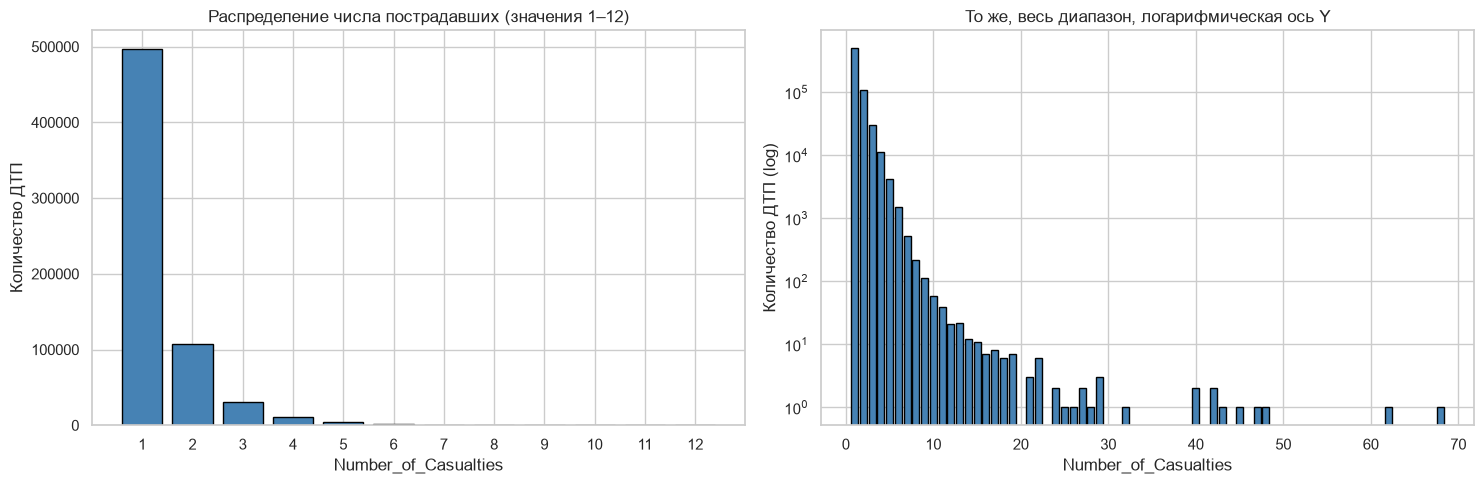

,count,mean,std,min,50%,75%,90%,99%,99.9%,max
Number_of_Casualties,652497.0,1.3603,0.8281,1.0,1.0,1.0,2.0,5.0,7.0,68.0


Доля ДТП по числу пострадавших, %:


Number_of_Casualties,1,2,3,4,5,6,7,8
"Доля, %",76.1,16.46,4.71,1.7,0.63,0.24,0.08,0.03


Среднее = 1.360, медиана = 1, дисперсия = 0.686, асимметрия = 7.02


In [6]:
target = "Number_of_Casualties"
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

counts = df[target].value_counts().sort_index()
axes[0].bar(counts.index[:12], counts.values[:12], color="steelblue", edgecolor="black")
axes[0].set_title("Распределение числа пострадавших (значения 1–12)")
axes[0].set_xlabel("Number_of_Casualties")
axes[0].set_ylabel("Количество ДТП")
axes[0].set_xticks(range(1, 13))

axes[1].bar(counts.index, counts.values, color="steelblue", edgecolor="black")
axes[1].set_yscale("log")
axes[1].set_title("То же, весь диапазон, логарифмическая ось Y")
axes[1].set_xlabel("Number_of_Casualties")
axes[1].set_ylabel("Количество ДТП (log)")
plt.tight_layout()
plt.show()

stats = df[target].describe(percentiles=[.5, .75, .9, .99, .999])
display(stats.rename("Number_of_Casualties").to_frame().T)
share = (counts / counts.sum() * 100).round(2)
print("Доля ДТП по числу пострадавших, %:")
display(share.head(8).rename("Доля, %").to_frame().T)
print(f"Среднее = {df[target].mean():.3f}, медиана = {df[target].median():.0f}, "
      f"дисперсия = {df[target].var():.3f}, асимметрия = {df[target].skew():.2f}")

Распределение `Number_of_Casualties` - **дискретное и резко правоскошенное**:
- **76.10 %** ДТП - с одним пострадавшим, 16.46 % - с двумя, 4.71 % - с тремя, 1.70 % - с четырьмя; ДТП с 8 пострадавшими - 0.03 %;
- среднее 1.360, медиана 1, 99-й перцентиль 5, 99.9-й - 7, максимум 68; асимметрия 7.02 (для симметричного распределения была бы около 0);
- на логарифмической оси видно «рассыпанный» длинный хвост: отдельные ДТП с 20-68 пострадавшими.

Выводы для регрессии: (1) целевая переменная не нормальна и не непрерывна - допущения МНК выполняются лишь приближённо; (2) мода равна 1, поэтому «умный» прогноз для типичного ДТП всегда будет около 1-1.4, а точность придётся оценивать осторожно; (3) редкие крупные аварии с большим числом пострадавших дают огромные остатки и сильно влияют на RMSE; (4) дисперсия (0.686) меньше среднего (1.360), то есть распределение не является пуассоновским - это важно, если задуматься о пуассоновской регрессии (см. дополнительный эксперимент в конце).

#### Числовые признаки

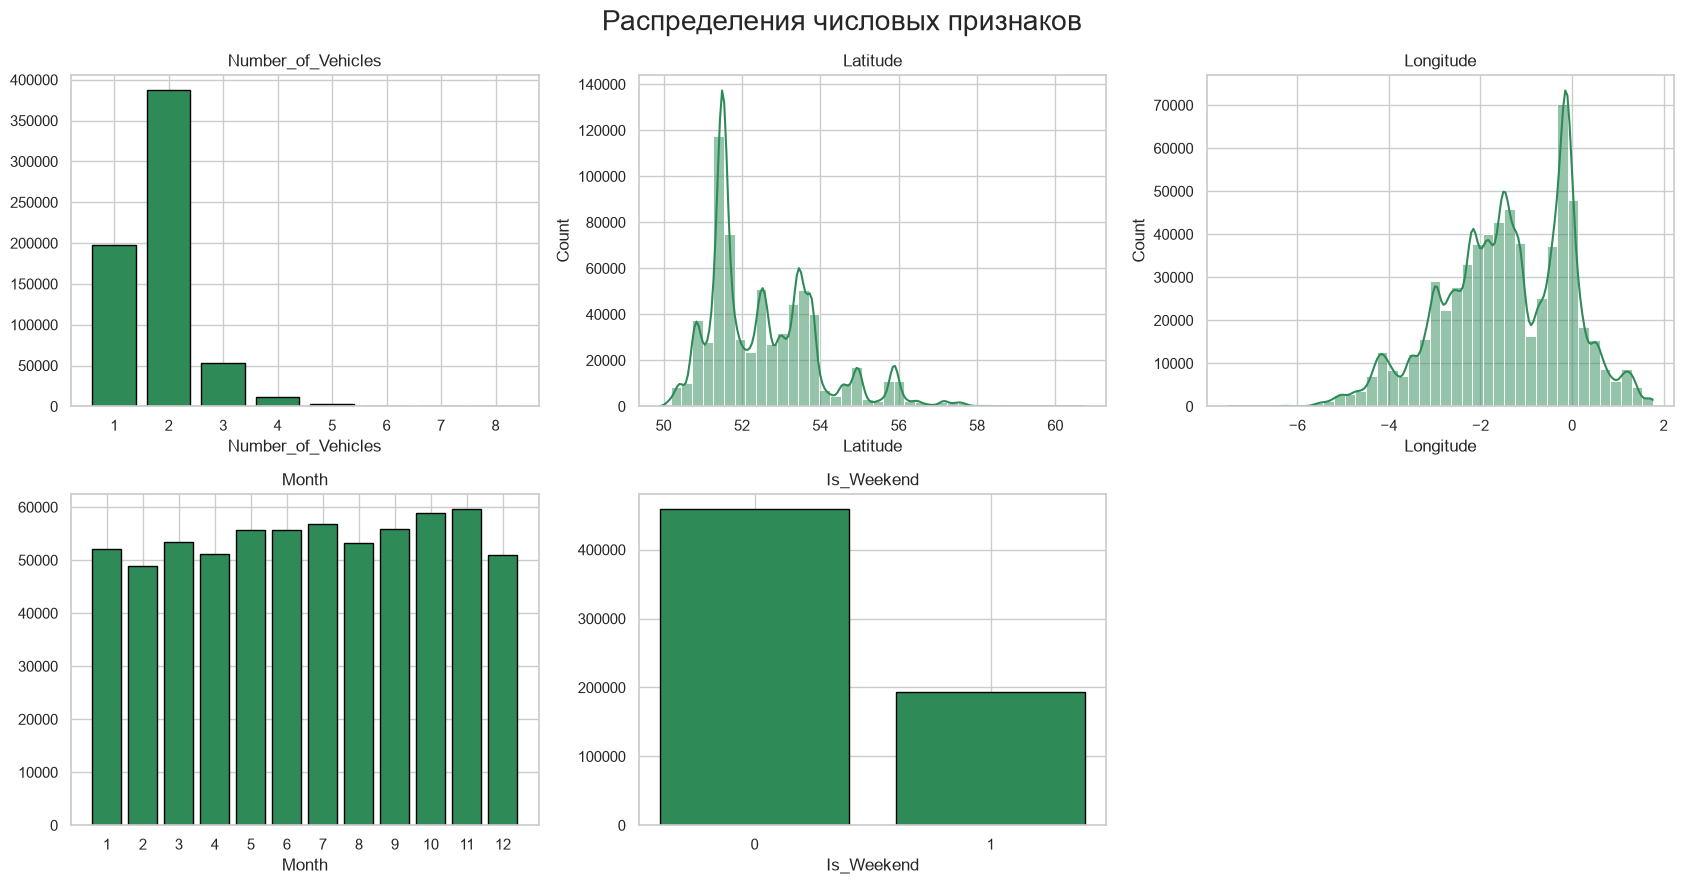

,count,mean,std,min,25%,50%,75%,max
Number_of_Vehicles,652497.0,1.8329,0.7171,1.0000,1.0000,2.0000,2.0000,32.0000
Latitude,652497.0,52.5546,1.4103,49.9144,51.4904,52.3051,53.4555,60.7575
Longitude,652497.0,-1.4256,1.3818,-7.5162,-2.3213,-1.4057,-0.2299,1.7620
Month,652497.0,6.6066,3.4190,1.0000,4.0000,7.0000,10.0000,12.0000
Is_Weekend,652497.0,0.2972,0.4570,0.0000,0.0000,0.0000,1.0000,1.0000


In [7]:
numeric_features = ["Number_of_Vehicles", "Latitude", "Longitude", "Month", "Is_Weekend"]
categorical_features = ["Light_Conditions", "Road_Surface_Conditions", "Road_Type",
                        "Urban_or_Rural_Area", "Weather_Conditions", "Vehicle_Type"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
fig.suptitle("Распределения числовых признаков", fontsize=20)
for ax, col in zip(axes.flat, numeric_features):
    if col in ("Is_Weekend", "Number_of_Vehicles", "Month"):
        vc = df[col].value_counts().sort_index()
        vc = vc[vc.index <= 8] if col == "Number_of_Vehicles" else vc
        ax.bar(vc.index.astype(int), vc.values, color="seagreen", edgecolor="black")
        ax.set_xticks(vc.index.astype(int))
    else:
        sns.histplot(df[col], bins=40, kde=True, ax=ax, color="seagreen")
    ax.set_title(col)
    ax.set_xlabel(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

display(df[numeric_features].describe().T)

- **`Number_of_Vehicles`**: пик на 2 машинах (около 387 тыс. ДТП), далее 1 машина (около 198 тыс.), 3 машины (около 53 тыс.); распределение резко убывает, ДТП с 5 и более машинами исчезающе редки. Среднее 1.83, максимум 32.
- **`Latitude`**: многовершинное распределение с главным пиком около 51.5° (Лондон) и локальными максимумами вблизи 52.5° (Бирмингем), 53.5° (Манчестер/Ливерпуль) и 55.9° (Эдинбург/Глазго) - отражает плотность населения, а не «нормальность» величины. Среднее 52.55.
- **`Longitude`**: пик около 0° (Лондон), второй широкий горб около -1.5…-2.5° (Мидлендс, север Англии); хвост влево до -7.5° (Корнуолл, Уэльс, Шотландия).
- **`Month`**: ДТП распределены по месяцам довольно равномерно (от ~48.9 тыс. в феврале до ~59.6 тыс. в ноябре), заметна лишь небольшая сезонность.
- **`Is_Weekend`**: 29.7 % ДТП приходятся на субботу-воскресенье (при 2/7 ≈ 28.6 % дней), то есть выходные не «опаснее» по частоте аварий.

Таблица ниже графиков подтверждает диапазоны: ни один числовой признак не содержит нереалистичных значений.

#### Категориальные признаки

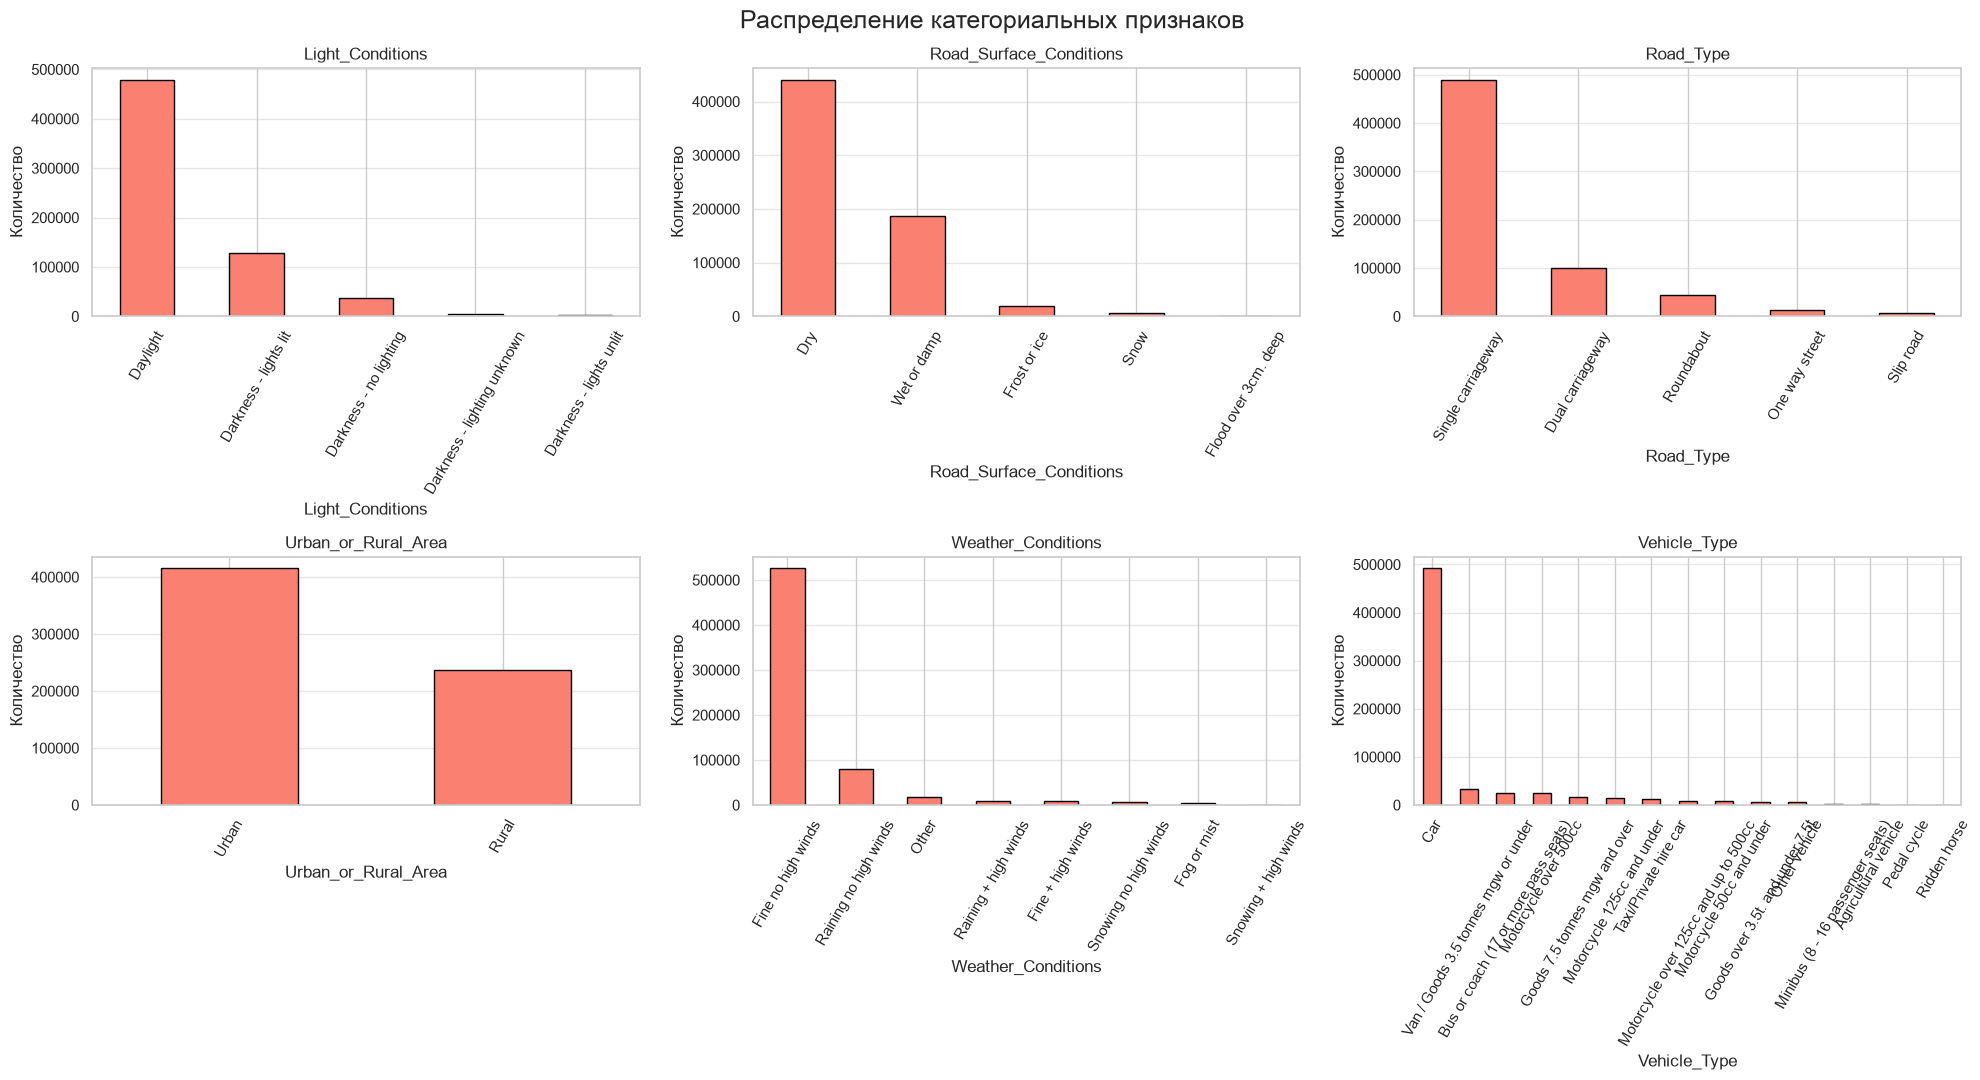

Light_Conditions (5 категорий):


,Количество,"Доля, %"
Light_Conditions,,
Daylight,479026,73.41
Darkness - lights lit,128720,19.73
Darkness - no lighting,37400,5.73
Darkness - lighting unknown,4841,0.74
Darkness - lights unlit,2510,0.38


Road_Surface_Conditions (5 категорий):


,Количество,"Доля, %"
Road_Surface_Conditions,,
Dry,440526,67.51
Wet or damp,186573,28.59
Frost or ice,18502,2.84
Snow,5894,0.90
Flood over 3cm. deep,1002,0.15


Road_Type (5 категорий):


...

,Количество,"Доля, %"
Urban_or_Rural_Area,,
Urban,415084,63.61
Rural,237413,36.39


Weather_Conditions (8 категорий):


,Количество,"Доля, %"
Weather_Conditions,,
Fine no high winds,525726,80.57
Raining no high winds,80441,12.33
Other,17244,2.64
Raining + high winds,9699,1.49
Fine + high winds,8638,1.32
Snowing no high winds,6308,0.97
Fog or mist,3552,0.54
Snowing + high winds,889,0.14


Vehicle_Type (15 категорий):


,Количество,"Доля, %"
Vehicle_Type,,
Car,491788,75.37
Van / Goods 3.5 tonnes mgw or under,33772,5.18
Bus or coach (17 or more pass seats),25533,3.91
Motorcycle over 500cc,25349,3.88
Goods 7.5 tonnes mgw and over,17124,2.62
Motorcycle 125cc and under,15057,2.31
Taxi/Private hire car,13132,2.01
Motorcycle over 125cc and up to 500cc,7563,1.16
Motorcycle 50cc and under,7551,1.16


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Распределение категориальных признаков", fontsize=18)
for ax, col in zip(axes.flat, categorical_features):
    df[col].value_counts().plot(kind="bar", ax=ax, color="salmon", edgecolor="black")
    ax.set_title(col)
    ax.set_ylabel("Количество")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.5)
plt.tight_layout()
plt.show()

for col in categorical_features:
    freq = df[col].value_counts()
    print(f"{col} ({len(freq)} категорий):")
    display(pd.DataFrame({"Количество": freq, "Доля, %": freq / len(df) * 100}).round(2))

Практически все категориальные признаки **сильно несбалансированы** - одна категория занимает от 63 % до 81 % наблюдений:
- `Light_Conditions`: Daylight - **73.41 %**, Darkness - lights lit - 19.73 %, Darkness - no lighting - 5.73 %; остальные две темноты - менее 1 %;
- `Road_Surface_Conditions`: Dry - **67.51 %**, Wet or damp - 28.59 %, Frost or ice - 2.84 %, Snow - 0.90 %, Flood - 0.15 %;
- `Road_Type`: Single carriageway - **75.03 %**, Dual carriageway - 15.19 %, Roundabout - 6.65 %, One way street - 2.06 %, Slip road - 1.07 %;
- `Urban_or_Rural_Area`: Urban - **63.61 %**, Rural - 36.39 %;
- `Weather_Conditions`: Fine no high winds - **80.57 %**, Raining no high winds - 12.33 %, Other - 2.64 %, остальные 5 категорий - от 0.14 % до 1.49 %;
- `Vehicle_Type`: Car - **75.37 %** (491 788 ДТП), далее фургоны 5.2 %, автобусы 3.9 %, мотоциклы свыше 500 см³ 3.9 %; **«Ridden horse» всего 4 записи**, «Pedal cycle» - 192.

Эти доли определяют выбор **базовой категории** при кодировании: за базу взята самая частая категория каждого признака (Daylight, Dry, Single carriageway, Urban, Fine no high winds, Car). Редкие категории (всадник на лошади - 4 наблюдения) получают ненадёжные коэффициенты - при кодировании используется `handle_unknown="ignore"`, чтобы незнакомая категория в новой выборке не приводила к ошибке.

#### Зависимость целевой переменной от признаков

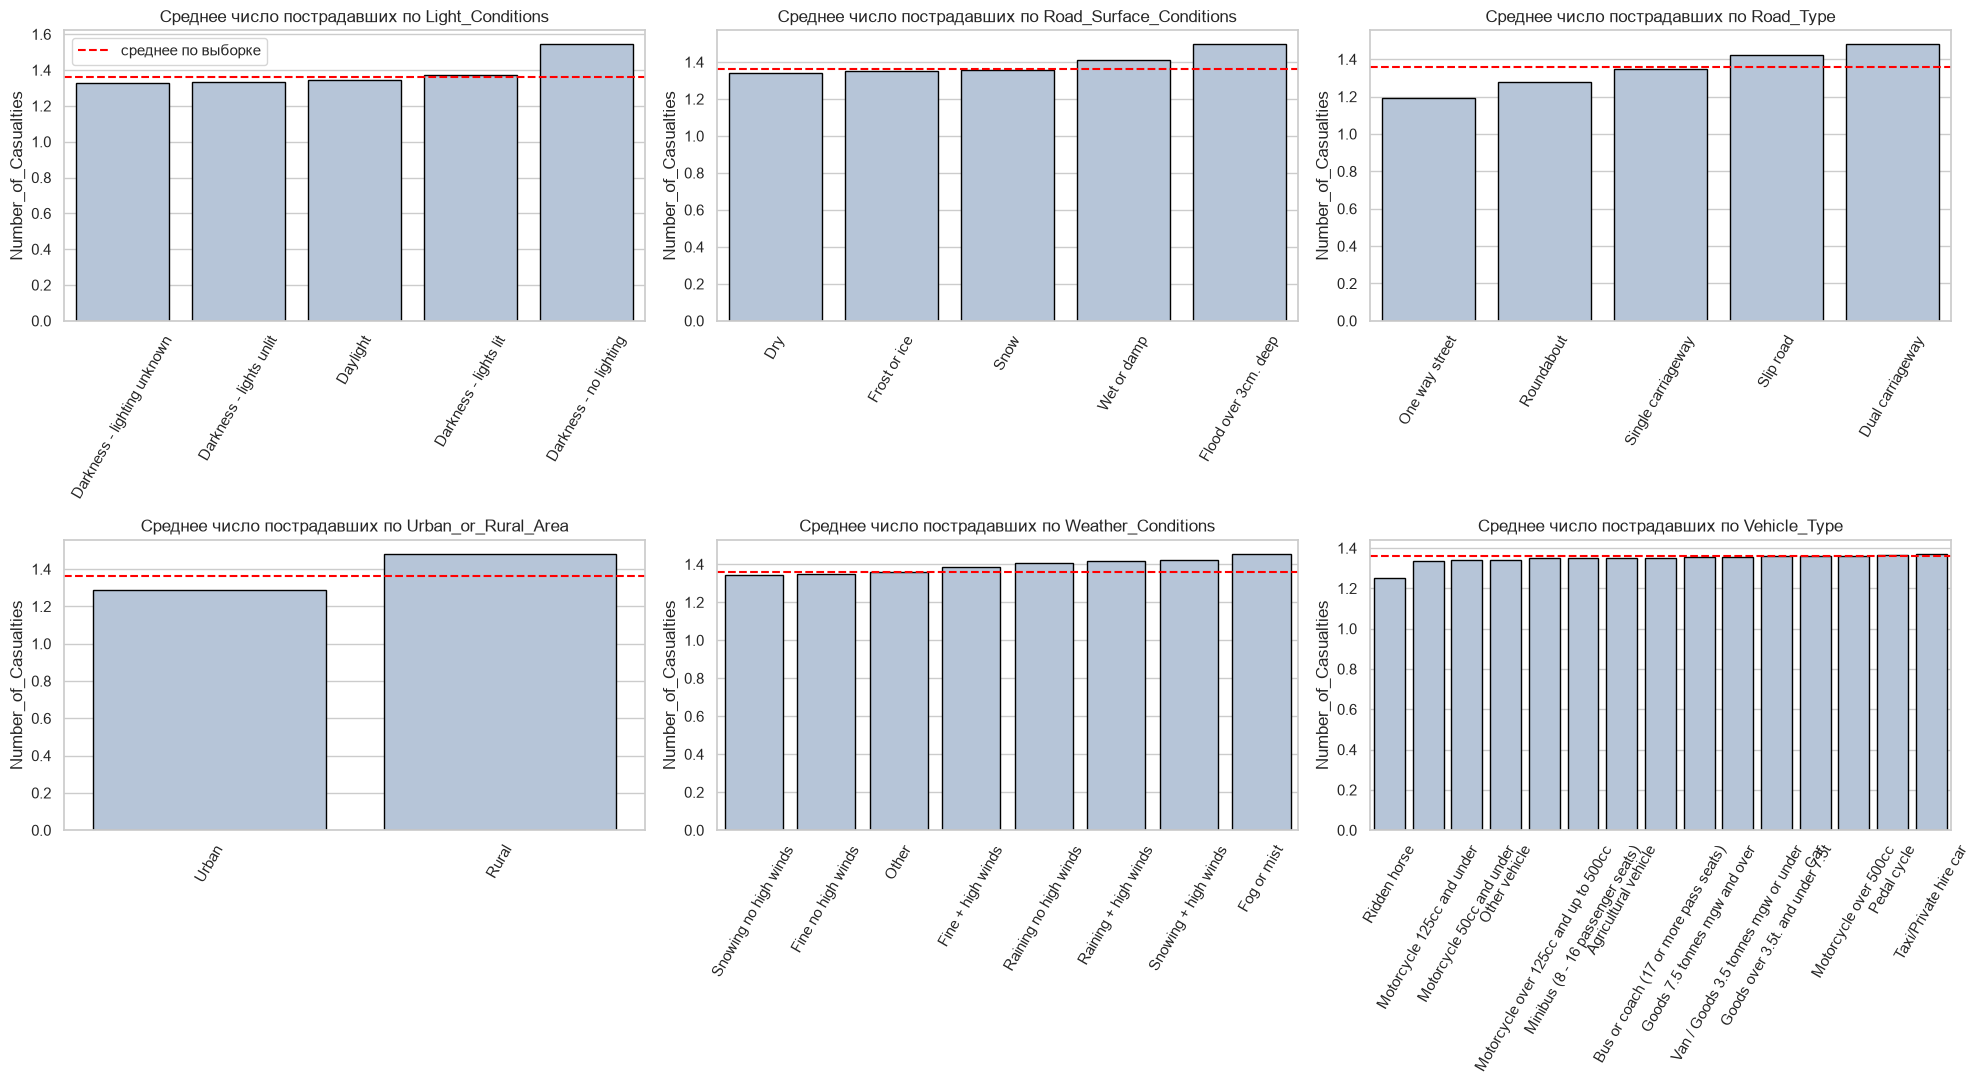

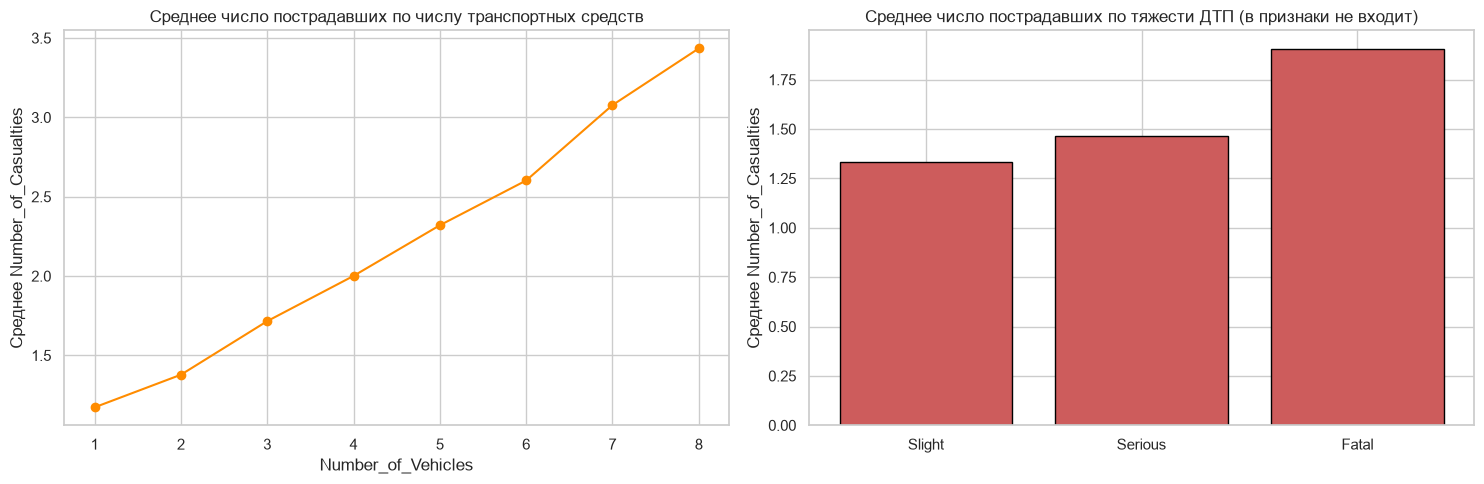

Среднее число пострадавших по числу ТС (1–8):


Number_of_Vehicles,1,2,3,4,5,6,7,8
Среднее,1.173,1.378,1.716,2.001,2.32,2.602,3.077,3.434


Среднее число пострадавших по тяжести ДТП:


Accident_Severity,Slight,Serious,Fatal
Среднее,1.331,1.466,1.904



Light_Conditions:


...

,count,mean,median
Road_Type,,,
Dual carriageway,99110,1.480,1.0
Slip road,6994,1.425,1.0
Single carriageway,489563,1.347,1.0
Roundabout,43401,1.277,1.0
One way street,13429,1.194,1.0



Urban_or_Rural_Area:


,count,mean,median
Urban_or_Rural_Area,,,
Rural,237413,1.483,1.0
Urban,415084,1.290,1.0



Vehicle_Type:


,count,mean,median
Vehicle_Type,,,
Taxi/Private hire car,13132,1.372,1.0
Pedal cycle,192,1.365,1.0
Motorcycle over 500cc,25349,1.363,1.0
Car,491788,1.362,1.0
Goods over 3.5t. and under 7.5t,6029,1.360,1.0
Van / Goods 3.5 tonnes mgw or under,33772,1.357,1.0
Goods 7.5 tonnes mgw and over,17124,1.355,1.0
Bus or coach (17 or more pass seats),25533,1.352,1.0
Agricultural vehicle,1925,1.349,1.0


In [9]:
# Связь целевой переменной с признаками: средние значения по группам
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, col in zip(axes.flat, categorical_features):
    order = df.groupby(col)[target].mean().sort_values().index
    try:
        sns.barplot(data=df, x=col, y=target, order=order, ax=ax, color="lightsteelblue",
                    errorbar=None, edgecolor="black")
    except TypeError:                      # seaborn < 0.12 не знает параметра errorbar
        sns.barplot(data=df, x=col, y=target, order=order, ax=ax, color="lightsteelblue",
                    ci=None, edgecolor="black")
    ax.axhline(df[target].mean(), color="red", linestyle="--", label="среднее по выборке")
    ax.set_title(f"Среднее число пострадавших по {col}")
    ax.tick_params(axis="x", rotation=60)
    ax.set_xlabel("")
axes.flat[0].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
by_veh = df[df["Number_of_Vehicles"] <= 8].groupby("Number_of_Vehicles")[target].mean()
axes[0].plot(by_veh.index, by_veh.values, marker="o", color="darkorange")
axes[0].set_title("Среднее число пострадавших по числу транспортных средств")
axes[0].set_xlabel("Number_of_Vehicles")
axes[0].set_ylabel("Среднее Number_of_Casualties")
sev = df_raw.loc[df_raw["Number_of_Casualties"] >= 1].groupby("Accident_Severity")[target].mean()
sev = sev.reindex(["Slight", "Serious", "Fatal"])
axes[1].bar(sev.index, sev.values, color="indianred", edgecolor="black")
axes[1].set_title("Среднее число пострадавших по тяжести ДТП (в признаки не входит)")
axes[1].set_ylabel("Среднее Number_of_Casualties")
plt.tight_layout()
plt.show()

print("Среднее число пострадавших по числу ТС (1–8):")
display(by_veh.round(3).rename("Среднее").to_frame().T)
print("Среднее число пострадавших по тяжести ДТП:")
display(sev.round(3).rename("Среднее").to_frame().T)
for col in ["Light_Conditions", "Road_Type", "Urban_or_Rural_Area", "Vehicle_Type"]:
    print(f"\n{col}:")
    display(df.groupby(col)[target].agg(["count", "mean", "median"]).sort_values("mean", ascending=False).round(3))

Средние значения `Number_of_Casualties` по группам показывают, какие признаки действительно связаны с целью:

- **Число транспортных средств** - самая сильная и монотонная связь: 1 ТС - 1.17 пострадавших, 2 - 1.38, 3 - 1.72, 4 - 2.00, 5 - 2.32, 6 - 2.60, 7 - 3.08, 8 - 3.43. Чем больше машин, тем больше людей пострадало, почти линейно (каждая добавленная машина даёт примерно +0.3 пострадавших).
- **Город / село**: в сельской местности (Rural) в среднем 1.483 пострадавших, в городе 1.290. Селькие дороги - более высокие скорости и тяжёлые аварии.
- **Освещение**: темнота без освещения (Darkness - no lighting) - 1.544, это заметно выше, чем при дневном свете (1.343) и при освещённой дороге ночью (1.372).
- **Тип дороги**: двухполосная дорога (Dual carriageway) - 1.480, примыкание (Slip road) - 1.425, одна проезжая часть - 1.347, кольцо - 1.277, дорога с односторонним движением - 1.194 (самое низкое значение).
- **Тип ТС**: различия минимальны (1.34-1.37 для всех групп, у «Ridden horse» всего 4 записи, поэтому его среднее 1.25 не показательно) - тип транспортного средства почти не влияет на число пострадавших.
- **Тяжесть ДТП** (на график вынесена только для анализа): Slight - 1.331, Serious - 1.466, Fatal - 1.904, то есть более тяжёлые ДТП связаны с большим числом пострадавших, но связь умеренная.

Предварительно: основной «ценообразующий» признак - `Number_of_Vehicles`, далее - сельская местность, освещённость и тип дороги; остальные факторы (погода, покрытие, тип ТС, месяц) дают малые различия, поэтому качество линейной модели заведомо будет ограниченным.

#### Выбросы

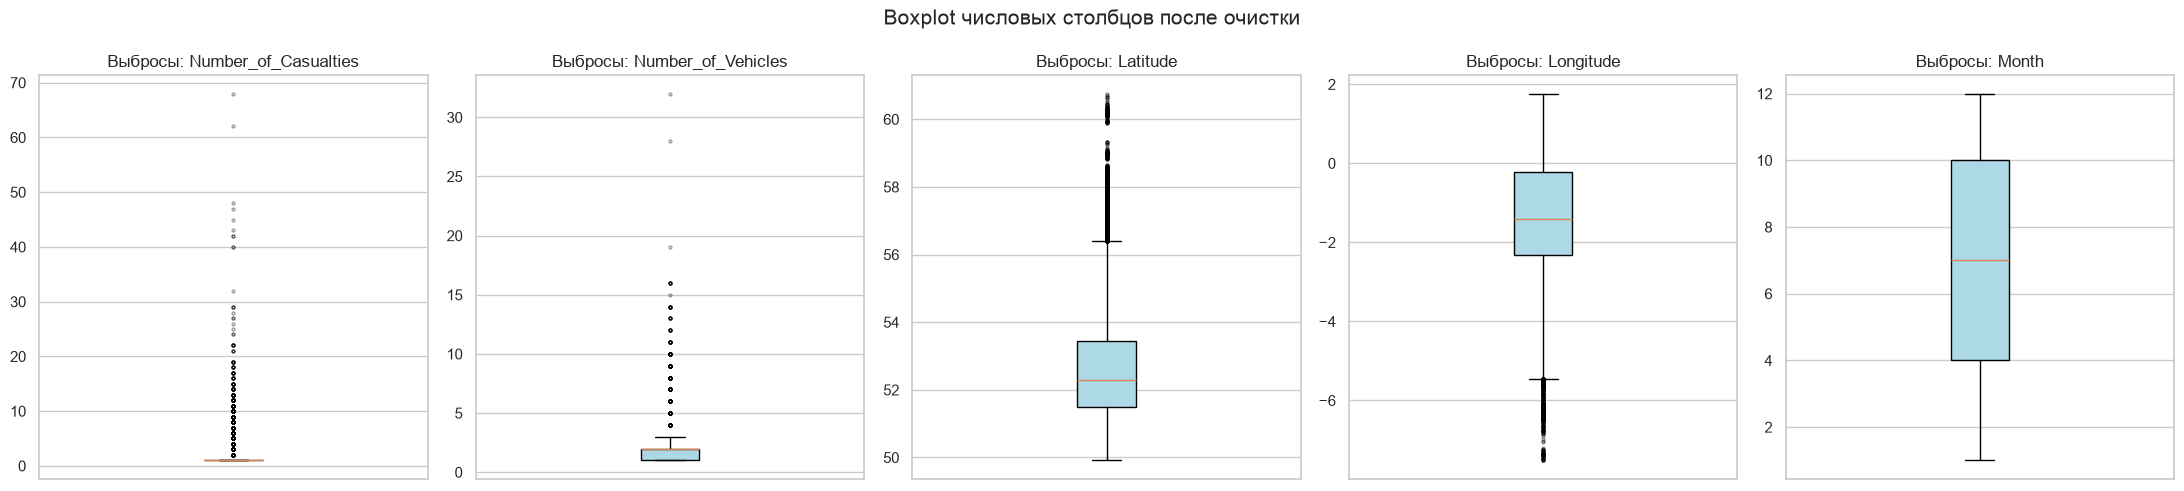

,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Значений вне границ,"Доля, %",Максимум
Признак,,,,,,,,
Number_of_Casualties,1.000,1.000,0.000,1.000,1.000,155971,23.904,68.000
Number_of_Vehicles,1.000,2.000,1.000,-0.500,3.500,15034,2.304,32.000
Latitude,51.490,53.456,1.965,48.543,56.403,8569,1.313,60.758
Longitude,-2.321,-0.230,2.091,-5.458,2.907,1075,0.165,1.762
Month,4.000,10.000,6.000,-5.000,19.000,0,0.000,12.000


Хвосты целевой переменной и числа ТС:
  Number_of_Casualties > 5:  2,619 строк (0.401 %)
  Number_of_Casualties > 10:    163 строк (0.025 %)
  Number_of_Casualties > 20:     30 строк (0.005 %)
  Number_of_Vehicles > 5:  1,323 строк (0.203 %)
  Number_of_Vehicles > 10:     44 строк (0.007 %)
  Number_of_Vehicles > 20:      2 строк (0.000 %)

География (UK: широта ≈ 49.9–60.9, долгота ≈ −8.7…1.8):
  Latitude  [49.914; 60.758]
  Longitude [-7.516; 1.762]


In [10]:
if "df" not in globals():
    raise NameError("Нет датафрейма df: сначала выполните ячейки загрузки и очистки данных (запуск сверху вниз).")

outlier_features = ["Number_of_Casualties", "Number_of_Vehicles", "Latitude", "Longitude", "Month"]

# Boxplot построен средствами matplotlib (не зависит от версии seaborn)
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, col in zip(axes, outlier_features):
    ax.boxplot(df[col].to_numpy(), patch_artist=True,
               boxprops=dict(facecolor="lightblue"),
               flierprops=dict(marker="o", markersize=2, alpha=0.4))
    ax.set_title(f"Выбросы: {col}")
    ax.set_xticks([])
plt.suptitle("Boxplot числовых столбцов после очистки", fontsize=15)
plt.tight_layout()
plt.show()

iqr_rows = []
for col in outlier_features:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    iqr_rows.append({"Признак": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                     "Нижняя граница": lower, "Верхняя граница": upper,
                     "Значений вне границ": int(mask.sum()), "Доля, %": mask.mean() * 100,
                     "Максимум": df[col].max()})
iqr_summary = pd.DataFrame(iqr_rows).set_index("Признак")
display(iqr_summary.round(3))

print("Хвосты целевой переменной и числа ТС:")
for col in ["Number_of_Casualties", "Number_of_Vehicles"]:
    for thr in (5, 10, 20):
        share = (df[col] > thr).mean() * 100
        print(f"  {col} > {thr}: {int((df[col] > thr).sum()):>6,} строк ({share:.3f} %)")
print("\nГеография (UK: широта ≈ 49.9–60.9, долгота ≈ −8.7…1.8):")
print(f"  Latitude  [{df['Latitude'].min():.3f}; {df['Latitude'].max():.3f}]")
print(f"  Longitude [{df['Longitude'].min():.3f}; {df['Longitude'].max():.3f}]")

Выбросы исследованы boxplot-ами и правилом 1.5·IQR (значения вне [Q1 - 1.5·IQR; Q3 + 1.5·IQR]):

- **`Number_of_Casualties`**: Q1 = Q3 = 1, IQR = 0, поэтому границы вырождаются в [1; 1], и правило 1.5·IQR помечает все значения больше 1 (155 971 строка, 23.9 %) как выбросы. Это артефакт метода: для дискретной, почти константной величины IQR не годится. Содержательно истинные «хвосты» гораздо мельче: ДТП с > 5 пострадавшими - 2 619 (0.40 %), с > 10 - 163 (0.025 %), с > 20 - 30 (0.005 %).
- **`Number_of_Vehicles`**: границы [-0.5; 3.5], вне границ 15 034 строки (2.30 %); максимум 32 машины. С > 5 машинами - 1 323 строки (0.20 %), с > 10 - 44.
- **`Latitude`**: границы [48.54; 56.40], вне границ 8 569 (1.31 %) - это шотландские ДТП севернее 56.4°; **`Longitude`**: 1 075 (0.17 %) - западные регионы. Это реальные, а не ошибочные точки: все координаты лежат внутри территории Великобритании.
- **`Month`**: выбросов нет (значения 1-12).

**Решение: выбросы не удаляются.** Причины: (1) большие значения целевой переменной и числа машин - реальные редкие события (массовые аварии), а не ошибки ввода; ошибочных значений (нулевых, отрицательных, нереалистичных координат) нет; (2) их доля мизерна (< 0.5 %), но они информативны для мультиколлинеарности не вызывают; (3) удаление хвоста целевой переменной искусственно «облегчило» бы задачу и скрыло реальную сложность. Мы лишь учитываем в интерпретации, что RMSE чувствителен к этим редким большим ошибкам (см. остатки ниже).

### Корреляционная матрица и мультиколлинеарность

#### Кодирование категориальных признаков

In [11]:
# Кодирование для корреляций и VIF: one-hot. Из каждой группы dummy исключается одна БАЗОВАЯ категория
# (иначе столбцы линейно зависимы: сумма dummy группы = 1 = константа). Базой выбрана САМАЯ ЧАСТАЯ категория:
# так коэффициенты читаются как отличие от «типичного» ДТП (Car, Daylight, Dry, ...), а VIF не искажается редкой базой.
X_all = df.drop(columns=target)
base = {col: df[col].value_counts().idxmax() for col in categorical_features}
X_enc = pd.get_dummies(X_all, columns=categorical_features, dtype=float)
X_enc = X_enc.drop(columns=[f"{col}_{cat}" for col, cat in base.items()])
df_enc = pd.concat([X_enc, df[target]], axis=1)

# Для сравнения: вариант «база = первая по алфавиту» (поведение drop_first=True)
X_enc_alpha = pd.get_dummies(X_all, columns=categorical_features, drop_first=True, dtype=float)

print(f"Признаков после one-hot кодирования: {X_enc.shape[1]}  (числовых {len(numeric_features)} + dummy {X_enc.shape[1] - len(numeric_features)})")
print("Базовые (исключённые) категории:")
for col, cat in base.items():
    print(f"  {col}: {cat}  ({(df[col] == cat).mean():.1%} наблюдений)")
display(df_enc.head())

Признаков после one-hot кодирования: 39  (числовых 5 + dummy 34)
Базовые (исключённые) категории:
  Light_Conditions: Daylight  (73.4% наблюдений)
  Road_Surface_Conditions: Dry  (67.5% наблюдений)
  Road_Type: Single carriageway  (75.0% наблюдений)
  Urban_or_Rural_Area: Urban  (63.6% наблюдений)
  Weather_Conditions: Fine no high winds  (80.6% наблюдений)
  Vehicle_Type: Car  (75.4% наблюдений)


,Latitude,Longitude,Number_of_Vehicles,Month,Is_Weekend,Light_Conditions_Darkness - lighting unknown,Light_Conditions_Darkness - lights lit,Light_Conditions_Darkness - lights unlit,Light_Conditions_Darkness - no lighting,Road_Surface_Conditions_Flood over 3cm. deep,Road_Surface_Conditions_Frost or ice,Road_Surface_Conditions_Snow,Road_Surface_Conditions_Wet or damp,Road_Type_Dual carriageway,Road_Type_One way street,Road_Type_Roundabout,Road_Type_Slip road,Urban_or_Rural_Area_Rural,Weather_Conditions_Fine + high winds,Weather_Conditions_Fog or mist,Weather_Conditions_Other,Weather_Conditions_Raining + high winds,Weather_Conditions_Raining no high winds,Weather_Conditions_Snowing + high winds,Weather_Conditions_Snowing no high winds,Vehicle_Type_Agricultural vehicle,Vehicle_Type_Bus or coach (17 or more pass seats),Vehicle_Type_Goods 7.5 tonnes mgw and over,Vehicle_Type_Goods over 3.5t. and under 7.5t,Vehicle_Type_Minibus (8 - 16 passenger seats),Vehicle_Type_Motorcycle 125cc and under,Vehicle_Type_Motorcycle 50cc and under,Vehicle_Type_Motorcycle over 125cc and up to 500cc,Vehicle_Type_Motorcycle over 500cc,Vehicle_Type_Other vehicle,Vehicle_Type_Pedal cycle,Vehicle_Type_Ridden horse,Vehicle_Type_Taxi/Private hire car,Vehicle_Type_Van / Goods 3.5 tonnes mgw or under,Number_of_Casualties
0,51.5062,-0.2091,2,6,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,51.4950,-0.1736,2,7,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2,51.4955,-0.2027,4,8,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,51.4978,-0.1926,3,9,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,51.5014,-0.1616,2,9,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1


Категориальные признаки закодированы **One-Hot Encoding** (каждая категория - отдельный бинарный столбец). Почему не порядковое (label) кодирование: все шесть признаков **номинальные** (у `Weather_Conditions`, `Vehicle_Type`, `Road_Type` нет естественного порядка), присвоение номеров 0, 1, 2... навязало бы модели несуществующую упорядоченность и «равные расстояния» между категориями. One-hot этого не делает.

Из каждой группы dummy-столбцов исключена **одна базовая категория** (иначе сумма столбцов группы равна единице, то есть константе, - «ловушка дамми-переменных», точная линейная зависимость). Базой выбрана самая частая категория: Light_Conditions - Daylight (73.4 %), Road_Surface_Conditions - Dry (67.5 %), Road_Type - Single carriageway (75.0 %), Urban_or_Rural_Area - Urban (63.6 %), Weather_Conditions - Fine no high winds (80.6 %), Vehicle_Type - Car (75.4 %). Так каждый коэффициент читается как «отличие от типичного ДТП».

Итог: **39 признаков = 5 числовых + 34 dummy** (4 + 4 + 4 + 1 + 7 + 14).

#### Корреляции числовых признаков

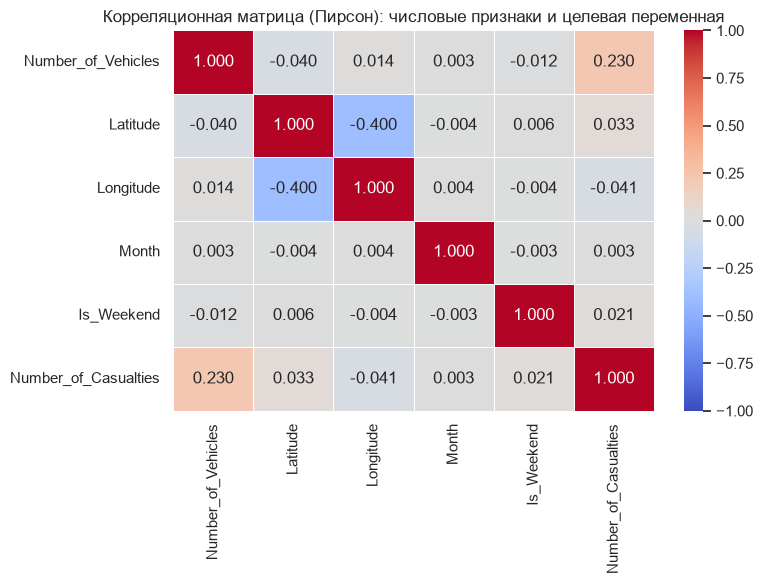

,Пирсон,Спирмен
Number_of_Vehicles,0.2300,0.2266
Latitude,0.0326,0.0478
Longitude,-0.0409,-0.0486
Month,0.0034,0.0021
Is_Weekend,0.0208,0.0198


In [12]:
# Корреляционная матрица Пирсона: числовые признаки + целевая переменная
num_cols = numeric_features + [target]
corr_num = df[num_cols].corr(method="pearson")
plt.figure(figsize=(8, 6))
sns.heatmap(corr_num, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Корреляционная матрица (Пирсон): числовые признаки и целевая переменная")
plt.tight_layout()
plt.show()

# Сравнение Пирсона и Спирмена для связи с целевой переменной (целевая переменная дискретна и скошена)
cmp_corr = pd.DataFrame({
    "Пирсон": df[num_cols].corr(method="pearson")[target],
    "Спирмен": df[num_cols].corr(method="spearman")[target],
}).drop(target)
display(cmp_corr.round(4))

Использован коэффициент **Пирсона** (`method="pearson"`): он измеряет именно **линейную** связь, которую и предполагает линейная регрессия, поэтому подходит для первичной оценки. Для контроля рассчитан и ранговый коэффициент Спирмена - значения практически совпадают (для `Number_of_Vehicles` 0.230 и 0.227), что показывает: на оценку связи не влияют выбросы и скошенность целевой переменной.

Корреляции признаков с целью (Пирсон):
- `Number_of_Vehicles` - **+0.230** (самая сильная связь, слабая по шкале Чеддока, но на фоне остальных - доминирующая);
- `Longitude` - -0.041, `Latitude` - +0.033, `Is_Weekend` - +0.021, `Month` - +0.003 (практически нулевая).

Корреляции между числовыми признаками: `Latitude`-`Longitude` = -0.40 (географическая закономерность: север Британии - западнее), остальные пары близки к нулю. Сильных пар числовых признаков нет.

#### Полная корреляционная матрица (все закодированные признаки)

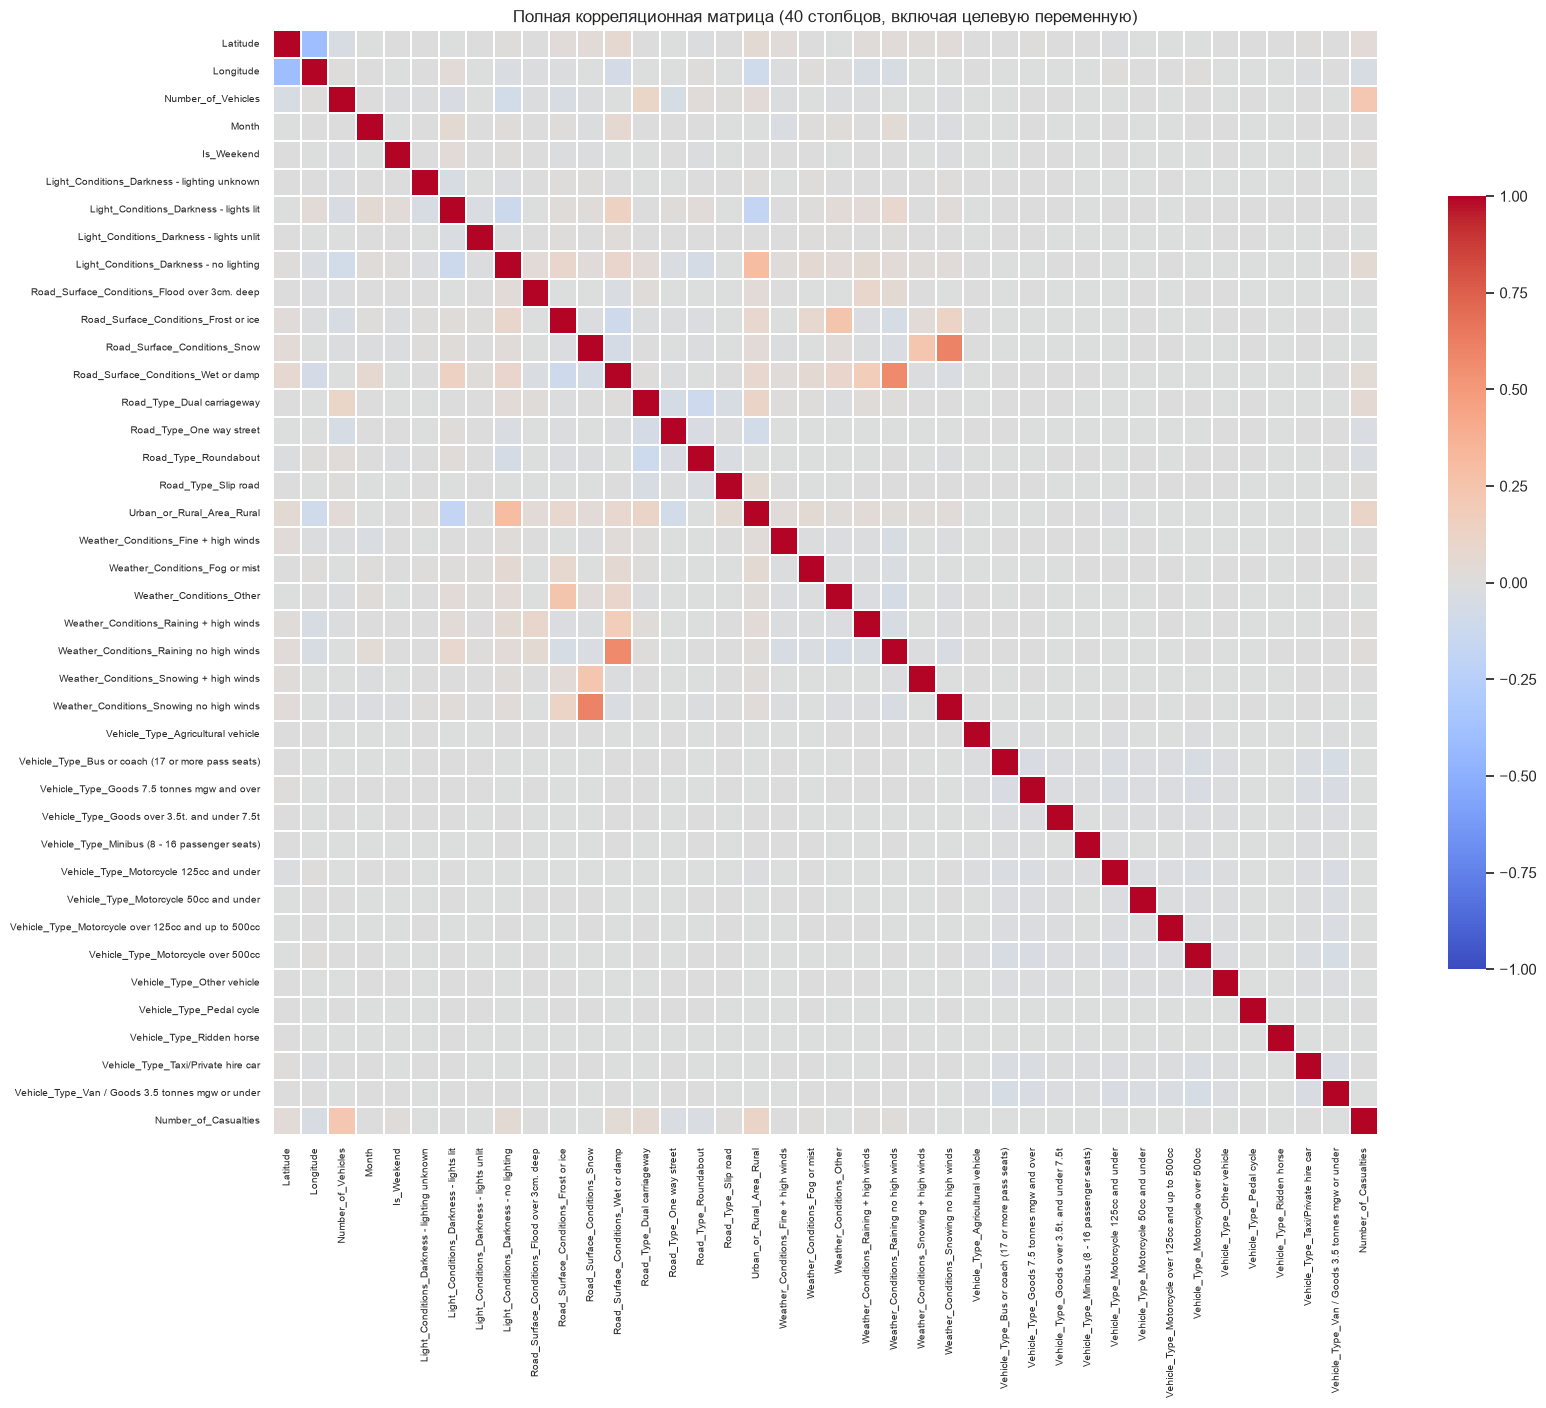

Топ-12 пар признаков по модулю корреляции:


,Признак 1,Признак 2,Корреляция
0,Road_Surface_Conditions_Snow,Weather_Conditions_Snowing no high winds,0.6029
1,Road_Surface_Conditions_Wet or damp,Weather_Conditions_Raining no high winds,0.5760
2,Latitude,Longitude,-0.4001
3,Light_Conditions_Darkness - no lighting,Urban_or_Rural_Area_Rural,0.3005
4,Road_Surface_Conditions_Frost or ice,Weather_Conditions_Other,0.2458
5,Road_Surface_Conditions_Snow,Weather_Conditions_Snowing + high winds,0.2393
6,Road_Surface_Conditions_Wet or damp,Weather_Conditions_Raining + high winds,0.1820
7,Light_Conditions_Darkness - lights lit,Urban_or_Rural_Area_Rural,-0.1775
8,Light_Conditions_Darkness - lights lit,Road_Surface_Conditions_Wet or damp,0.1344
9,Light_Conditions_Darkness - lights lit,Light_Conditions_Darkness - no lighting,-0.1222


Пар с |r| > 0.7: 0;  с |r| > 0.5: 2

Корреляция признаков с целевой переменной Number_of_Casualties (топ-12 по модулю):


,Корреляция с целевой
Number_of_Vehicles,0.2300
Urban_or_Rural_Area_Rural,0.1116
Road_Type_Dual carriageway,0.0611
Light_Conditions_Darkness - no lighting,0.0547
Longitude,-0.0409
Road_Surface_Conditions_Wet or damp,0.0401
Latitude,0.0326
Road_Type_One way street,-0.0291
Road_Type_Roundabout,-0.0269
Weather_Conditions_Raining no high winds,0.0218


In [13]:
# Полная матрица: все столбцы после кодирования (признаки + dummy + целевая переменная)
corr_matrix = df_enc.corr(method="pearson")
plt.figure(figsize=(17, 14))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, linewidths=0.2,
            cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.title(f"Полная корреляционная матрица ({corr_matrix.shape[0]} столбцов, включая целевую переменную)")
plt.tight_layout()
plt.show()

# Самые сильные пары между ПРИЗНАКАМИ (без целевой переменной)
feat_corr = corr_matrix.drop(index=target, columns=target)
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
         .stack().rename("Корреляция").reset_index())
pairs.columns = ["Признак 1", "Признак 2", "Корреляция"]
pairs["|r|"] = pairs["Корреляция"].abs()
print("Топ-12 пар признаков по модулю корреляции:")
display(pairs.sort_values("|r|", ascending=False).head(12).drop(columns="|r|").reset_index(drop=True).round(4))
print(f"Пар с |r| > 0.7: {(pairs['|r|'] > 0.7).sum()};  с |r| > 0.5: {(pairs['|r|'] > 0.5).sum()}")

price_corr = corr_matrix[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False)
print("\nКорреляция признаков с целевой переменной Number_of_Casualties (топ-12 по модулю):")
display(price_corr.head(12).rename("Корреляция с целевой").to_frame().round(4))

Матрица содержит **40 столбцов**: 5 числовых, 34 dummy и целевая переменная. Выводы:

**Между признаками** самые сильные связи - содержательно объяснимые пары dummy:
- `Road_Surface_Conditions_Snow` и `Weather_Conditions_Snowing no high winds`: **+0.603** (снег на дороге - при снегопаде);
- `Road_Surface_Conditions_Wet or damp` и `Weather_Conditions_Raining no high winds`: **+0.576** (мокрая дорога - при дожде);
- `Latitude` и `Longitude`: -0.400; `Light_Conditions_Darkness - no lighting` и `Urban_or_Rural_Area_Rural`: +0.301 (неосвещённые дороги - в сельской местности).
Пар с |r| > 0.7 **нет**, с |r| > 0.5 - только две. Для сравнения, в «классических» задачах с мультиколлинеарностью встречаются коэффициенты 0.9 и выше. Самая сильная **отрицательная** корреляция между признаками: `Latitude` - `Longitude` (-0.400).

**С целевой переменной** (топ): `Number_of_Vehicles` +0.230, `Urban_or_Rural_Area_Rural` +0.112, `Road_Type_Dual carriageway` +0.061, `Light_Conditions_Darkness - no lighting` +0.055, `Longitude` -0.041, `Road_Surface_Conditions_Wet or damp` +0.040. Все связи слабые (|r| < 0.25), поэтому ожидается низкий R².

**Вывод по корреляциям:** явной мультиколлинеарности нет; наибольшая зависимость - внутри групп «снег/снегопад» и «дождь/мокрая дорога» (0.58-0.60), но она умеренная. Проверим это строго через VIF.

### Проверка мультиколлинеарности с помощью VIF

VIF (база = самая частая категория) рассчитан для 39 признаков. Топ-15:


,Признак,VIF
0,Road_Surface_Conditions_Wet or damp,1.815
1,Road_Surface_Conditions_Snow,1.797
2,Weather_Conditions_Snowing no high winds,1.710
3,Weather_Conditions_Raining no high winds,1.648
4,Longitude,1.204
5,Latitude,1.199
6,Urban_or_Rural_Area_Rural,1.177
7,Road_Surface_Conditions_Frost or ice,1.172
8,Light_Conditions_Darkness - no lighting,1.145
9,Weather_Conditions_Other,1.136


Максимальный VIF: 1.81;  признаков с VIF > 5: 0;  с VIF > 10: 0



VIF при алфавитной базе (drop_first=True): максимум 63.17, признаков с VIF > 10: 7. Топ-6:


,Признак,VIF
0,Vehicle_Type_Car,63.173
1,Light_Conditions_Daylight,26.602
2,Light_Conditions_Darkness - lights lit,22.199
3,Vehicle_Type_Van / Goods 3.5 tonnes mgw or under,17.585
4,Vehicle_Type_Bus or coach (17 or more pass seats),13.706
5,Vehicle_Type_Motorcycle over 500cc,13.619


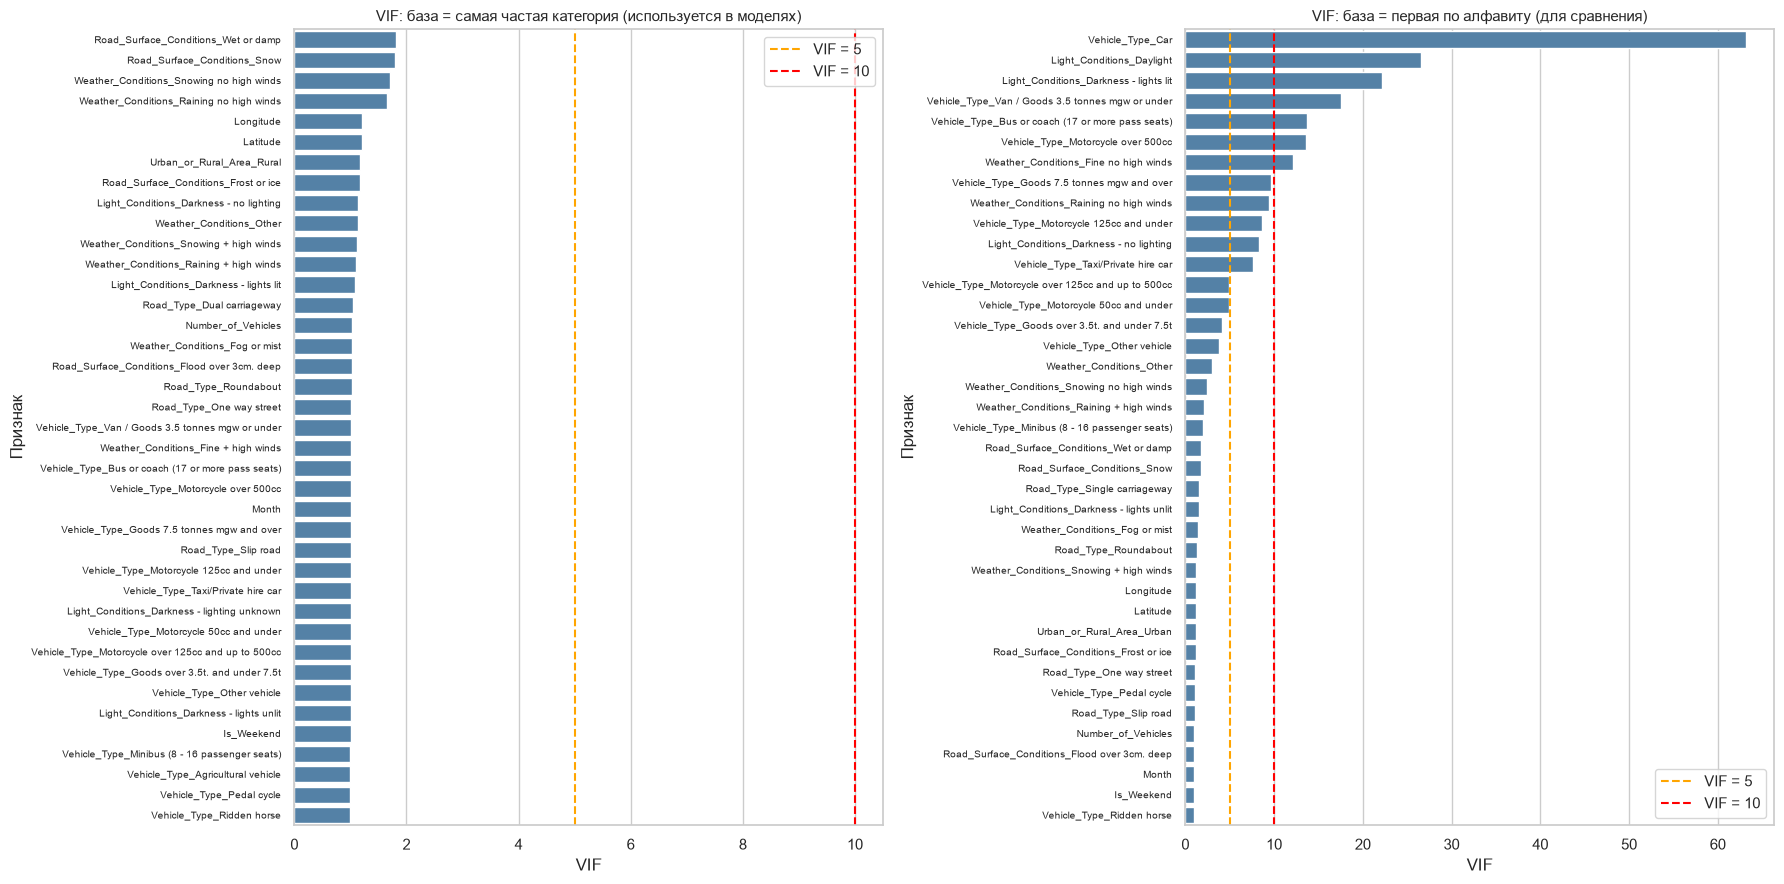

In [14]:
def compute_vif(features):
    """VIF каждого столбца: 1 / (1 - R²) регрессии этого столбца на все остальные."""
    X_c = add_constant(features)                         # константа нужна, иначе VIF считается неверно
    vif = [variance_inflation_factor(X_c.values, i) for i in range(1, X_c.shape[1])]
    return (pd.DataFrame({"Признак": X_c.columns[1:], "VIF": vif})
            .sort_values("VIF", ascending=False).reset_index(drop=True))

# На вход подаются ВСЕ признаки после one-hot (без целевой переменной)
vif_table = compute_vif(X_enc)
print(f"VIF (база = самая частая категория) рассчитан для {len(vif_table)} признаков. Топ-15:")
display(vif_table.head(15).round(3))
print(f"Максимальный VIF: {vif_table['VIF'].max():.2f};  признаков с VIF > 5: {(vif_table['VIF'] > 5).sum()};  "
      f"с VIF > 10: {(vif_table['VIF'] > 10).sum()}")

# Сравнение: при редкой базовой категории (первая по алфавиту) VIF dummy-столбцов раздувается искусственно
vif_alpha = compute_vif(X_enc_alpha)
print(f"\nVIF при алфавитной базе (drop_first=True): максимум {vif_alpha['VIF'].max():.2f}, "
      f"признаков с VIF > 10: {(vif_alpha['VIF'] > 10).sum()}. Топ-6:")
display(vif_alpha.head(6).round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 9), sharex=False)
for ax, tbl, ttl in zip(axes, [vif_table, vif_alpha], ["база = самая частая категория (используется в моделях)", "база = первая по алфавиту (для сравнения)"]):
    sns.barplot(data=tbl, y="Признак", x="VIF", color="steelblue", ax=ax)
    ax.axvline(5, color="orange", linestyle="--", label="VIF = 5")
    ax.axvline(10, color="red", linestyle="--", label="VIF = 10")
    ax.set_title(f"VIF: {ttl}", fontsize=11)
    ax.tick_params(axis="y", labelsize=7)
    ax.legend()
plt.tight_layout()
plt.show()

**Как считается VIF.** Для каждого признака строится регрессия этого признака на все остальные; `VIF = 1 / (1 - R²)`. VIF = 1 - признак не коррелирует с остальными, VIF > 5 - заметная, VIF > 10 - серьёзная мультиколлинеарность (квадратный корень из VIF показывает, во сколько раз вырастает стандартная ошибка коэффициента). В функцию `compute_vif` передаётся матрица всех 39 признаков после one-hot (без целевой переменной) с добавленной константой (`add_constant`) - без константы VIF считался бы неверно.

**Результат (база = самая частая категория):**
- максимальный VIF = **1.815** (`Road_Surface_Conditions_Wet or damp`), далее `Snow` 1.797, `Snowing no high winds` 1.710, `Raining no high winds` 1.648; у остальных признаков VIF от 1.0 до 1.2;
- признаков с VIF > 5: **0**, с VIF > 10: **0**. Даже самые связанные пары («мокро» / «дождь», «снег» / «снегопад») дают VIF меньше 2.

**Вывод: серьёзной мультиколлинеарности в данных нет.** Каждый признак объясняется остальными не более чем на 45 % (1 - 1/1.815).

**Важное методическое наблюдение (график справа).** Если выбрать базовой категорией не самую частую, а **первую по алфавиту** (поведение `drop_first=True`), VIF резко вырастает: `Vehicle_Type_Car` - **63.2**, `Light_Conditions_Daylight` - 26.6, `Light_Conditions_Darkness - lights lit` - 22.2, и 7 признаков получают VIF > 10. Это **артефакт кодирования**, а не реальная зависимость: когда база - очень редкая категория (Agricultural vehicle - 0.3 %, Darkness - lighting unknown - 0.7 %), частая категория группы «почти полностью» выражается через остальные dummy той же группы. Поэтому в работе база выбирается как самая частая категория, а «высокий VIF» у dummy-признаков с алфавитной базой не следует трактовать как мультиколлинеарность данных.

**Какие признаки удалять или преобразовывать:** по результатам корреляций и VIF удалять признаки **не требуется**. Можно было бы рассмотреть объединение редких категорий (например, «Ridden horse», 4 записи, «Pedal cycle», 192) - но это не связано с мультиколлинеарностью, а лишь с надёжностью коэффициентов; для регуляризации (Ridge/Lasso) и PCA данных достаточно. PCA в работе всё равно выполняется (по заданию) - и мы посмотрим, что даёт её применение при отсутствии мультиколлинеарности.

## Подготовка данных

### Формирование X и y, разделение выборки, масштабирование

In [15]:
X = df.drop(columns=target)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Предобработка: числовые - StandardScaler, категориальные - OneHotEncoder (база - самая частая категория)
# drop = список базовых категорий (самых частых) в порядке categorical_features
def make_ohe(**kwargs):
    """OneHotEncoder с плотным выводом: параметр называется sparse_output (sklearn >= 1.2) или sparse (старее)."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False, **kwargs)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False, **kwargs)

one_hot_encoder = make_ohe(drop=[base[c] for c in categorical_features])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", one_hot_encoder, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

print(f"Всего объектов:       {len(X):,}")
print(f"Обучающая выборка:    {X_train.shape[0]:,} объектов × {X_train.shape[1]} исходных признаков")
print(f"Тестовая выборка:     {X_test.shape[0]:,} объектов × {X_test.shape[1]} исходных признаков")
print(f"Доля тестовой выборки: {len(X_test) / len(X):.1%}")
print(f"Целевая переменная минимум: {y.min()} (MAPE без деления на ноль: {(y > 0).all()})")
print(f"Среднее целевой: train = {y_train.mean():.4f}, test = {y_test.mean():.4f};  "
      f"доли ДТП с 1 пострадавшим: train = {(y_train == 1).mean():.3f}, test = {(y_test == 1).mean():.3f}")

print(f"Std целевой: train = {y_train.std():.4f}, test = {y_test.std():.4f};  максимум: train = {y_train.max()}, test = {y_test.max()}")

feature_names = preprocessor.fit(X_train).get_feature_names_out()      # fit ТОЛЬКО на train
print(f"\nЧисло признаков после кодирования: {len(feature_names)}")
print(list(feature_names))

Всего объектов:       652,497
Обучающая выборка:    521,997 объектов × 11 исходных признаков
Тестовая выборка:     130,500 объектов × 11 исходных признаков
Доля тестовой выборки: 20.0%
Целевая переменная минимум: 1 (MAPE без деления на ноль: True)
Среднее целевой: train = 1.3605, test = 1.3599;  доли ДТП с 1 пострадавшим: train = 0.761, test = 0.761
Std целевой: train = 0.8271, test = 0.8319;  максимум: train = 68, test = 47



Число признаков после кодирования: 39
['Number_of_Vehicles', 'Latitude', 'Longitude', 'Month', 'Is_Weekend', 'Light_Conditions_Darkness - lighting unknown', 'Light_Conditions_Darkness - lights lit', 'Light_Conditions_Darkness - lights unlit', 'Light_Conditions_Darkness - no lighting', 'Road_Surface_Conditions_Flood over 3cm. deep', 'Road_Surface_Conditions_Frost or ice', 'Road_Surface_Conditions_Snow', 'Road_Surface_Conditions_Wet or damp', 'Road_Type_Dual carriageway', 'Road_Type_One way street', 'Road_Type_Roundabout', 'Road_Type_Slip road', 'Urban_or_Rural_Area_Rural', 'Weather_Conditions_Fine + high winds', 'Weather_Conditions_Fog or mist', 'Weather_Conditions_Other', 'Weather_Conditions_Raining + high winds', 'Weather_Conditions_Raining no high winds', 'Weather_Conditions_Snowing + high winds', 'Weather_Conditions_Snowing no high winds', 'Vehicle_Type_Agricultural vehicle', 'Vehicle_Type_Bus or coach (17 or more pass seats)', 'Vehicle_Type_Goods 7.5 tonnes mgw and over', 'Vehicle

**Формирование X и y.** `y = df["Number_of_Casualties"]`, `X` - остальные 11 столбцов (5 числовых и 6 категориальных; `Index`, дата, район и тяжесть ДТП исключены, см. выше).

**Разделение:** `train_test_split(test_size=0.20, random_state=42)` дало **521 997** объектов в обучающей и **130 500** в тестовой выборке (ровно 20 %). `random_state=42` фиксирует начальное состояние генератора случайных чисел: при том же значении получается то же самое разбиение (воспроизводимость отчёта); при другом значении разбиение изменится, а метрики слегка сдвинутся в пределах разброса между фолдами (около 0.02 по RMSE).

**Подходит ли случайное разбиение?** Да: (1) временного порядка нет - даты искусственно сдвинуты, год не используется; (2) повторных наблюдений одного объекта практически нет (у строк с корректным `Index` почти все значения уникальны; испорченные `Index` проверить нельзя, но координаты, дата и условия делают строки независимыми ДТП); (3) целевая переменная распределена в выборках одинаково: среднее 1.3605 (train) и 1.3599 (test), доля ДТП с одним пострадавшим 76.1 % в обеих.

Стандартное отклонение цели в тесте (0.8319) чуть больше, чем в обучении (0.8271); максимум в train - 68, в test - 47: в обучающую выборку случайно попали самые тяжёлые аварии. Это объясняет небольшие расхождения train/CV/test в метриках ниже.

**Предобработка (`ColumnTransformer`).** Числовые признаки (`Number_of_Vehicles`, `Latitude`, `Longitude`, `Month`, `Is_Weekend`) стандартизуются `StandardScaler` (z = (x - μ) / σ); категориальные кодируются `OneHotEncoder` с явным списком базовых категорий `drop=[...]`. После кодирования получается **39 признаков**. Преобразования **обучаются только на обучающей выборке**: `preprocessor.fit(X_train)`, к тесту применяется лишь `transform`.

In [16]:
# Демонстрация fit / transform / fit_transform и отсутствия утечки данных из тестовой выборки
demo_cols = ["Number_of_Vehicles", "Latitude"]
scaler = StandardScaler()

scaler.fit(X_train[demo_cols])                         # fit: запоминает среднее и std ТОЛЬКО обучающей выборки
print("fit: mean_ =", scaler.mean_.round(4), " scale_ (std) =", scaler.scale_.round(4))

train_scaled = scaler.transform(X_train[demo_cols])    # transform: применяет уже запомненные параметры
test_scaled = scaler.transform(X_test[demo_cols])      # то же правило к тесту (параметры НЕ пересчитываются)

same = StandardScaler().fit_transform(X_train[demo_cols])   # fit_transform = fit + transform на одних данных
print("fit_transform == fit + transform на train:", np.allclose(train_scaled, same))

print("\nСреднее после масштабирования, train:", train_scaled.mean(axis=0).round(6), "(строго 0 - так и должно быть)")
print("Среднее после масштабирования, test :", test_scaled.mean(axis=0).round(4),
      "(≠ 0: тест масштабируется по параметрам train - утечки нет)")

fit: mean_ = [ 1.833  52.5546]  scale_ (std) = [0.715  1.4098]
fit_transform == fit + transform на train: True

Среднее после масштабирования, train: [0. 0.] (строго 0 - так и должно быть)
Среднее после масштабирования, test : [-0.0009  0.    ] (≠ 0: тест масштабируется по параметрам train - утечки нет)


Демонстрация различия `fit`, `transform` и `fit_transform` и отсутствия утечки данных:
- **`fit`** вычисляет параметры преобразования по данным (для `StandardScaler` - среднее `mean_` и стандартное отклонение `scale_`) и ничего не преобразует. Здесь параметры считаются по **train**: среднее числа машин 1.833, широты 52.5546.
- **`transform`** применяет уже вычисленные параметры к любым данным (train и test с **одними и теми же** μ и σ).
- **`fit_transform`** = `fit` + `transform` на одних и тех же данных (используется для обучающей выборки). Проверка `np.allclose` подтверждает равенство результатов.

Среднее масштабированного train строго равно 0, а масштабированного test - **не** равно нулю (-0.0009 и 0.0000): тест масштабируется по параметрам обучающей выборки. Если бы `fit` вызывался на тесте (или на всей выборке), среднее теста было бы ровно 0 - это и была бы утечка информации из теста в обучение. В основных моделях то же гарантирует `Pipeline`: при кросс-валидации все шаги обучаются заново на обучающей части каждого фолда.

## Ход работы

### Построение регрессионных моделей

Оценим, насколько обстоятельства ДТП позволяют предсказать число пострадавших. Сравниваются три алгоритма:

1. **Обычная линейная регрессия** подбирает коэффициенты методом наименьших квадратов (МНК, минимизация суммы квадратов остатков). Базовая модель.
2. **Ridge (гребневая регрессия)** добавляет к функции потерь L2-штраф α·Σwᵢ²; уменьшает коэффициенты, но не обнуляет их; помогает при коррелирующих признаках.
3. **Lasso** добавляет L1-штраф α·Σ|wᵢ|; часть коэффициентов обнуляется (встроенный отбор признаков).

**Pipeline** каждой модели: `preprocessor` (стандартизация числовых + one-hot) → `feature_scaler` (`StandardScaler` на все 39 столбцов, в том числе dummy: чтобы штрафы Ridge/Lasso действовали на признаки одинаково) → `regressor`.

**Подбор alpha.** Для Ridge и Lasso `GridSearchCV` проверяет **10 значений** на логарифмической сетке: 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1e3, 1e4, 1e5 (сетка шире, чем в типовых примерах: при масштабе целевой переменной около 1 типичные «большие» alpha сразу обнулили бы все коэффициенты Lasso). Критерий выбора - минимальный средний RMSE на **пяти** валидационных фолдах (`KFold(n_splits=5, shuffle=True, random_state=42)`). Для обычной регрессии параметров подбирать не нужно: оценивается кросс-валидацией `cross_validate`. Тестовая выборка в подборе alpha не участвует.

**Параметры моделей.** Явно заданы: `Lasso(max_iter=10000, random_state=42)`; остальное - по умолчанию (`fit_intercept=True`, у Lasso `tol=1e-4`, `selection="cyclic"`; у Ridge `solver="auto"`); `alpha` для Ridge/Lasso подбирается.

**Метрики.** RMSE = √MSE (в единицах цели - числе пострадавших), R², MAE и MAPE (в процентах, `×100`). MAPE допустим, так как цель ≥ 1.

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "MAPE": make_scorer(mean_absolute_percentage_error, greater_is_better=False),
}

# Сетка параметра регуляризации alpha (логарифмическая, 10 значений) - общая для Ridge и Lasso
ALPHA_VALUES = np.array([1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1e3, 1e4, 1e5])

regressors = {
    "Линейная регрессия": LinearRegression(),
    "Ridge": Ridge(),                                  # остальные параметры - по умолчанию
    "Lasso": Lasso(max_iter=10000, random_state=RANDOM_STATE),
}

def make_regression_pipeline(regressor):
    """Pipeline: кодирование/масштабирование -> стандартизация всех столбцов -> регрессор."""
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("feature_scaler", StandardScaler()),
        ("regressor", clone(regressor)),
    ])

def evaluate(y_true, y_pred):
    """Метрики качества. RMSE считается через MSE: RMSE = sqrt(MSE). MAPE переводится в проценты."""
    mse = mean_squared_error(y_true, y_pred)
    return {
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

def fit_and_score(model_name, regressor, pipeline_factory, X_tr, y_tr, X_te, y_te, searches):
    """Обучение одной модели: Ridge/Lasso - через GridSearchCV по alpha, обычная МНК - через cross_validate."""
    pipeline = pipeline_factory(regressor)
    if model_name in ("Ridge", "Lasso"):
        search = GridSearchCV(pipeline, param_grid={"regressor__alpha": ALPHA_VALUES},
                              scoring=scoring, refit="RMSE", cv=cv, n_jobs=N_JOBS)
        search.fit(X_tr, y_tr)
        searches[model_name] = search
        fitted = search.best_estimator_
        i = search.best_index_
        res = search.cv_results_
        cv_part = {"CV RMSE, среднее": -res["mean_test_RMSE"][i], "CV RMSE, std": res["std_test_RMSE"][i],
                   "CV R², среднее": res["mean_test_R2"][i], "CV MAE, среднее": -res["mean_test_MAE"][i],
                   "CV MAPE, %": -res["mean_test_MAPE"][i] * 100}
        alpha = search.best_params_["regressor__alpha"]
    else:
        scores = cross_validate(pipeline, X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=N_JOBS)
        fitted = clone(pipeline).fit(X_tr, y_tr)
        cv_part = {"CV RMSE, среднее": (-scores["test_RMSE"]).mean(), "CV RMSE, std": (-scores["test_RMSE"]).std(ddof=1),
                   "CV R², среднее": scores["test_R2"].mean(), "CV MAE, среднее": (-scores["test_MAE"]).mean(),
                   "CV MAPE, %": (-scores["test_MAPE"]).mean() * 100}
        alpha = "не применяется"
    y_tr_pred = fitted.predict(X_tr)                    # прогноз на обучающей выборке
    y_te_pred = fitted.predict(X_te)                    # прогноз на тестовой выборке (итоговые метрики - по нему)
    tr, te = evaluate(y_tr, y_tr_pred), evaluate(y_te, y_te_pred)
    row = {"Модель": model_name, "Выбранная alpha": alpha, **cv_part,
           **{f"Train {k}": v for k, v in tr.items()}, **{f"Тест {k}": v for k, v in te.items()}}
    return fitted, row

# Базовый ориентир: «модель», всегда предсказывающая среднее обучающей выборки
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
base_metrics = evaluate(y_test, dummy.predict(X_test))
print("Ориентир (прогноз = среднее train) на тесте:", {k: round(v, 4) for k, v in base_metrics.items()})
print(f"MAPE при прогнозе «всегда 1 пострадавший»: {mean_absolute_percentage_error(y_test, np.ones(len(y_test))) * 100:.2f} %")

Ориентир (прогноз = среднее train) на тесте: {'RMSE': np.float64(0.8319), 'MAE': 0.5482, 'R2': -0.0, 'MAPE, %': 37.1704}
MAPE при прогнозе «всегда 1 пострадавший»: 13.48 %


Два ориентира для оценки качества:
- прогноз «всегда равен среднему обучающей выборки» (`DummyRegressor`): **RMSE = 0.8319, MAE = 0.5482, R² = 0.0, MAPE = 37.17 %**. Любая осмысленная модель должна быть лучше этого;
- прогноз «всегда 1 пострадавший» (мода): **MAPE = 13.48 %**. Это интересный «парадокс» MAPE: так как 76 % фактических значений равны 1, прогноз 1 для них даёт ошибку 0, и средняя процентная ошибка оказывается меньше, чем у любой «умной» модели (≈ 33.8 %, см. ниже). MAPE делит на фактическое значение, поэтому **штрафует занижение слабее, чем завышение**; прогнозы чуть выше 1 для единичных ДТП («нормальная» оценка среднего ≈ 1.36) дают ошибку 36 %. Поэтому при выборе лучшей модели MAPE нужно трактовать осторожно и опираться на RMSE и R².

In [18]:
baseline_models, baseline_searches, baseline_rows = {}, {}, []
for model_name, regressor in regressors.items():
    fitted, row = fit_and_score(model_name, regressor, make_regression_pipeline,
                                X_train, y_train, X_test, y_test, baseline_searches)
    baseline_models[model_name] = fitted
    baseline_rows.append(row)

baseline_results = pd.DataFrame(baseline_rows).set_index("Модель")
print("Качество моделей на исходных признаках (alpha для Ridge/Lasso выбрана по CV):")
display(baseline_results[["Выбранная alpha", "CV RMSE, среднее", "CV RMSE, std", "CV R², среднее", "CV MAE, среднее", "CV MAPE, %"]].round(4))
display(baseline_results[[c for c in baseline_results.columns if c.startswith(("Train", "Тест"))]].round(4))

/private/tmp/claude-501/-Users-sedooj-Downloads-lab1-c/b75236d7-7c64-471c-a5dc-702f28d05b98/scratchpad/venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/private/tmp/claude-501/-Users-sedooj-Downloads-lab1-c/b75236d7-7c64-471c-a5dc-702f28d05b98/scratchpad/venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Качество моделей на исходных признаках (alpha для Ridge/Lasso выбрана по CV):


,Выбранная alpha,"CV RMSE, среднее","CV RMSE, std","CV R², среднее","CV MAE, среднее","CV MAPE, %"
Модель,,,,,,
Линейная регрессия,не применяется,0.7972,0.0235,0.0705,0.5007,33.8235
Ridge,1000.0,0.7972,0.0210,0.0705,0.5008,33.8284
Lasso,0.001,0.7972,0.0210,0.0705,0.5010,33.8365


,Train RMSE,Train MAE,Train R2,"Train MAPE, %",Тест RMSE,Тест MAE,Тест R2,"Тест MAPE, %"
Модель,,,,,,,,
Линейная регрессия,0.7974,0.5007,0.0706,33.8198,0.8007,0.5001,0.0737,33.8126
Ridge,0.7974,0.5007,0.0706,33.8237,0.8007,0.5002,0.0737,33.8165
Lasso,0.7974,0.5010,0.0705,33.8344,0.8007,0.5003,0.0737,33.8221


**Результаты на исходных признаках** (alpha для Ridge/Lasso выбрана по CV RMSE):

| Модель | alpha | CV RMSE | CV R² | CV MAPE, % | Тест RMSE | Тест R² | Тест MAPE, % |
|---|---|---|---|---|---|---|---|
| Линейная регрессия | - | 0.7972 | 0.0705 | 33.82 | 0.8007 | 0.0737 | 33.81 |
| Ridge | 1000 | 0.7972 | 0.0705 | 33.83 | 0.8007 | 0.0737 | 33.82 |
| Lasso | 0.001 | 0.7972 | 0.0705 | 33.84 | 0.8007 | 0.0737 | 33.82 |

1. **Все три модели практически неразличимы**: тестовый RMSE 0.8007 у всех (различия появляются только в пятом знаке), R² одинаков (0.0737). Разброс RMSE между фолдами (std 0.021-0.024) намного больше разницы между моделями.
2. **R² ≈ 0.07**: модель объясняет лишь около 7 % дисперсии числа пострадавших; остальные ≈ 93 % приходятся на факторы, которых нет в данных (скорость, тяжесть столкновения, число пассажиров, тип удара и пр.). Тем не менее модель лучше ориентира «прогноз = среднее»: RMSE снизился с 0.8319 до 0.8007 (на 3.75 %), R² вырос с 0 до 0.074, MAPE упал с 37.17 до 33.81 %. Модель в среднем ошибается на **0.80 пострадавших** (RMSE) или **0.50** (MAE); при среднем 1.36 это ≈ 59 % от среднего.
3. **Переобучения нет**: RMSE на обучении (0.7974), в CV (0.7972) и на тесте (0.8007) практически совпадают (разница 0.003 при std между фолдами 0.02). Тест чуть хуже обучения не из-за переобучения, а из-за состава выборки: в train попал максимум 68 пострадавших, а в test - 47, и std цели в тесте больше (0.832 против 0.827). У модели всего 39 параметров при 522 тыс. объектов, поэтому переобучиться она не может. Скорее наблюдается **недообучение**: ошибка велика уже на обучающей выборке - линейная модель по этим признакам принципиально не может объяснить большую часть дисперсии.
4. **MAPE ≈ 33.8 %** (против 13.5 % у константы 1): объяснение дано выше, это особенность метрики при скошенной цели с модой 1.
5. **Регуляризация не помогла**: оптимальная alpha у Lasso равна 0.001, у Ridge - 1000 (но кривая Ridge плоская, см. ниже). Данных очень много (522 тыс.) по сравнению с числом признаков (39), поэтому МНК и без штрафа устойчив.
6. **Выбор лучшей модели** (правило в коде ниже: минимальный CV RMSE, при равенстве в пределах шума - более простая модель): по CV RMSE формально лучший Lasso/Ridge/МНК (0.7972 у всех), но они неотличимы, поэтому по принципу простоты можно взять обычную линейную регрессию.

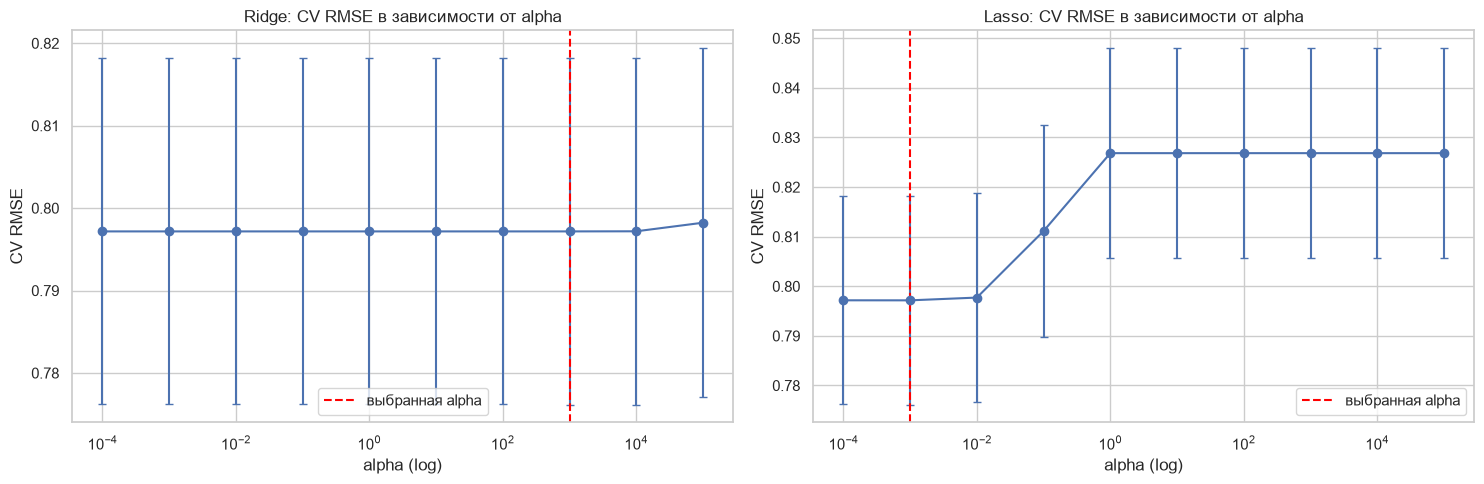

Модель,Lasso,Ridge
alpha,,
0.0001,0.7972,0.7972
0.0010,0.7972,0.7972
0.0100,0.7977,0.7972
0.1000,0.8111,0.7972
1.0000,0.8268,0.7972
10.0000,0.8268,0.7972
100.0000,0.8268,0.7972
1000.0000,0.8268,0.7972
10000.0000,0.8268,0.7972


In [19]:
# Как выбирается alpha: средний CV RMSE для каждого значения сетки
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
alpha_rows = []
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    res = baseline_searches[name].cv_results_
    alphas = res["param_regressor__alpha"].astype(float)
    rmse = -res["mean_test_RMSE"]
    ax.errorbar(alphas, rmse, yerr=res["std_test_RMSE"], marker="o", capsize=3)
    ax.axvline(baseline_searches[name].best_params_["regressor__alpha"], color="red", linestyle="--", label="выбранная alpha")
    ax.set_xscale("log")
    ax.set_title(f"{name}: CV RMSE в зависимости от alpha")
    ax.set_xlabel("alpha (log)")
    ax.set_ylabel("CV RMSE")
    ax.legend()
    for a, r in zip(alphas, rmse):
        alpha_rows.append({"Модель": name, "alpha": a, "CV RMSE": r})
plt.tight_layout()
plt.show()
display(pd.DataFrame(alpha_rows).pivot(index="alpha", columns="Модель", values="CV RMSE").round(5))

**Как подбирается alpha** (график: средний CV RMSE и разброс по фолдам для каждого значения сетки; красная линия - выбранное значение):

- **Lasso**: при alpha 1e-4…1e-3 CV RMSE = 0.7972 (минимум), при alpha = 0.01 он растёт до 0.7977, при 0.1 - до 0.8111, а при alpha ≥ 1 выходит на плато **0.8268**: все коэффициенты обнулены, модель превращается в константу (прогноз = среднее, RMSE примерно как у `DummyRegressor`). То есть чем сильнее L1-штраф, тем хуже; оптимум - очень слабая регуляризация (alpha = 0.001).
- **Ridge**: CV RMSE = 0.7972 практически не меняется от alpha = 1e-4 до 1e4 и только при alpha = 1e5 слегка ухудшается до 0.7982. Поэтому значение 1000 «выбрано» формально (минимум в пределах шума, остальные значения отличаются на сотые доли процента). Кривая плоская: штраф L2 при 522 тыс. объектах ничего не «сжимает», а регуляризация не нужна.

In [20]:
baseline_feature_names = baseline_models["Линейная регрессия"].named_steps["preprocessor"].get_feature_names_out()
coef_frame = pd.DataFrame({name: model.named_steps["regressor"].coef_ for name, model in baseline_models.items()},
                          index=baseline_feature_names)
print("Коэффициенты моделей (признаки стандартизованы: изменение прогноза при росте признака на 1 std):")
display(coef_frame.round(4))

summary_rows = []
for model_name, model in baseline_models.items():
    coef = pd.Series(model.named_steps["regressor"].coef_, index=baseline_feature_names)
    top = coef.abs().sort_values(ascending=False).head(5).index
    summary_rows.append({
        "Модель": model_name,
        "Свободный член": model.named_steps["regressor"].intercept_,
        "Ненулевых коэффициентов": int(np.count_nonzero(np.abs(coef.values) > 1e-8)),
        "Нулевых коэффициентов": int(np.sum(np.abs(coef.values) <= 1e-8)),
        "Топ-5 по |коэффициенту|": ", ".join(f"{f} ({coef[f]:.3f})" for f in top),
    })
display(pd.DataFrame(summary_rows).set_index("Модель"))

zero_lasso = coef_frame.index[np.abs(coef_frame["Lasso"]) <= 1e-8].tolist()
print("Признаки, обнулённые Lasso:", zero_lasso)

# Уравнение линейной регрессии (в стандартизованных признаках): топ-6 слагаемых
lin = coef_frame["Линейная регрессия"].sort_values(key=abs, ascending=False)
intercept = baseline_models["Линейная регрессия"].named_steps["regressor"].intercept_
terms = " ".join(f"{c:+.3f}·z({n})" for n, c in lin.head(6).items())
print(f"\nŷ = {intercept:.3f} {terms} + ... (ещё {len(lin) - 6} слагаемых), где z(·) - стандартизованный признак")

Коэффициенты моделей (признаки стандартизованы: изменение прогноза при росте признака на 1 std):


,Линейная регрессия,Ridge,Lasso
Number_of_Vehicles,0.1903,0.1899,0.1892
Latitude,0.0208,0.0208,0.0202
Longitude,-0.0202,-0.0201,-0.0195
Month,-0.0014,-0.0014,-0.0002
Is_Weekend,0.0167,0.0167,0.0158
Light_Conditions_Darkness - lighting unknown,0.0014,0.0014,0.0003
Light_Conditions_Darkness - lights lit,0.0298,0.0297,0.0284
Light_Conditions_Darkness - lights unlit,0.0016,0.0016,0.0005
Light_Conditions_Darkness - no lighting,0.0384,0.0383,0.0374
Road_Surface_Conditions_Flood over 3cm. deep,0.0032,0.0032,0.0021


,Свободный член,Ненулевых коэффициентов,Нулевых коэффициентов,Топ-5 по |коэффициенту|
Модель,,,,
Линейная регрессия,1.3605,39,0,"Number_of_Vehicles (0.190), Urban_or_Rural_Are..."
Ridge,1.3605,39,0,"Number_of_Vehicles (0.190), Urban_or_Rural_Are..."
Lasso,1.3605,27,12,"Number_of_Vehicles (0.189), Urban_or_Rural_Are..."


Признаки, обнулённые Lasso: ['Road_Surface_Conditions_Frost or ice', 'Road_Surface_Conditions_Snow', 'Road_Type_Slip road', 'Weather_Conditions_Fine + high winds', 'Weather_Conditions_Snowing + high winds', 'Vehicle_Type_Agricultural vehicle', 'Vehicle_Type_Goods over 3.5t. and under 7.5t', 'Vehicle_Type_Minibus (8 - 16 passenger seats)', 'Vehicle_Type_Motorcycle over 125cc and up to 500cc', 'Vehicle_Type_Pedal cycle', 'Vehicle_Type_Ridden horse', 'Vehicle_Type_Van / Goods 3.5 tonnes mgw or under']

ŷ = 1.360 +0.190·z(Number_of_Vehicles) +0.072·z(Urban_or_Rural_Area_Rural) +0.038·z(Light_Conditions_Darkness - no lighting) +0.030·z(Light_Conditions_Darkness - lights lit) -0.023·z(Road_Type_Roundabout) +0.021·z(Latitude) + ... (ещё 33 слагаемых), где z(·) - стандартизованный признак


Все признаки стандартизованы, поэтому коэффициент показывает, на сколько пострадавших в среднем меняется прогноз при росте признака на одно стандартное отклонение (для dummy - при переходе из базовой категории в данную) при неизменных остальных. Свободный член **1.3605** равен среднему числу пострадавших в обучающей выборке (при центрированных признаках так и должно быть) и одинаков у всех моделей.

**Уравнение множественной линейной регрессии** (стандартизованные признаки; приведены самые крупные слагаемые):
ŷ = 1.360 + 0.190·z(Number_of_Vehicles) + 0.072·z(Rural) + 0.038·z(Darkness - no lighting) + 0.030·z(Darkness - lights lit) - 0.023·z(Roundabout) + 0.021·z(Latitude) + … (ещё 33 слагаемых).
Тип регрессии - **множественная линейная** (много независимых переменных, зависимость линейная по параметрам).

**Интерпретация:**
1. **Число транспортных средств** - главный фактор: +0.190 пострадавших на 1 std (≈ 0.72 машины); в исходных единицах это ≈ +0.27 пострадавших на каждую дополнительную машину (0.190 / 0.717), что согласуется с таблицей средних (рост 1.17 → 1.38 → 1.72 → 2.00).
2. **Сельская местность**: +0.072 (в Rural пострадавших в среднем больше, чем в Urban при прочих равных).
3. **Освещённость**: без освещения в темноте +0.038, ночью с освещением +0.030 относительно дневного света - темнота увеличивает число пострадавших.
4. **Тип дороги**: кольцо (Roundabout) -0.023 и дорога с односторонним движением -0.008 снижают, двухполосная (Dual carriageway) +0.017 повышает.
5. **Мокрая дорога**: +0.018; **выходной**: +0.017; погодные условия, тип ТС и месяц - коэффициенты по модулю меньше 0.006 (практически нулевое влияние).
6. **Географические координаты**: `Latitude` +0.021 (чем севернее - тем больше пострадавших), `Longitude` -0.020 (чем западнее, тем больше).

**Различия между моделями.** Коэффициенты МНК, Ridge и Lasso почти совпадают (у `Number_of_Vehicles` 0.1903 / 0.1899 / 0.1892). Ridge сжимает слабо. **Lasso обнулил 12 из 39 коэффициентов** (27 ненулевых): это малозначимые dummy - `Frost or ice`, `Snow`, `Slip road`, `Fine + high winds`, `Snowing + high winds`, `Agricultural vehicle`, редкие типы ТС и др. (полный список выводится ячейкой выше). То есть Lasso выполнил отбор признаков, соответствующий слабым корреляциям с целью. Остальные модели оставили все 39 ненулевых коэффициентов.

Мультиколлинеарности нет (VIF < 2), поэтому, в отличие от случаев с VIF в десятки, знаки и величины коэффициентов здесь **стабильны и интерпретируемы**.

### График остатков моделей

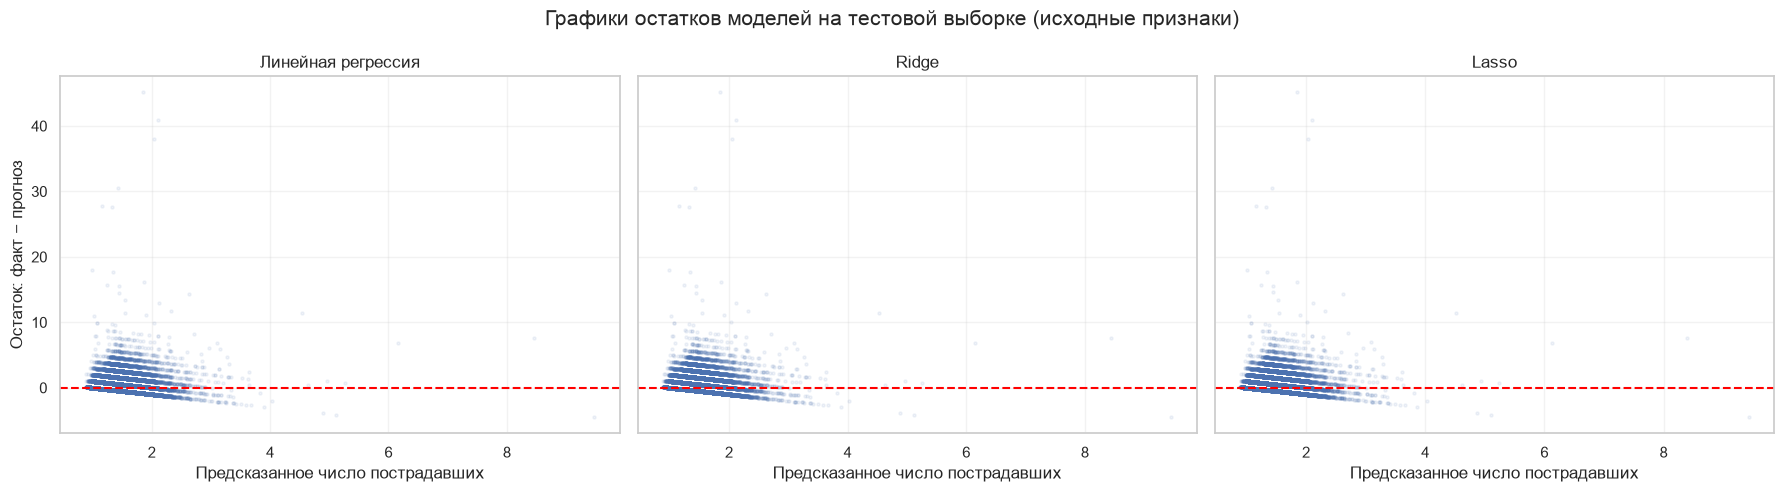

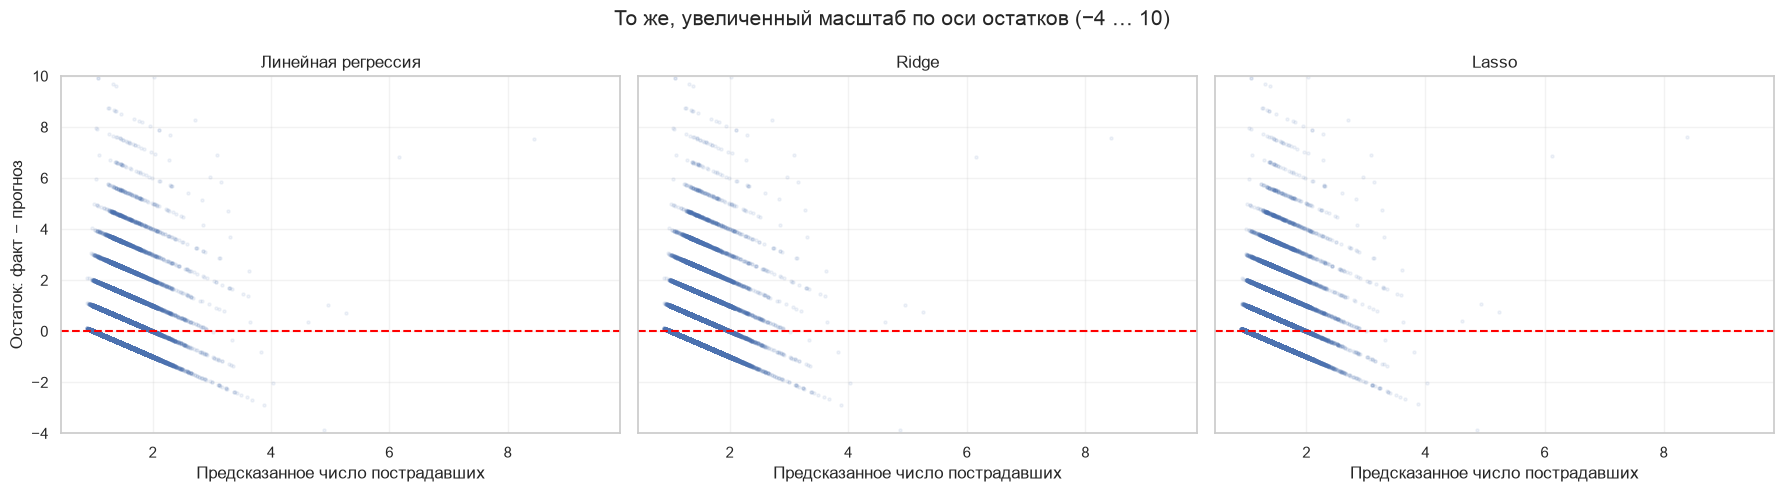

Остатки линейной регрессии по пяти квантильным интервалам прогноза:


,Объектов,Средний остаток,Std остатка
Прогноз (квантильный интервал),,,
"(0.886, 1.189]",26100,0.0337,0.4745
"(1.189, 1.31]",26100,-0.0376,0.6000
"(1.31, 1.384]",26100,-0.0150,0.7448
"(1.384, 1.499]",26100,0.0027,0.8593
"(1.499, 9.474]",26100,0.0125,1.1507


,LM-статистика,p-value (LM),F-статистика,p-value (F)
Модель,,,,
Линейная регрессия,404.7442,7.1698e-63,10.6811,5.5453e-63
Ridge,404.8097,6.9591e-63,10.6828,5.3818e-63
Lasso,405.0793,6.1544e-63,10.6900,4.7577e-63


Средний остаток: -0.0007; доля отрицательных прогнозов: 0.00%; минимальный прогноз: 0.887; максимальный прогноз: 9.474


In [21]:
def residual_plot(models, title, X_te, y_te, ylim=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    for ax, (model_name, fitted_model) in zip(axes, models.items()):
        y_pred = fitted_model.predict(X_te)
        residuals = y_te.to_numpy() - y_pred
        ax.scatter(y_pred, residuals, s=5, alpha=0.08)
        ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
        ax.set_title(model_name)
        ax.set_xlabel("Предсказанное число пострадавших")
        ax.grid(alpha=0.25)
        if ylim:
            ax.set_ylim(*ylim)
    axes[0].set_ylabel("Остаток: факт − прогноз")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

residual_plot(baseline_models, "Графики остатков моделей на тестовой выборке (исходные признаки)", X_test, y_test)
residual_plot(baseline_models, "То же, увеличенный масштаб по оси остатков (−4 … 10)", X_test, y_test, ylim=(-4, 10))

# Количественная проверка гомоскедастичности: разброс остатков по интервалам прогноза
lin_model = baseline_models["Линейная регрессия"]
pred = lin_model.predict(X_test)
res = y_test.to_numpy() - pred
bins = pd.qcut(pred, q=5, duplicates="drop")
res_by_bin = (pd.DataFrame({"Прогноз (квантильный интервал)": bins, "Остаток": res})
              .groupby("Прогноз (квантильный интервал)", observed=True)["Остаток"]
              .agg(["count", "mean", "std"]).rename(columns={"count": "Объектов", "mean": "Средний остаток", "std": "Std остатка"}))
print("Остатки линейной регрессии по пяти квантильным интервалам прогноза:")
display(res_by_bin.round(4))

# Тест Бройша-Пагана: H0 - дисперсия остатков постоянна (гомоскедастичность)
bp_rows = []
for model_name, fitted_model in baseline_models.items():
    Z = fitted_model[:-1].transform(X_test)                 # признаки теста после preprocessor + scaler
    r = y_test.to_numpy() - fitted_model.predict(X_test)
    lm, lm_p, f_stat, f_p = het_breuschpagan(r, add_constant(Z))
    bp_rows.append({"Модель": model_name, "LM-статистика": lm, "p-value (LM)": lm_p, "F-статистика": f_stat, "p-value (F)": f_p})
display(pd.DataFrame(bp_rows).set_index("Модель"))
print(f"Средний остаток: {res.mean():.4f}; доля отрицательных прогнозов: {(pred < 0).mean():.2%}; "
      f"минимальный прогноз: {pred.min():.3f}; максимальный прогноз: {pred.max():.3f}")

**Графики остатков** (остаток = факт − прогноз; красная линия - нулевой уровень). Из-за дискретности целевой переменной точки лежат **диагональными «лесенками»**: для каждого фактического значения 1, 2, 3… остатки образуют наклонную линию (остаток = целое − прогноз). Верхний ряд - весь диапазон (единичные точки до +45), нижний - увеличенный масштаб (−4…10).

1. **Структура остатков не случайна**: «лесенка» следует из дискретности цели - модель выдаёт непрерывный прогноз (от 0.89 до 9.5; диапазон основной массы 1.0-3.0), а факт принимает целые значения. Крупная масса остатков находится в интервале от −2 до +5; центр облака около нуля (средний остаток -0.0007).
2. **Гетероскедастичность** (дисперсия ошибок растёт с прогнозом). Таблица по пяти квантильным интервалам прогноза это подтверждает: std остатка **0.47** при прогнозе 0.89-1.19, 0.60, 0.74, 0.86 и **1.15** при прогнозе > 1.50, то есть разброс ошибок вырос в 2.4 раза. При большом прогнозе (много машин, село) реальное число пострадавших сильно варьируется («веер» расширяется вправо). Средний остаток по интервалам близок к нулю (от -0.038 до +0.034), систематического смещения нет.
3. **Формальная проверка - тест Бройша-Пагана** (H₀ - дисперсия остатков постоянна): LM = **404.7**, p-value = **7.2·10⁻⁶³** (аналогично у Ridge и Lasso); H₀ **отвергается** при любом разумном уровне значимости. Заметим, что на 130 тыс. наблюдений тест выявляет и малые отклонения, но здесь отклонение ещё и визуально очевидно (рост std в 2.4 раза).
4. **Выбросы**: единичные точки с остатком +20…+45 - редкие массовые аварии (30-68 пострадавших), которые модель с прогнозом ≈ 1-2 не может предсказать; они и тянут RMSE вверх. Отрицательных прогнозов нет (0.00 %): минимум 0.887, поэтому проблем с MAPE нет.
5. **Максимальный прогноз 9.5** возникает для ДТП с очень большим числом машин (экстраполяция линейной зависимости: 0.19·z на каждые 0.72 машины).

**Вывод:** допущение МНК о постоянной дисперсии (гомоскедастичности) **нарушено** (гетероскедастичность), плюс дискретная скошенная цель. На точечный прогноз это влияет умеренно, но стандартные ошибки коэффициентов и доверительные интервалы при таких остатках ненадёжны. Пути улучшения: преобразование цели (логарифм), взвешенный МНК или модели для счётных данных (см. дополнительный эксперимент в конце).

### Устранение мультиколлинеарности и снижение размерности с помощью PCA

**Метод главных компонент (PCA)** строит новые признаки - главные компоненты - как линейные комбинации исходных. Первая компонента объясняет максимум дисперсии данных, каждая следующая - максимум оставшейся при условии ортогональности предыдущим; поэтому компоненты **некоррелированы** (мультиколлинеарность устраняется), а отбрасывая последние, можно уменьшить размерность. PCA чувствителен к масштабу признаков, поэтому **перед PCA данные стандартизуются** (все 39 столбцов приводятся к среднему 0 и дисперсии 1).

Принципиально для этой работы: по результатам VIF мультиколлинеарности в данных нет (максимум 1.8), поэтому у PCA здесь нет «болезни», которую нужно лечить; но этап выполняется по заданию, и интересно, как он повлияет на качество.

In [22]:
# Шаги: one-hot + стандартизация -> дополнительная стандартизация -> полный PCA.
# Все преобразования обучаются ТОЛЬКО на обучающей выборке, тест лишь преобразуется.
pca_preprocessor = clone(preprocessor)
X_train_encoded = pca_preprocessor.fit_transform(X_train)
X_test_encoded = pca_preprocessor.transform(X_test)

pca_feature_scaler = StandardScaler()
X_train_scaled_for_pca = pca_feature_scaler.fit_transform(X_train_encoded)
X_test_scaled_for_pca = pca_feature_scaler.transform(X_test_encoded)

pca_full = PCA(random_state=RANDOM_STATE)
X_train_pca_full = pca_full.fit_transform(X_train_scaled_for_pca)
X_test_pca_full = pca_full.transform(X_test_scaled_for_pca)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)          # накопленная доля = частичные суммы ряда
n_components_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)

pca_variance_table = pd.DataFrame({
    "Главная компонента": np.arange(1, len(explained_variance) + 1),
    "Собственное значение": pca_full.explained_variance_,
    "Объяснённая дисперсия, %": explained_variance * 100,
    "Накопленная дисперсия, %": cumulative_variance * 100,
})
print(f"Число признаков до PCA: {X_train_scaled_for_pca.shape[1]}")
print(f"Размер train после полного PCA: {X_train_pca_full.shape};  test: {X_test_pca_full.shape}")
print(f"Компонент для объяснения ≥ 95 % дисперсии: {n_components_95}")
print(f"Размер train при {n_components_95} компонентах: {X_train_pca_full[:, :n_components_95].shape};  "
      f"test: {X_test_pca_full[:, :n_components_95].shape}")
display(pca_variance_table.round(3).set_index("Главная компонента"))

Число признаков до PCA: 39
Размер train после полного PCA: (521997, 39);  test: (130500, 39)
Компонент для объяснения ≥ 95 % дисперсии: 35
Размер train при 35 компонентах: (521997, 35);  test: (130500, 35)


,Собственное значение,"Объяснённая дисперсия, %","Накопленная дисперсия, %"
Главная компонента,,,
1,1.754,4.497,4.497
2,1.696,4.349,8.846
3,1.481,3.798,12.644
4,1.345,3.449,16.093
5,1.276,3.272,19.366
6,1.125,2.886,22.251
7,1.099,2.819,25.070
8,1.066,2.734,27.804
9,1.051,2.694,30.498


**Стандартизация перед PCA**: `pca_feature_scaler = StandardScaler()`, `fit_transform` на обучающей выборке (после one-hot), `transform` - на тесте. Так же, как и ранее, **параметры подбираются только по train**.

**PCA**: `PCA()` без ограничения числа компонент обучается на стандартизованной обучающей выборке (521 997 × 39), на входе - все 39 столбцов; даёт 39 компонент. Тестовая выборка преобразуется методом `transform` (с матрицей поворота, найденной по train): `X_test_pca_full = pca_full.transform(X_test_scaled_for_pca)`.

**Объяснённая дисперсия** (`explained_variance_ratio_`, доля собственного значения в сумме всех собственных значений; накопленная доля - `np.cumsum`): PC1 - 4.50 %, PC2 - 4.35 %, PC3 - 3.80 %, PC4 - 3.45 %, PC5 - 3.27 %, PC6 - 2.89 %, далее почти постоянное значение ≈ 2.6 % (PC10-PC27), затем снижение: PC32 - 2.14 %, PC35 - 1.88 %, PC38 - 0.96 %, PC39 - 0.73 %.

Такой «плоский» спектр объясняется составом данных: после one-hot кодирования и стандартизации почти все столбцы **практически не связаны друг с другом** (VIF ≈ 1), и каждый из них вносит собственную дисперсию ≈ 1/39 = 2.56 % - именно на этом уровне лежит полка PC10-PC27 (λ ≈ 1.0). Заметно выше полки только PC1-PC5 (λ от 1.75 до 1.28): они собирают умеренно связанные блоки (погода / покрытие, освещение / село - см. нагрузки ниже).

**Выбор числа компонент - долей объяснённой дисперсии**: `PCA(n_components=0.95)` - минимальное число компонент, объясняющих не менее 95 % дисперсии. Накопленная дисперсия: 34 компоненты - 93.25 %, **35 компонент - 95.13 %**. Порог в 80 % достигается на 29, 90 % - на 33, 99 % - на 38 компонентах.

**Размеры матриц:** до PCA - train 521 997 × 39, test 130 500 × 39; после PCA с 35 компонентами - **train 521 997 × 35, test 130 500 × 35**; размерность уменьшилась лишь на 4 признака (с 39 до 35, ≈ 10 %).

Падение λ между соседними компонентами (первые 8): [0.058 0.215 0.136 0.069 0.151 0.026 0.033 0.016]
Собственные значения > 1 (критерий Кайзера): 26 компонент(ы)
Точка излома (начало полки, падение λ < 0.05): компонента 6


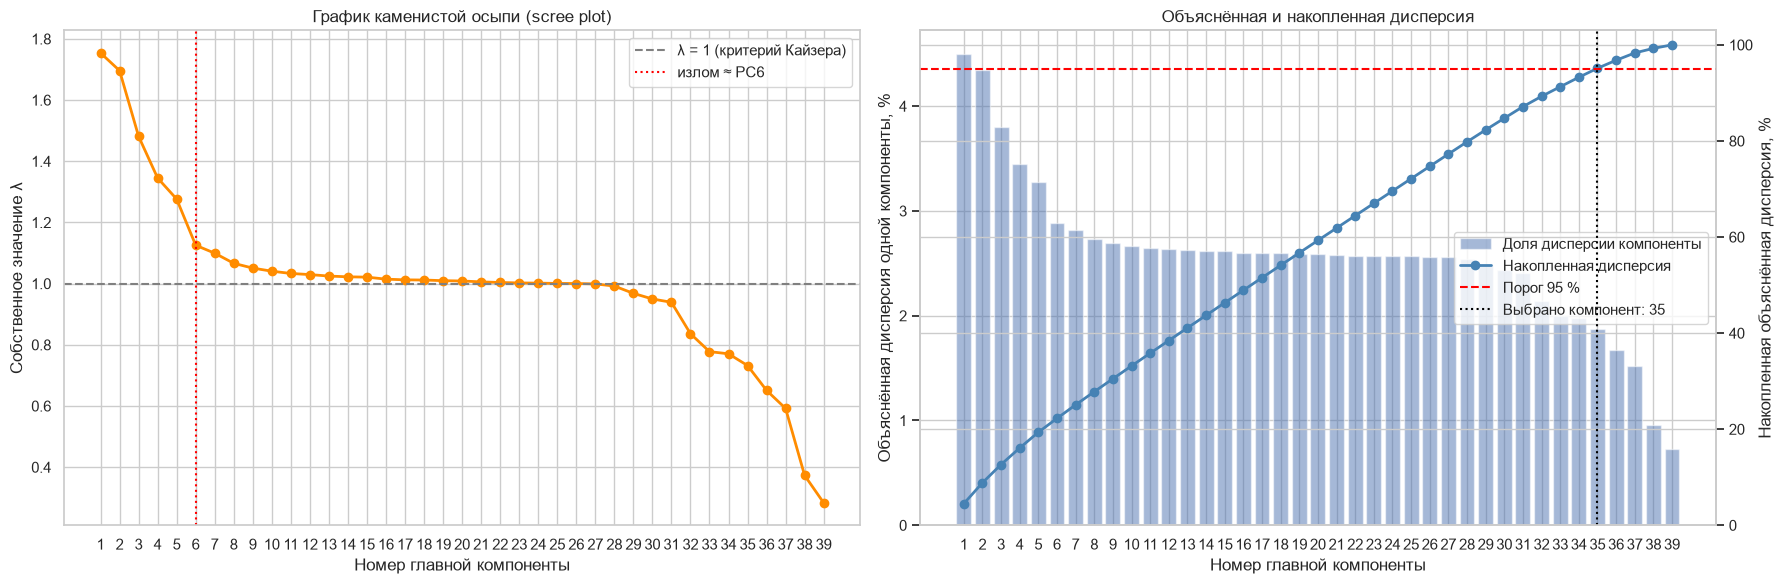

Для ≥ 80% дисперсии нужно компонент: 29
Для ≥ 90% дисперсии нужно компонент: 33
Для ≥ 95% дисперсии нужно компонент: 35
Для ≥ 99% дисперсии нужно компонент: 38


In [23]:
components = np.arange(1, len(explained_variance) + 1)

# Точка излома: начало «полки» - первая компонента, после которой собственное значение
# перестаёт заметно падать (разность соседних λ < 0.05)
eig = pca_full.explained_variance_
drops = -np.diff(eig)                                  # падение λ при переходе k -> k+1
elbow = int(np.argmax(drops < 0.05) + 1)
print("Падение λ между соседними компонентами (первые 8):", np.round(drops[:8], 3))
print(f"Собственные значения > 1 (критерий Кайзера): {(eig > 1).sum()} компонент(ы)")
print(f"Точка излома (начало полки, падение λ < 0.05): компонента {elbow}")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# График каменистой осыпи (scree plot): собственные значения по номерам компонент
axes[0].plot(components, eig, marker="o", color="darkorange", linewidth=2)
axes[0].axhline(1, color="gray", linestyle="--", label="λ = 1 (критерий Кайзера)")
axes[0].axvline(elbow, color="red", linestyle=":", label=f"излом ≈ PC{elbow}")
axes[0].set_title("График каменистой осыпи (scree plot)")
axes[0].set_xlabel("Номер главной компоненты")
axes[0].set_ylabel("Собственное значение λ")
axes[0].set_xticks(components)
axes[0].legend()

axes[1].bar(components, explained_variance * 100, alpha=0.5, label="Доля дисперсии компоненты")
axes[1].set_xlabel("Номер главной компоненты")
axes[1].set_ylabel("Объяснённая дисперсия одной компоненты, %")
axes[1].set_xticks(components)
ax2 = axes[1].twinx()
ax2.plot(components, cumulative_variance * 100, marker="o", color="steelblue", linewidth=2, label="Накопленная дисперсия")
ax2.axhline(95, color="red", linestyle="--", label="Порог 95 %")
ax2.axvline(n_components_95, color="black", linestyle=":", label=f"Выбрано компонент: {n_components_95}")
ax2.set_ylabel("Накопленная объяснённая дисперсия, %")
ax2.set_ylim(0, 103)
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="center right")
axes[1].set_title("Объяснённая и накопленная дисперсия")
plt.tight_layout()
plt.show()

for thr in (0.80, 0.90, 0.95, 0.99):
    print(f"Для ≥ {thr:.0%} дисперсии нужно компонент: {int(np.argmax(cumulative_variance >= thr) + 1)}")

**График «каменистой осыпи» (scree plot)** - слева; собственные значения λ по номерам компонент. Справа - объяснённая и накопленная дисперсия.

- Кривая быстро падает на первых 6 компонентах (с 1.75 до 1.13), затем идёт **длинная плоская «полка»** около λ = 1.0 (компоненты 7-28), после чего резко обрывается (λ от 0.84 до 0.28). **Точка излома** отмечена красной пунктирной линией (начало полки - компонента 6: после неё падение λ между соседними компонентами меньше 0.05). Критерий Кайзера (λ > 1) сохраняет **26 компонент**.
- Критерий излома (метод «каменистой осыпи») подсказывает оставить около 6 компонент, но они объясняют лишь 22.3 % дисперсии - потеря информации огромна. Критерий Кайзера (26 компонент, 74.7 % дисперсии) и порог 95 % (35 компонент) дают более безопасные оценки. Причина расхождения - отсутствие реальной «скрытой структуры» в данных: почти все признаки независимы, поэтому сжать их без потери информации невозможно.
- В работе выбран порог **95 %** (35 компонент) как консервативный вариант, сохраняющий информацию. Ниже (ячейка со сравнением числа компонент) показано, как падает качество при меньшем числе компонент.

PC1 (объясняет 4.50 % дисперсии) - сильнейшие нагрузки:


,Road_Surface_Conditions_Wet or damp,Weather_Conditions_Raining no high winds,Road_Surface_Conditions_Snow,Weather_Conditions_Snowing no high winds,Longitude,Weather_Conditions_Raining + high winds
PC1,0.572,0.515,-0.362,-0.342,-0.171,0.156


PC2 (объясняет 4.35 % дисперсии) - сильнейшие нагрузки:


,Road_Surface_Conditions_Snow,Weather_Conditions_Snowing no high winds,Urban_or_Rural_Area_Rural,Light_Conditions_Darkness - no lighting,Latitude,Longitude
PC2,0.48,0.459,0.343,0.32,0.273,-0.265


PC3 (объясняет 3.80 % дисперсии) - сильнейшие нагрузки:


,Urban_or_Rural_Area_Rural,Light_Conditions_Darkness - lights lit,Road_Surface_Conditions_Snow,Light_Conditions_Darkness - no lighting,Weather_Conditions_Snowing no high winds,Weather_Conditions_Raining no high winds
PC3,0.421,-0.407,-0.344,0.343,-0.312,-0.308


PC4 (объясняет 3.45 % дисперсии) - сильнейшие нагрузки:


,Latitude,Longitude,Light_Conditions_Darkness - no lighting,Weather_Conditions_Other,Road_Surface_Conditions_Frost or ice,Urban_or_Rural_Area_Rural
PC4,0.596,-0.585,-0.269,-0.211,-0.181,-0.181


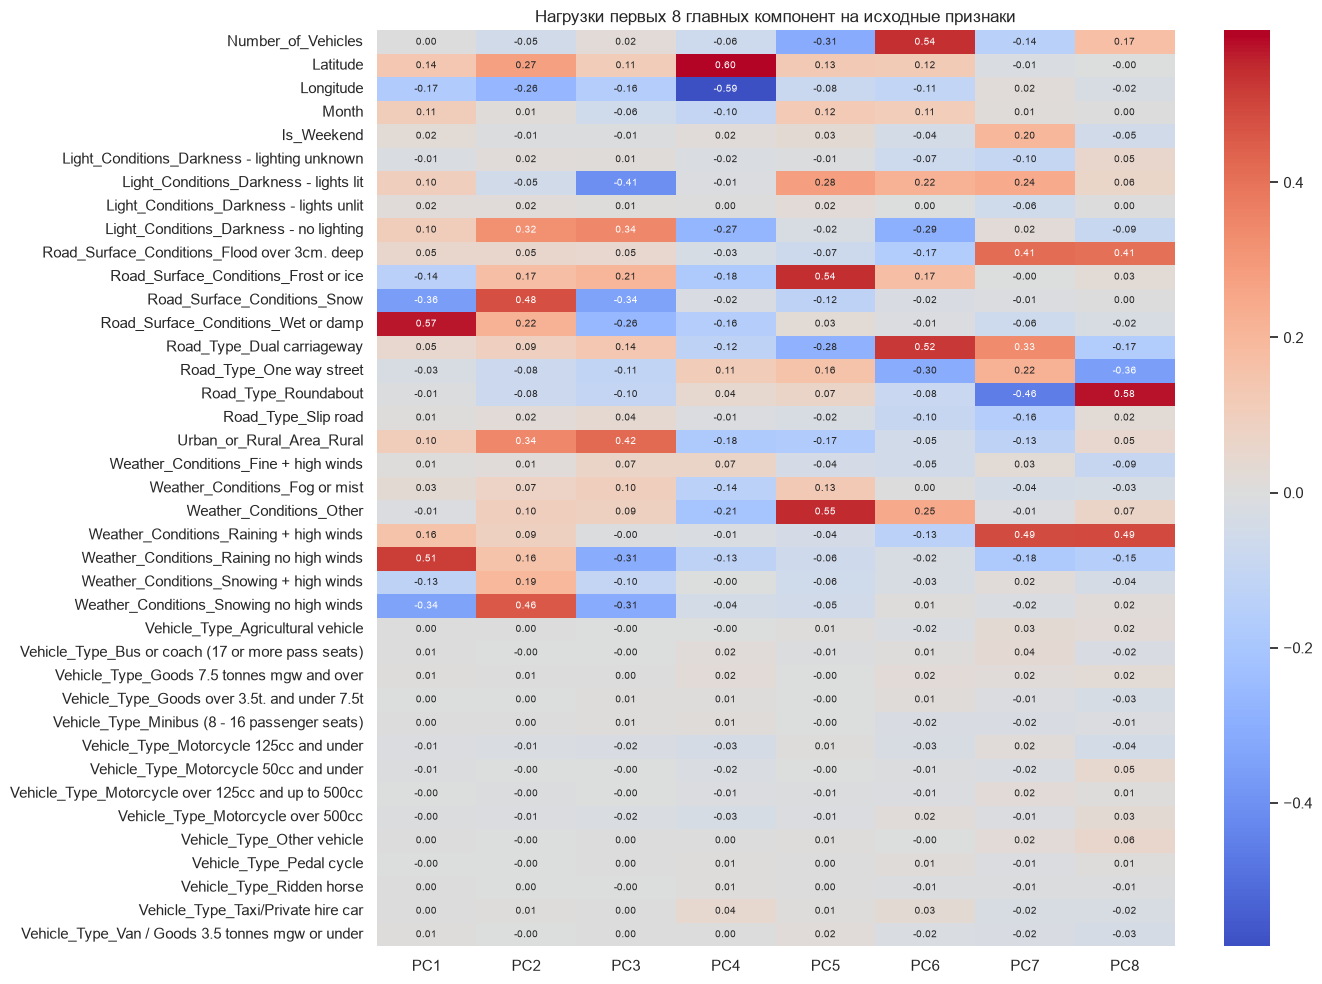

In [24]:
# Нагрузки компонент: коэффициенты линейных комбинаций исходных (стандартизованных) признаков
pc_cols = [f"PC{i}" for i in range(1, n_components_95 + 1)]
loadings = pd.DataFrame(pca_full.components_[:n_components_95].T, index=feature_names, columns=pc_cols)

for pc in ["PC1", "PC2", "PC3", "PC4"]:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(f"{pc} (объясняет {explained_variance[int(pc[2:]) - 1] * 100:.2f} % дисперсии) - сильнейшие нагрузки:")
    display(loadings.loc[top, [pc]].round(3).T)

plt.figure(figsize=(14, 10))
sns.heatmap(loadings.iloc[:, :8], cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Нагрузки первых 8 главных компонент на исходные признаки")
plt.tight_layout()
plt.show()

**Нагрузки компонент** (`pca_full.components_`) - веса исходных стандартизованных признаков в компоненте; чем больше по модулю, тем сильнее связь. Интерпретация первых компонент:

- **PC1 (4.50 %)** - «**дождь и мокрая дорога против снега**»: `Road_Surface_Conditions_Wet or damp` (+0.572) и `Weather_Conditions_Raining no high winds` (+0.515) с одной стороны, `Snow` (−0.362) и `Snowing no high winds` (−0.342) - с другой. Это ось «дождливая погода vs. снегопад».
- **PC2 (4.35 %)** - «**снег, сельская тёмная местность, север**»: `Snow` (+0.480), `Snowing no high winds` (+0.459), `Rural` (+0.343), `Darkness - no lighting` (+0.320), `Latitude` (+0.273), `Longitude` (−0.265): холодные, сельские и северные районы.
- **PC3 (3.80 %)** - «**село и темнота без освещения против освещённой темноты**»: `Rural` (+0.421), `Darkness - no lighting` (+0.343) против `Darkness - lights lit` (−0.407).
- **PC4 (3.45 %)** - «**география**»: `Latitude` (+0.596) и `Longitude` (−0.585) - положение на карте (северо-запад / юго-восток), так как широта и долгота коррелируют (−0.40).

Отдельной компоненты, соответствующей `Number_of_Vehicles` (самому важному признаку), среди первых четырёх нет: он почти не коррелирует с остальными признаками и распределён по более поздним компонентам - его нагрузки по модулю: **0.31 на PC5, 0.54 на PC6 и 0.54 на PC31** (расчёт `np.abs(pca_full.components_[:, 0])`). Это важно для понимания результата в следующем разделе: компонента PC31 - одна из тех, что отбрасываются при малом числе компонент.

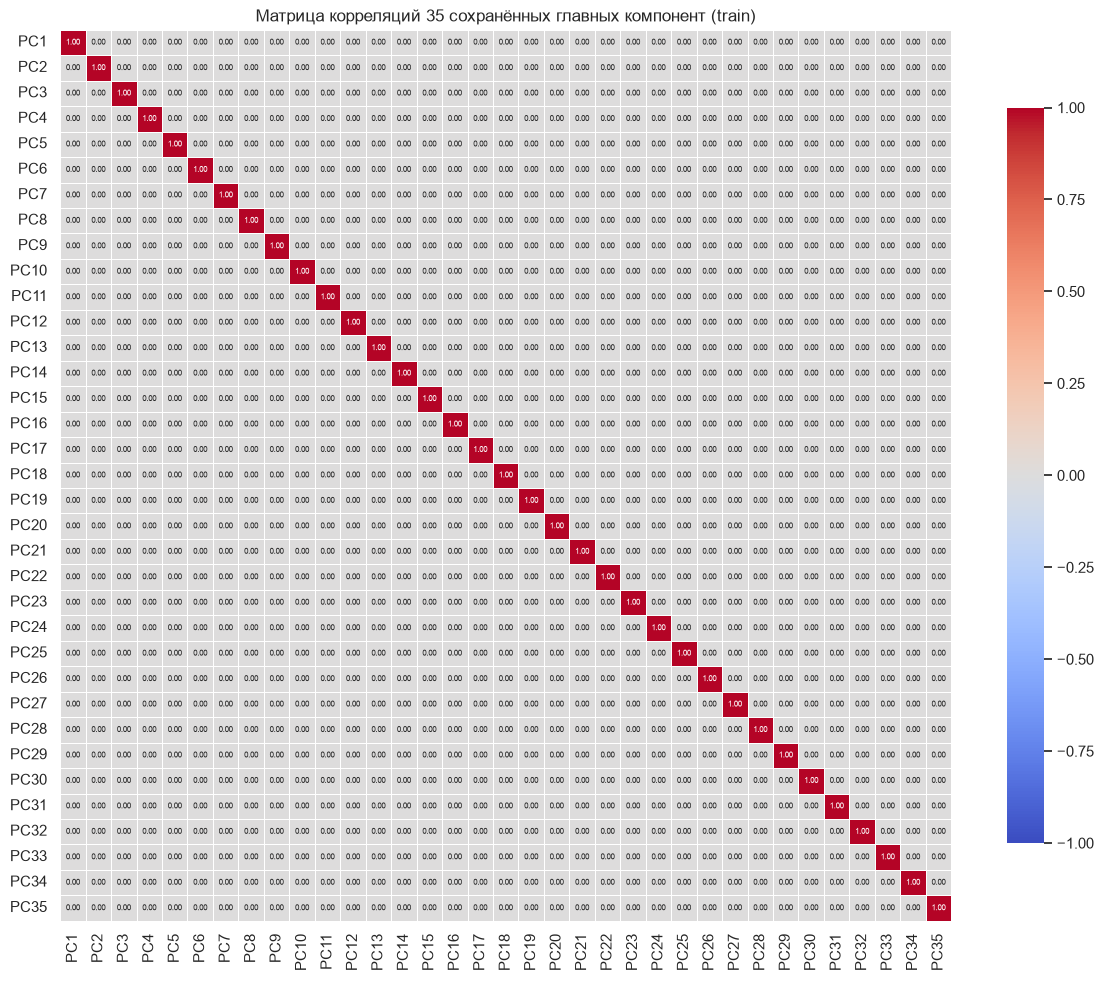

Число компонент в матрице: 35
Максимальная |корреляция| между разными компонентами: 1.228e-12
VIF компонент: min = 1.000000, max = 1.000000
Для сравнения, VIF исходных признаков: max = 1.815


In [25]:
# Проверка устранения мультиколлинеарности: корреляции и VIF сохранённых компонент (train)
Z_pc = X_train_pca_full[:, :n_components_95]
pc_corr = np.corrcoef(Z_pc, rowvar=False)
off_diag = pc_corr - np.eye(n_components_95)
max_abs_corr = np.abs(off_diag).max()

pc_names = [f"PC{i}" for i in range(1, n_components_95 + 1)]
plt.figure(figsize=(12, 10))
sns.heatmap(pd.DataFrame(pc_corr, index=pc_names, columns=pc_names).where(lambda d: d.abs() >= 0.005, 0.0),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.4, annot_kws={"size": 6}, cbar_kws={"shrink": 0.8})
plt.title(f"Матрица корреляций {n_components_95} сохранённых главных компонент (train)")
plt.tight_layout()
plt.show()

vif_pc = compute_vif(pd.DataFrame(Z_pc, columns=pc_names))
print(f"Число компонент в матрице: {n_components_95}")
print(f"Максимальная |корреляция| между разными компонентами: {max_abs_corr:.3e}")
print(f"VIF компонент: min = {vif_pc['VIF'].min():.6f}, max = {vif_pc['VIF'].max():.6f}")
print(f"Для сравнения, VIF исходных признаков: max = {vif_table['VIF'].max():.3f}")

**Проверка устранения мультиколлинеарности после PCA.** На тепловой карте показаны корреляции **35 сохранённых компонент** (то есть именно признаки, подающиеся в регрессию). Диагональ равна 1, все недиагональные значения равны нулю: максимальная по модулю корреляция между разными компонентами - **1.2·10⁻¹²** (нуль в пределах точности вычислений). VIF каждой компоненты равен **1.000000** (минимально возможное значение), тогда как у исходных признаков максимум был 1.815. **Линейная корреляционная связь между входами регрессии полностью отсутствует**, то есть мультиколлинеарность устранена (хотя в данных её и без PCA практически не было).

### Регрессия на главных компонентах

In [26]:
def make_pca_pipeline(regressor):
    """preprocessor -> стандартизация -> PCA (95 % дисперсии) -> регрессор. Всё обучается заново в каждом фолде CV."""
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("feature_scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
        ("regressor", clone(regressor)),
    ])

pca_models, pca_searches, pca_rows = {}, {}, []
for model_name, regressor in regressors.items():
    fitted, row = fit_and_score(model_name, regressor, make_pca_pipeline,
                                X_train, y_train, X_test, y_test, pca_searches)
    row = {"Модель": row.pop("Модель"), "Компонент": fitted.named_steps["pca"].n_components_, **row}
    pca_models[model_name] = fitted
    pca_rows.append(row)

pca_results = pd.DataFrame(pca_rows).set_index("Модель")
print("Качество моделей на главных компонентах (alpha для Ridge/Lasso выбрана по CV):")
display(pca_results[["Выбранная alpha", "Компонент", "CV RMSE, среднее", "CV RMSE, std", "CV R², среднее", "CV MAE, среднее", "CV MAPE, %"]].round(4))
display(pca_results[[c for c in pca_results.columns if c.startswith(("Train", "Тест"))]].round(4))

pca_coef_rows = []
for model_name, model in pca_models.items():
    reg = model.named_steps["regressor"]
    row = {"Модель": model_name, "Свободный член": reg.intercept_}
    row.update({f"PC{i + 1}": v for i, v in enumerate(reg.coef_)})
    pca_coef_rows.append(row)
print("Коэффициенты регрессий в координатах главных компонент:")
display(pd.DataFrame(pca_coef_rows).set_index("Модель").round(4))

/private/tmp/claude-501/-Users-sedooj-Downloads-lab1-c/b75236d7-7c64-471c-a5dc-702f28d05b98/scratchpad/venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Качество моделей на главных компонентах (alpha для Ridge/Lasso выбрана по CV):


,Выбранная alpha,Компонент,"CV RMSE, среднее","CV RMSE, std","CV R², среднее","CV MAE, среднее","CV MAPE, %"
Модель,,,,,,,
Линейная регрессия,не применяется,35,0.7973,0.0235,0.0703,0.5009,33.8389
Ridge,1000.0,35,0.7973,0.0210,0.0703,0.5010,33.8439
Lasso,0.0001,35,0.7973,0.0210,0.0703,0.5010,33.8420


,Train RMSE,Train MAE,Train R2,"Train MAPE, %",Тест RMSE,Тест MAE,Тест R2,"Тест MAPE, %"
Модель,,,,,,,,
Линейная регрессия,0.7975,0.5009,0.0704,33.8354,0.8008,0.5003,0.0734,33.8295
Ridge,0.7975,0.5010,0.0704,33.8393,0.8008,0.5004,0.0734,33.8335
Lasso,0.7975,0.5009,0.0704,33.8384,0.8008,0.5004,0.0734,33.8323


Коэффициенты регрессий в координатах главных компонент:


,Свободный член,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35
Модель,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Линейная регрессия,1.3605,0.0339,0.0423,0.0426,-0.0172,-0.0689,0.1095,-0.0124,0.0200,0.0058,0.0008,-0.0008,-0.0029,-0.0036,-0.0042,-0.0031,0.0110,-0.0117,-0.0144,-0.0045,0.0017,0.0116,0.0089,0.0006,-0.0039,-0.0075,0.0028,-0.0049,0.0138,-0.0118,-0.0211,0.0974,-0.0286,-0.0137,0.0567,0.0903
Ridge,1.3605,0.0339,0.0422,0.0426,-0.0172,-0.0688,0.1093,-0.0123,0.0200,0.0058,0.0008,-0.0008,-0.0028,-0.0036,-0.0042,-0.0031,0.0110,-0.0117,-0.0143,-0.0045,0.0017,0.0116,0.0089,0.0006,-0.0039,-0.0075,0.0028,-0.0049,0.0138,-0.0118,-0.0211,0.0972,-0.0286,-0.0137,0.0566,0.0901
Lasso,1.3605,0.0339,0.0422,0.0426,-0.0171,-0.0688,0.1094,-0.0123,0.0199,0.0057,0.0007,-0.0007,-0.0028,-0.0035,-0.0041,-0.0030,0.0109,-0.0116,-0.0143,-0.0044,0.0016,0.0115,0.0088,0.0005,-0.0038,-0.0074,0.0027,-0.0048,0.0137,-0.0117,-0.0210,0.0973,-0.0285,-0.0136,0.0566,0.0902


**Pipeline после PCA:** `preprocessor → feature_scaler → PCA(n_components=0.95) → regressor`. Все шаги, включая PCA, при кросс-валидации **заново обучаются только на обучающей части каждого фолда**: в `GridSearchCV` `Pipeline` клонируется и обучается на каждом из пяти разбиений, поэтому утечки данных нет; затем лучший `Pipeline` переобучается на всём `X_train`, а `X_test` только преобразуется и используется для оценки. Правила оценки те же, что и до PCA: **те же** тестовые наблюдения, те же 5 фолдов (`cv`), та же сетка alpha и те же метрики - сравнение корректно.

| Модель | alpha | Компонент | CV RMSE | CV R² | CV MAPE, % | Тест RMSE | Тест R² | Тест MAPE, % |
|---|---|---|---|---|---|---|---|---|
| Линейная регрессия | - | 35 | 0.7973 | 0.0703 | 33.84 | 0.8008 | 0.0734 | 33.83 |
| Ridge | 1000 | 35 | 0.7973 | 0.0703 | 33.84 | 0.8008 | 0.0734 | 33.83 |
| Lasso | 0.0001 | 35 | 0.7973 | 0.0703 | 33.84 | 0.8008 | 0.0734 | 33.83 |

1. Все три модели снова **неразличимы** (тест RMSE 0.8008, R² 0.0734). Регуляризация ничего не добавляет: Lasso выбрал минимальную alpha из сетки (0.0001), Ridge - 1000 при плоской кривой.
2. **Переобучения нет**: RMSE train 0.7975, CV 0.7973, тест 0.8008.
3. **Качество практически не изменилось** по сравнению с исходными признаками (подробнее - в следующем разделе): тест RMSE 0.8007 → 0.8008, R² 0.0737 → 0.0734.

**Коэффициенты в координатах главных компонент** (таблица): свободный член 1.3605 - среднее цели на обучении. Столбцы PC1-PC35 - веса компонент, а не исходных признаков, поэтому «Number_of_Vehicles» отдельно не виден. Размер коэффициента зависит от масштаба компоненты (std компоненты = √λ), поэтому для сравнения вкладов надо умножать на √λ. Показательно, что **вклад не убывает с номером компоненты**: самые крупные коэффициенты - у PC6 (0.109), PC31 (0.097), PC35 (0.090), PC5 (−0.069), PC34 (0.057), а у PC1 лишь 0.034. То есть значимой для цели информации много именно в поздних компонентах (`Number_of_Vehicles` входит в PC5, PC6 и PC31 с нагрузками 0.31, 0.54 и 0.54), и поэтому отбрасывание поздних компонент ухудшает прогноз (см. ниже). Коэффициенты МНК, Ridge и Lasso по всем компонентам почти совпадают.

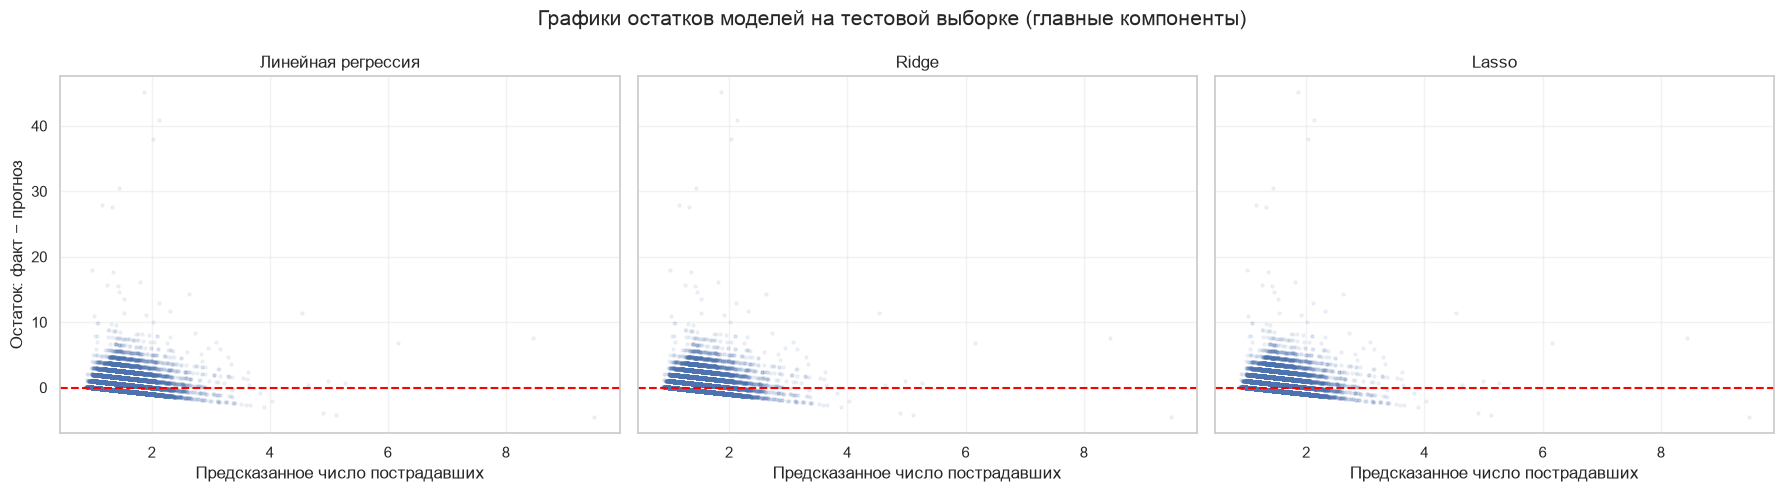

,LM-статистика,p-value (LM),F-статистика,p-value (F)
Модель,,,,
Линейная регрессия,404.4659,2.0990e-64,11.5889,1.6172e-64
Ridge,404.5293,2.0387e-64,11.5907,1.5706e-64
Lasso,404.5322,2.0360e-64,11.5908,1.5685e-64


In [27]:
residual_plot(pca_models, "Графики остатков моделей на тестовой выборке (главные компоненты)", X_test, y_test)

bp_rows = []
for model_name, fitted_model in pca_models.items():
    Z = fitted_model[:-1].transform(X_test)
    r = y_test.to_numpy() - fitted_model.predict(X_test)
    lm, lm_p, f_stat, f_p = het_breuschpagan(r, add_constant(Z))
    bp_rows.append({"Модель": model_name, "LM-статистика": lm, "p-value (LM)": lm_p, "F-статистика": f_stat, "p-value (F)": f_p})
display(pd.DataFrame(bp_rows).set_index("Модель"))

Графики остатков моделей на компонентах **неотличимы от графиков на исходных признаках**: та же диагональная структура из-за дискретности цели и тот же «веер» (рост разброса с ростом прогноза). Тест Бройша-Пагана: LM = 404.5, p ≈ 2·10⁻⁶⁴ - гетероскедастичность сохраняется. PCA - это линейное преобразование признаков, поэтому природа ошибок модели не меняется: нарушение гомоскедастичности порождено свойствами целевой переменной (счётный, скошенный), а не мультиколлинеарностью.

### Сравнение регрессии на исходных признаках и после PCA

Не следует заранее считать PCA обязательным улучшением: его основная цель здесь - получить компактные некоррелированные признаки. В задаче прогнозирования PCA может как улучшить устойчивость регрессии, так и ухудшить качество из-за потери компонент с небольшой дисперсией, но важной связью с целевой переменной. Практический выбор делается на основании результатов тестирования, а не только процента сохранённой дисперсии.

Сводное сравнение всех шести моделей:


,Представление признаков,Модель,CV RMSE,Тест RMSE,CV R²,Тест R²,Тест MAE,"CV MAPE, %","Тест MAPE, %"
0,Исходные признаки,Линейная регрессия,0.7972,0.8007,0.0705,0.0737,0.5001,33.8235,33.8126
1,Исходные признаки,Ridge,0.7972,0.8007,0.0705,0.0737,0.5002,33.8284,33.8165
2,Исходные признаки,Lasso,0.7972,0.8007,0.0705,0.0737,0.5003,33.8365,33.8221
3,Главные компоненты PCA,Линейная регрессия,0.7973,0.8008,0.0703,0.0734,0.5003,33.8389,33.8295
4,Главные компоненты PCA,Ridge,0.7973,0.8008,0.0703,0.0734,0.5004,33.8439,33.8335
5,Главные компоненты PCA,Lasso,0.7973,0.8008,0.0703,0.0734,0.5004,33.8420,33.8323


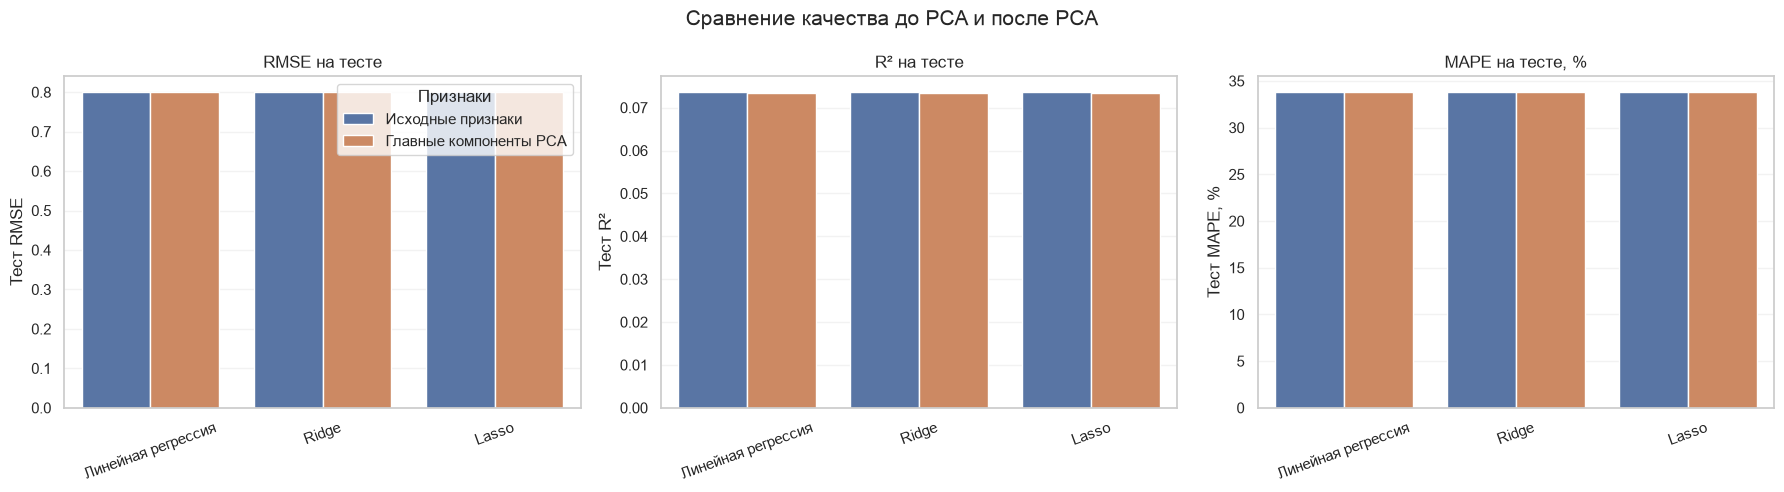

,ΔRMSE (PCA − исх.),ΔR²,"ΔMAPE, п.п.",Вердикт по RMSE
Модель,,,,
Линейная регрессия,0.0001,-0.0003,0.0169,PCA хуже
Ridge,0.0001,-0.0003,0.0170,PCA хуже
Lasso,0.0001,-0.0003,0.0102,PCA хуже


In [28]:
comparison_rows = []
for representation, results_df in [("Исходные признаки", baseline_results), ("Главные компоненты PCA", pca_results)]:
    for model_name, row in results_df.iterrows():
        comparison_rows.append({
            "Представление признаков": representation, "Модель": model_name,
            "CV RMSE": row["CV RMSE, среднее"], "Тест RMSE": row["Тест RMSE"],
            "CV R²": row["CV R², среднее"], "Тест R²": row["Тест R2"],
            "Тест MAE": row["Тест MAE"], "CV MAPE, %": row["CV MAPE, %"], "Тест MAPE, %": row["Тест MAPE, %"],
        })
comparison_results = pd.DataFrame(comparison_rows)
print("Сводное сравнение всех шести моделей:")
display(comparison_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (metric_col, plot_title) in zip(axes, [("Тест RMSE", "RMSE на тесте"), ("Тест R²", "R² на тесте"), ("Тест MAPE, %", "MAPE на тесте, %")]):
    sns.barplot(data=comparison_results, x="Модель", y=metric_col, hue="Представление признаков", ax=ax)
    ax.set_title(plot_title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
    if ax is not axes[0] and ax.get_legend() is not None:
        ax.get_legend().remove()
axes[0].legend(title="Признаки", loc="best")
plt.suptitle("Сравнение качества до PCA и после PCA", fontsize=15)
plt.tight_layout()
plt.show()

# Изменение метрик при переходе к PCA (на тесте)
delta = []
for model_name in regressors:
    b, p = baseline_results.loc[model_name], pca_results.loc[model_name]
    delta.append({"Модель": model_name,
                  "ΔRMSE (PCA − исх.)": p["Тест RMSE"] - b["Тест RMSE"],
                  "ΔR²": p["Тест R2"] - b["Тест R2"],
                  "ΔMAPE, п.п.": p["Тест MAPE, %"] - b["Тест MAPE, %"],
                  "Вердикт по RMSE": "PCA лучше" if p["Тест RMSE"] < b["Тест RMSE"] else "PCA хуже"})
display(pd.DataFrame(delta).set_index("Модель").round(5))

Для каждой метрики построена отдельная панель (единицы RMSE, R² и MAPE несопоставимы). Все шесть столбцов на каждой панели почти одной высоты.

| Метрика (тест) | Исходные признаки | PCA (35 компонент) | Изменение |
|---|---|---|---|
| RMSE | 0.8007 | 0.8008 | +0.0001 (+0.01 %) |
| R² | 0.0737 | 0.0734 | −0.0003 |
| MAPE, % | 33.81-33.82 | 33.83 | +0.01…0.02 п.п. |
| CV RMSE | 0.7972 | 0.7973 | +0.0001 |

- По всем метрикам **PCA чуть хуже**, но разница - в пятом знаке и **на два порядка меньше разброса между фолдами** (std 0.02): ею можно пренебречь, то есть **качество практически не изменилось**. В таблице «Вердикт по RMSE» «PCA хуже» формально для всех трёх моделей, но различия статистически не значимы.
- **Почему PCA ничего не улучшил:** (1) мультиколлинеарности в данных нет (VIF < 2), PCA нечего «лечить»; (2) PCA отбирает компоненты по дисперсии признаков, а не по связи с целью: потеряны 4 последние компоненты (4.9 % дисперсии), и они унесли немного информации о цели; (3) число данных огромно, поэтому МНК и без PCA устойчив.
- **Снижение размерности ощутимо мало**: 39 → 35 признаков (на 10 %), потому что данные не имеют скрытой низкоразмерной структуры. Выигрыш PCA - в некоррелированности признаков, а не в точности.
- Лучшая **по CV RMSE** формально Lasso на исходных признаках (0.7972), но все шесть моделей неразличимы в пределах шума. Практически разумный выбор - **простая линейная регрессия на исходных признаках**: она проще и **интерпретируема** (коэффициенты имеют смысл «пострадавших на единицу признака»), тогда как после PCA коэффициенты относятся к компонентам.

Линейная регрессия на исходных признаках, тест:      RMSE = 0.800677, R² = 0.073659
Линейная регрессия на ВСЕХ 39 компонентах, тест: RMSE = 0.800677, R² = 0.073659


,"Накопл. дисперсия, %",Тест RMSE,Тест R²,"Тест MAPE, %"
Компонент,,,,
1,4.4973,0.8307,0.0028,37.0148
2,8.8463,0.8290,0.0070,36.7878
3,12.6445,0.8274,0.0109,36.5804
5,19.3658,0.8229,0.0215,36.1122
8,27.8044,0.8136,0.0435,35.7641
10,33.1666,0.8136,0.0435,35.7652
15,46.3219,0.8136,0.0435,35.7662
35,95.1297,0.8008,0.0734,33.8295
20,59.2877,0.8132,0.0444,35.7838


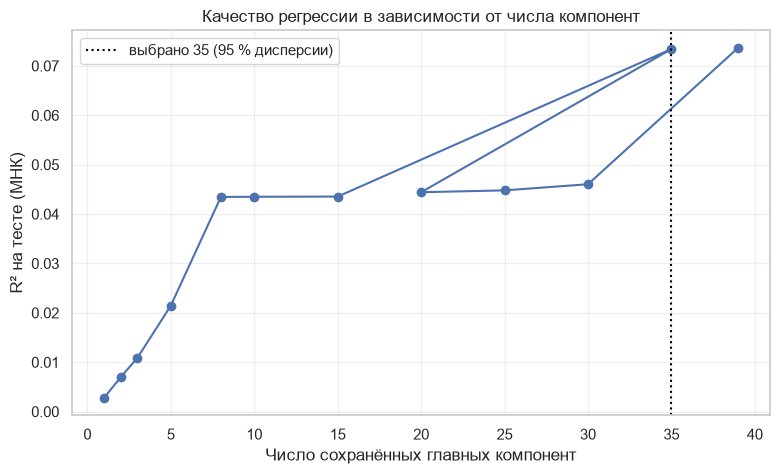

In [29]:
# Проверка: PCA без отбрасывания компонент - это лишь поворот осей, качество МНК не должно измениться
full_pca_pipe = Pipeline([("preprocessor", clone(preprocessor)), ("feature_scaler", StandardScaler()),
                          ("pca", PCA(n_components=None)), ("regressor", LinearRegression())]).fit(X_train, y_train)
m_full = evaluate(y_test, full_pca_pipe.predict(X_test))
m_base = evaluate(y_test, baseline_models["Линейная регрессия"].predict(X_test))
print(f"Линейная регрессия на исходных признаках, тест:      RMSE = {m_base['RMSE']:.6f}, R² = {m_base['R2']:.6f}")
print(f"Линейная регрессия на ВСЕХ {full_pca_pipe.named_steps['pca'].n_components_} компонентах, тест: RMSE = {m_full['RMSE']:.6f}, R² = {m_full['R2']:.6f}")

# Как меняется качество с числом сохранённых компонент (МНК, тест)
k_rows = []
Z_tr_all, Z_te_all = X_train_pca_full, X_test_pca_full
for k in [1, 2, 3, 5, 8, 10, 15, n_components_95, 20, 25, 30, Z_tr_all.shape[1]]:
    if k > Z_tr_all.shape[1]:
        continue
    lr = LinearRegression().fit(Z_tr_all[:, :k], y_train)
    m = evaluate(y_test, lr.predict(Z_te_all[:, :k]))
    k_rows.append({"Компонент": k, "Накопл. дисперсия, %": cumulative_variance[k - 1] * 100, "Тест RMSE": m["RMSE"], "Тест R²": m["R2"], "Тест MAPE, %": m["MAPE, %"]})
k_table = pd.DataFrame(k_rows).drop_duplicates("Компонент").set_index("Компонент")
display(k_table.round(4))

plt.figure(figsize=(9, 5))
plt.plot(k_table.index, k_table["Тест R²"], marker="o")
plt.axvline(n_components_95, color="black", linestyle=":", label=f"выбрано {n_components_95} (95 % дисперсии)")
plt.xlabel("Число сохранённых главных компонент")
plt.ylabel("R² на тесте (МНК)")
plt.title("Качество регрессии в зависимости от числа компонент")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Контроль корректности.** Линейная регрессия на **всех 39** компонентах даёт ровно те же метрики, что и на исходных признаках (RMSE 0.800677, R² 0.073659 в обоих случаях): PCA без отбрасывания компонент - это лишь **поворот системы координат**, не меняющий пространство признаков. Значит, любое различие в качестве вызывается только отбрасыванием компонент.

**Качество в зависимости от числа компонент** (тест, МНК):

| Компонент | Накопл. дисперсия, % | Тест RMSE | Тест R² |
|---|---|---|---|
| 1 | 4.5 | 0.8307 | 0.003 |
| 5 | 19.4 | 0.8229 | 0.022 |
| 8-15 | 27.8-46.3 | 0.8136 | 0.044 |
| 25 | 72.1 | 0.8131 | 0.045 |
| 30 | 84.7 | 0.8125 | 0.046 |
| **35** | **95.1** | **0.8008** | **0.073** |
| 39 | 100 | 0.8007 | 0.074 |

Качество остаётся низким до 30 компонент и **скачком** улучшается между 30 и 35: ключевой вклад даёт компонента PC31 (нагрузка `Number_of_Vehicles` 0.54, коэффициент регрессии 0.097): это самый сильный признак, но он почти не коррелирует с остальными, поэтому PCA «раскладывает» его по компонентам с небольшой дисперсией (PC5, PC6, PC31). Скачок R² между 5 и 8 компонентами (0.022 → 0.044) связан с PC6 (нагрузка 0.54, коэффициент 0.109). Это показывает, что **порог 95 % выбран обоснованно**, а правило «излома» (5-8 компонент, R² 0.02-0.04) привело бы к катастрофической потере качества. Идея «дисперсия = информативность» неприменима, когда информативный признак не связан с остальными.

In [30]:
# Правило выбора лучшей модели: минимальный CV RMSE (тест в выборе не участвует).
# При равенстве в пределах шума (разность < std между фолдами) предпочитаем более простую модель.
all_results = pd.concat({"Исходные признаки": baseline_results, "PCA": pca_results}, names=["Представление", "Модель"])
ranking = all_results[["CV RMSE, среднее", "CV RMSE, std", "Тест RMSE", "Тест R2", "Тест MAPE, %"]].sort_values("CV RMSE, среднее")
display(ranking.round(4))

best_key = ranking.index[0]
best_cv = ranking.iloc[0]["CV RMSE, среднее"]
noise = ranking.iloc[0]["CV RMSE, std"]
tied = ranking[ranking["CV RMSE, среднее"] - best_cv < noise]
print(f"Лучшая по CV RMSE: {best_key}  (CV RMSE = {best_cv:.4f}; разброс между фолдами ≈ {noise:.4f})")
print("Модели, неотличимые от лучшей в пределах разброса фолдов:", [k for k in tied.index])

# Контрольная проверка: сравнение с ориентиром «прогноз = среднее»
best_te = ranking.iloc[0]
print(f"\nУлучшение RMSE относительно прогноза средним: {base_metrics['RMSE']:.4f} → {best_te['Тест RMSE']:.4f} "
      f"({(1 - best_te['Тест RMSE'] / base_metrics['RMSE']) * 100:.2f} %)")

CV RMSE, среднее  CV RMSE, std  Тест RMSE  Тест R2  Тест MAPE, %
Представление     Модель                                                                              
Исходные признаки Lasso                         0.7972        0.0210     0.8007   0.0737       33.8221
                  Ridge                         0.7972        0.0210     0.8007   0.0737       33.8165
                  Линейная регрессия            0.7972        0.0235     0.8007   0.0737       33.8126
PCA               Lasso                         0.7973        0.0210     0.8008   0.0734       33.8323
                  Ridge                         0.7973        0.0210     0.8008   0.0734       33.8335
                  Линейная регрессия            0.7973        0.0235     0.8008   0.0734       33.8295

Лучшая по CV RMSE: ('Исходные признаки', 'Lasso')  (CV RMSE = 0.7972; разброс между фолдами ≈ 0.0210)
Модели, неотличимые от лучшей в пределах разброса фолдов: [('Исходные признаки', 'Lasso'), ('Исходные признаки', 'Ridge'), ('Исходные признаки', 'Линейная регрессия'), ('PCA', 'Lasso'), ('PCA', 'Ridge'), ('PCA', 'Линейная регрессия')]

Улучшение RMSE относительно прогноза средним: 0.8319 → 0.8007 (3.75 %)


**Как определяется лучшая модель, если метрики расходятся.** Правило, заданное в коде: основной критерий - **минимальный CV RMSE** (он считается на обучающей выборке и не использует тест); если модели различаются меньше, чем разброс между фолдами, они считаются равноценными и выбирается более простая. Метрики здесь не противоречат друг другу (RMSE, R², MAPE меняются согласованно), но стоит помнить про компромисс: MAPE поощряет занижение, а RMSE - борьбу с крупными ошибками; поэтому основной критерий - RMSE/R², а MAPE используется как справочный.

Результат: формально первая строка - Lasso на исходных признаках (CV RMSE 0.7972), но **все шесть моделей лежат в пределах одного std между фолдами (≈ 0.021)** и статистически неразличимы. Улучшение относительно ориентира «прогноз = среднее» - **3.75 %** по RMSE (0.8319 → 0.8007).

In [31]:
# Дополнительный эксперимент (за рамками задания): как можно повысить точность?
from sklearn.linear_model import PoissonRegressor

def run_variant(name, X_tr, X_te, regressor, num, cat):
    pre = ColumnTransformer([("n", StandardScaler(), num), ("c", make_ohe(), cat)])
    pipe = Pipeline([("pre", pre), ("reg", regressor)]).fit(X_tr, y_train)
    pred = pipe.predict(X_te)
    return {"Вариант": name, **evaluate(y_test, pred), "Макс. прогноз": pred.max()}

rows = [run_variant("Линейная регрессия (базовая)", X_train, X_test, LinearRegression(), numeric_features, categorical_features),
        run_variant("Пуассоновская регрессия (целевая - счётчик)", X_train, X_test, PoissonRegressor(alpha=1e-4, max_iter=500), numeric_features, categorical_features)]

# Проверка гипотезы об утечке: добавим тяжесть ДТП (она известна только ПОСЛЕ ДТП - в основной модели не используется)
X_sev = X.assign(Accident_Severity=severity)
Xs_tr, Xs_te = X_sev.loc[X_train.index], X_sev.loc[X_test.index]
rows.append(run_variant("Линейная + Accident_Severity (утечка, только для сравнения)", Xs_tr, Xs_te, LinearRegression(),
                        numeric_features, categorical_features + ["Accident_Severity"]))
display(pd.DataFrame(rows).set_index("Вариант").round(4))

,RMSE,MAE,R2,"MAPE, %",Макс. прогноз
Вариант,,,,,
Линейная регрессия (базовая),0.8007,0.5001,0.0737,33.8126,9.4743
Пуассоновская регрессия (целевая - счётчик),1.0512,0.5057,-0.5966,34.0299,227.3328
"Линейная + Accident_Severity (утечка, только для сравнения)",0.7972,0.4970,0.0818,33.6248,9.6671


**Анализ погрешности и возможности повышения точности** (дополнительный эксперимент, выходящий за рамки задания):

- Базовая линейная модель: RMSE 0.8007, R² 0.0737, MAPE 33.8 %.
- **Пуассоновская регрессия** (естественная модель для счётных данных, логарифмическая связь): **хуже** (R² < 0). Экспоненциальная связь приводит к огромным прогнозам для ДТП с экстремальным числом машин (`Макс. прогноз` в таблице - сотни пострадавших при фактическом максимуме 47-68), что катастрофически увеличивает RMSE. Кроме того, распределение цели недисперсионно (дисперсия < среднего), а пуассоновская модель предполагает равенство. Без дополнительной обработки редких экстремальных значений она не подходит.
- **Добавление тяжести ДТП (`Accident_Severity`)** даёт лишь небольшое улучшение (R² 0.074 → 0.082, RMSE 0.8007 → 0.7972), хотя этот признак - следствие числа пострадавших (утечка). То есть даже «подсказка» из будущего почти ничего не добавляет: потолок качества определяется отсутствием в данных важных факторов (скорость, тип удара, число людей в машинах).

**Причины ошибки модели и пути улучшения:** (1) главные факторы тяжести ДТП не представлены в данных; (2) цель дискретна, скошена и гетероскедастична, а линейная модель этого не учитывает; (3) редкие массовые аварии сильно раздувают RMSE. Улучшить можно: логарифмированием или ограничением (winsorizing) цели, моделями для счётных данных с регуляризацией крайних значений, нелинейными моделями и взаимодействиями признаков (например, `Number_of_Vehicles × Rural`), добавлением дополнительных признаков (скорость, число пассажиров). Регуляризация и масштабирование признаков, как показал эксперимент, на точность практически не влияют.

## Заключение

В ходе работы исследован набор данных о ДТП в Великобритании (670 679 записей, 14 столбцов). Целевая переменная `Number_of_Casualties` - число пострадавших - количественная (счётная), поэтому применялись модели регрессии. На этапе подготовки удалены 18 155 строк с пропусками, 9 строк-«заглушек» и 18 полных дубликатов (итого **652 497 строк**); столбец `Index` оказался испорчен Excel (36 % значений в формате `2.01E+12`) и исключён, как и дата, район и тяжесть ДТП (последняя - следствие, а не причина, утечка). Числовые признаки стандартизованы, шесть номинальных категориальных кодированы One-Hot с базой - самой частой категорией (**39 признаков**). Выборка разделена 80/20: **521 997** обучающих и **130 500** тестовых объектов, качество дополнительно оценивалось пятикратной кросс-валидацией внутри `Pipeline` без утечек.

Первичный анализ показал сильно правоскошенную дискретную цель (76.1 % ДТП - с одним пострадавшим, среднее 1.36, максимум 68). Самый сильный фактор - число транспортных средств (r = +0.23; +0.27 пострадавших на каждую дополнительную машину); заметны также сельская местность, темнота без освещения и двухполосные дороги; погода, тип ТС, месяц влияют слабо. Корреляционная матрица (максимум между признаками 0.60 у пар «снег - снегопад» и «мокро - дождь») и **VIF (максимум 1.8, при пороге 5-10)** показали, что **серьёзной мультиколлинеарности нет**; высокие VIF (до 63) появляются лишь как артефакт при редкой базовой категории dummy.

На исходных признаках линейная регрессия, Ridge и Lasso дали практически одинаковое качество: тестовый **RMSE ≈ 0.8007, R² ≈ 0.074, MAPE ≈ 33.8 %** (CV RMSE ≈ 0.797). Это на 3.75 % лучше прогноза «средним» (RMSE 0.8319), но R² невысок: модель объясняет только ≈ 7 % дисперсии, так как в данных нет ключевых факторов (скорость, характер столкновения, число людей в автомобилях). Переобучения нет (train, CV и тест совпадают), скорее недообучение. Регуляризация не дала выигрыша; Lasso обнулил 12 из 39 коэффициентов (малозначимые dummy). Высокий MAPE при R² ≈ 0.07 - особенность метрики при скошенной цели с модой 1 (прогноз «всегда 1» даёт MAPE 13.5 %).

Графики остатков и тест Бройша-Пагана (p ≈ 10⁻⁶³) выявили выраженную **гетероскедастичность**: разброс остатков растёт с прогнозом (std 0.47 → 1.15), структура остатков - «лесенка» из-за дискретной цели, плюс единичные выбросы от массовых аварий. Допущение МНК о постоянной дисперсии нарушено.

PCA после стандартизации устранил корреляции между входами (максимум 10⁻¹², VIF = 1), однако из-за отсутствия мультиколлинеарности спектр оказался плоским (почти все λ ≈ 1), для 95 % дисперсии потребовалось **35 из 39 компонент** (излом scree plot - около 6-й компоненты, критерий Кайзера - 26 компонент). Качество на главных компонентах **практически не изменилось** (тест RMSE 0.8008, R² 0.0734, MAPE 33.83 %, различие на два порядка меньше разброса между фолдами): PCA не улучшил точность, зато сделал коэффициенты неинтерпретируемыми; при урезании до 30 и менее компонент качество заметно падает (R² 0.07 → 0.05 и ниже), поскольку главный фактор - число машин - слабо коррелирует с остальными признаками и «рассеивается» по компонентам PC5, PC6 и PC31.

**Итог:** для данной задачи наиболее разумно использовать простую линейную регрессию (или Lasso для отбора признаков) на исходных признаках: она интерпретируема и не хуже вариантов с PCA. Для заметного улучшения точности нужны новые признаки и модели, учитывающие счётный, скошенный и гетероскедастичный характер цели.

## Список источников
1. Датасет «Accident Analysis Dataset» [Электронный ресурс]. - Kaggle. - URL: **[вставить ссылку на страницу датасета на Kaggle]** (дата обращения: 15.10.2026).
2. Road Safety Data (STATS19) [Электронный ресурс]. - Department for Transport (UK). - URL: https://www.data.gov.uk/dataset/cb7ae6f0-4be6-4935-9277-47e5ce24a11f/road-safety-data (первоисточник данных о ДТП).
3. Kaggle : официальный сайт платформы для соревнований по машинному обучению. - URL: https://www.kaggle.com
4. Scikit-learn: Machine Learning in Python [Электронный ресурс]. - URL: https://scikit-learn.org/stable/ (документация `LinearRegression`, `Ridge`, `Lasso`, `PCA`, `Pipeline`, `GridSearchCV`).
5. Statsmodels: Statistical modeling and econometrics in Python [Электронный ресурс]. - URL: https://www.statsmodels.org/stable/ (`variance_inflation_factor`, `het_breuschpagan`).
6. Электронный курс «Системы искусственного интеллекта и машинное обучение» в образовательной среде НГТУ НЭТИ Dispace 3.0. Постановка задачи к лабораторной работе №1 [Электронный ресурс]. - URL: https://dispace.nstu.ru/course/965/9020/23586.

## Приложение
Полный листинг программного кода - ячейки с кодом этого ноутбука (в порядке выполнения: импорты → загрузка → очистка → EDA → корреляции и VIF → разбиение → модели → остатки → PCA → сравнение). Копия кода без пояснений: файл `lab1_accident_code.py`.

### Карта вопросов к защите (код)

| № | Вопрос | Где в ноутбуке | Краткий ответ |
|---|---|---|---|
| 1 | Код загрузки, параметры чтения | «Загрузка датасета» | `pd.read_csv(data_path)` с параметрами по умолчанию (sep=",", UTF-8); даты не парсятся при чтении - формат `ДД-ММ-ГГГГ` разбирается явно (`format="%d-%m-%Y"`) |
| 2 | Количество наблюдений, признаков, типы | `df_raw.shape`, `df_raw.info()` | 670 679 × 14; 4 числовых, 10 строковых; после очистки 652 497 × 12 |
| 3 | Целевая переменная, где X и y | «Разделение выборки»: `y = df["Number_of_Casualties"]`, `X = df.drop(columns=target)` | цель - `Number_of_Casualties` (число пострадавших) |
| 4 | Исключённые столбцы | ячейка очистки, `drop_cols` | `Index` (испорчен Excel), `Accident Date` (заменена `Month`/`Is_Weekend`), `District Area` (422 категории), `Accident_Severity` (следствие - утечка) |
| 5 | Пропуски и дубликаты | `df_raw.isna().sum()`, `df_raw.duplicated().sum()` | 6 столбцов с пропусками (макс. `Weather_Conditions` 14 351), 19 полных дубликатов |
| 6 | Описательные статистики | `df_raw.describe().T` | цель: медиана 1, макс 68; координаты в пределах Великобритании |
| 7 | Распределения | ячейки «Целевая переменная», «Числовые», «Категориальные» | цель дискретная, скошенная (76 % = 1); категории несбалансированы |
| 8 | Выбросы | boxplot + IQR-таблица | выбросы реальные - не удалялись; для дискретной цели IQR вырожден |
| 9 | Удаление пропусков, остаток | `df.dropna()` | удалено 18 155 строк; итого 652 497 строк |
| 10 | Категориальные признаки, кодирование | `categorical_features`, `OneHotEncoder` | 6 номинальных признаков; one-hot (нет порядка), база - самая частая категория, `drop=[...]` |
| 11 | Что масштабируется | `ColumnTransformer`: `StandardScaler` на 5 числовых; затем `feature_scaler` на все 39 | числовые + (в Pipeline) все столбцы |
| 12 | fit / transform / fit_transform | ячейка `fit_demo` | fit - считает μ, σ; transform - применяет; fit_transform - оба на одних данных |
| 13 | На каких данных обучается предобработка | `preprocessor.fit(X_train)`, `Pipeline` | только на train; в CV - на обучающей части каждого фолда |
| 14 | Код корреляционной матрицы | `df_enc.corr(method="pearson")` | 40 столбцов (39 признаков + цель) |
| 15 | Метод корреляции | Пирсон (+ контроль Спирмена) | Пирсон измеряет линейную связь; Спирмен практически совпал |
| 16 | Самые сильные пары | таблица «Топ-12 пар» | Snow – Snowing 0.60; Wet – Raining 0.58; Latitude – Longitude −0.40 |
| 17 | Код VIF | `compute_vif(X_enc)` | на входе 39 признаков после one-hot + константа; max VIF 1.81 |
| 18 | Что удалять / преобразовывать | вывод после VIF | ничего: VIF < 2; высокий VIF при алфавитной базе - артефакт кодирования |
| 19 | Разделение, размеры | `train_test_split(test_size=0.20, random_state=42)` | train 521 997, test 130 500 |
| 20 | Зачем `random_state` | пояснение к разбиению | воспроизводимость; при другом значении другое разбиение, метрики сдвинутся в пределах std фолдов |
| 21 | Подходит ли случайное разбиение | пояснение к разбиению | да: даты искусственные, повторов ДТП нет, распределения цели в train/test совпадают |
| 22 | Где создаются и обучаются модели | `regressors`, `make_regression_pipeline`, `fit_and_score` | LinearRegression, Ridge, Lasso в `Pipeline` |
| 23 | Параметры: явные / по умолчанию | `Lasso(max_iter=10000, random_state=42)`; `Ridge()`, `LinearRegression()` | alpha подбирается |
| 24 | Подбор alpha | `ALPHA_VALUES`, `GridSearchCV` | 10 значений от 1e-4 до 1e5, критерий - CV RMSE |
| 25 | Кросс-валидация | `KFold(n_splits=5, shuffle=True, random_state=42)` | 5 фолдов, метрики RMSE, R², MAE, MAPE |
| 26 | Масштабирование и PCA внутри CV | `make_pca_pipeline` | да, все шаги в Pipeline заново обучаются в каждом фолде |
| 27 | Pipeline и его шаги | `make_regression_pipeline` | preprocessor → feature_scaler → regressor (+ pca) |
| 28 | Коэффициенты моделей | таблица `coef_frame` | МНК/Ridge/Lasso почти совпадают; Lasso обнулил 12 из 39 |
| 29 | Код прогнозов, на какой выборке метрики | `fitted.predict(X_te)` в `fit_and_score` | итоговые метрики - на тесте; train и CV - для диагностики |
| 30 | Где считаются RMSE, R², MAPE | функция `evaluate(y_true, y_pred)` | передаются `y_test` и прогноз |
| 31 | RMSE через MSE | `np.sqrt(mean_squared_error(...))` | RMSE = √MSE |
| 32 | Единицы RMSE, MAPE | `evaluate` | RMSE - число пострадавших; MAPE ×100 → проценты |
| 33 | Нули в цели и MAPE | ячейка `index_check` | min = 1, нулей нет; но MAPE штрафует занижение слабо (константа 1 → 13.5 %) |
| 34 | Train vs test, переобучение | таблицы метрик | train 0.7974, CV 0.7972, test 0.8007 - переобучения нет (скорее недообучение) |
| 35 | Лучшая модель при разных метриках | ячейка `best` | критерий - CV RMSE; при равенстве в пределах шума - простая модель |
| 36 | Стандартизация перед PCA | `pca_feature_scaler.fit_transform(...)` на train | scaler обучается на обучающей выборке |
| 37 | Создание PCA, вход | `PCA()` на `X_train_scaled_for_pca` | вход - 521 997 × 39 |
| 38 | Выбор числа компонент | `PCA(n_components=0.95)` | доля дисперсии 95 % → 35 компонент |
| 39 | `explained_variance_ratio_` и накопленная | `np.cumsum(explained_variance)` | PC1 4.50 %, …; 35 компонент = 95.13 % |
| 40 | Размеры после PCA | вывод `pca_fit` | train 521 997 × 35, test 130 500 × 35 |
| 41 | Преобразование теста | `pca_full.transform(X_test_scaled_for_pca)` | только transform с параметрами train |
| 42 | Нагрузки компонент | `pca_full.components_`, `loadings` | PC1 - дождь/мокрая дорога vs снег; PC4 - география |
| 43 | Проверка устранения мультиколлинеарности | `np.corrcoef(Z_pc)`, VIF компонент | max |r| = 1.2·10⁻¹², VIF = 1 |
| 44 | Регрессии на компонентах | `make_pca_pipeline` | те же три модели |
| 45 | Одинаковые тесты и правила до/после PCA | общий `X_test`, `cv`, `ALPHA_VALUES` | да |
| 46 | Итоговая таблица метрик | ячейка `compare` | PCA практически не изменил качество (RMSE 0.8007 → 0.8008) |

### Краткие ответы по теории и практике
Конспект ответов на теоретические и практические вопросы (линейная регрессия, Ridge, Lasso, VIF, R², RMSE/MAE/MAPE, кросс-валидация, переобучение, PCA, scree plot, остатки, интерпретация коэффициентов, а также типовые расчётные задачи) вынесен в отдельный файл `Подготовка_к_защите.md`.